# Home Credit Default Risk: Analysis and Repayment Difficulty Prediction

## Project objective

This project investigates payment difficulty using the Home Credit
Default Risk dataset. It combines exploratory analysis, feature
engineering, model comparison, and explanations of model predictions.

The modelling objective is to estimate the probability of TARGET = 1.
A simulated review queue examines whether the model can concentrate
difficulty cases among the highest-risk applications.

## Scope of this version

The final model uses selected application information and engineered
instalment repayment history.

Previous applications and bureau records were also explored.
Monthly bureau, POS/cash, and credit-card history were not included
in the selected model.

This is a historical modelling study, not a deployed lending system.

In [107]:
from pathlib import Path
import pandas as pd

data_dir = Path(r"C:\home credit data")

print("Folder exists:", data_dir.exists())

for file in sorted(data_dir.glob("*.csv")):
    size_mb = file.stat().st_size / (1024 ** 2)
    print(f"{file.name}: {size_mb:.1f} MB")

Folder exists: True
application_test.csv: 25.3 MB
application_train.csv: 158.4 MB
bureau.csv: 162.1 MB
HomeCredit_columns_description.csv: 0.0 MB
installments_payments.csv: 689.6 MB
previous_application.csv: 386.2 MB
repayment_features_full.csv: 12.3 MB


In [108]:
# difficulty - 
# target : dpd variable - days past due


# - - 12 MOB 30 DAYS EVER <> TARGET
  

# - 12 MOB 180 DAYS EVER <> NPA - NON PERFORMING ASSET

# - 

In [109]:
from pathlib import Path
import pandas as pd

data_dir = Path(r"C:\home credit data")

application_preview = pd.read_csv(
    data_dir / "application_train.csv",
    nrows=5
)

columns_to_study = [
    "SK_ID_CURR",
    "TARGET",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH"
]

display(application_preview[columns_to_study])

,SK_ID_CURR,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,DAYS_BIRTH
0,100002,1,202500.0,406597.5,24700.5,-9461
1,100003,0,270000.0,1293502.5,35698.5,-16765
2,100004,0,67500.0,135000.0,6750.0,-19046
3,100006,0,135000.0,312682.5,29686.5,-19005
4,100007,0,121500.0,513000.0,21865.5,-19932


In [110]:
#making the age easier to read
application_preview = application_preview.copy()

application_preview["AGE_YEARS"] = (
    -application_preview["DAYS_BIRTH"] / 365.25
).round(1)

display(
    application_preview[
        ["SK_ID_CURR", "DAYS_BIRTH", "AGE_YEARS"]
    ]
)

,SK_ID_CURR,DAYS_BIRTH,AGE_YEARS
0,100002,-9461,25.9
1,100003,-16765,45.9
2,100004,-19046,52.1
3,100006,-19005,52.0
4,100007,-19932,54.6


In [111]:
# Load all training applications
application_train = pd.read_csv(
    data_dir / "application_train.csv"
)

print("Number of applications:", application_train.shape[0])
print("Number of columns:", application_train.shape[1])

print(
    "Unique application IDs:",
    application_train["SK_ID_CURR"].nunique()
)

print(
    "Missing application IDs:",
    application_train["SK_ID_CURR"].isna().sum()
)

print(
    "Repeated application IDs:",
    application_train["SK_ID_CURR"].duplicated().sum()
)

Number of applications: 307511
Number of columns: 122
Unique application IDs: 307511
Missing application IDs: 0
Repeated application IDs: 0


In [112]:
matches = [
    file
    for file in data_dir.rglob("*.csv")
    if "previous" in file.name.lower()
]

if len(matches) != 1:
    raise ValueError(
        f"Expected one previous-application CSV. Found: {matches}"
    )

previous_file = matches[0]
print("Reading:", previous_file)

previous_ids = pd.read_csv(
    previous_file,
    usecols=["SK_ID_CURR"]
)

Reading: C:\home credit data\previous_application.csv


In [113]:
application_analysis = application_train.copy()

has_previous_application = (
    application_analysis["SK_ID_CURR"]
    .isin(previous_ids["SK_ID_CURR"])
)

application_analysis["HOME_CREDIT_HISTORY"] = (
    has_previous_application.map({
        True: "Previous application recorded",
        False: "No previous application recorded"
    })
)

In [114]:
summary = (
    application_analysis
    .groupby("HOME_CREDIT_HISTORY")
    .agg(
        APPLICATIONS=("SK_ID_CURR", "size"),
        KNOWN_OUTCOMES=("TARGET", "count"),
        PAYMENT_DIFFICULTY_CASES=("TARGET", "sum")
    )
)

# Avoid dividing by zero if a group has no known outcomes
denominator = summary["KNOWN_OUTCOMES"].where(
    summary["KNOWN_OUTCOMES"] > 0
)

summary["PAYMENT_DIFFICULTY_RATE_PCT"] = (
    summary["PAYMENT_DIFFICULTY_CASES"]
    / denominator
    * 100
).round(2)

display(summary)

,APPLICATIONS,KNOWN_OUTCOMES,PAYMENT_DIFFICULTY_CASES,PAYMENT_DIFFICULTY_RATE_PCT
HOME_CREDIT_HISTORY,,,,
No previous application recorded,16454,16454,980,5.96
Previous application recorded,291057,291057,23845,8.19


In [115]:
application_train = pd.read_csv(
    data_dir / "application_train.csv"
)

target_counts = (
    application_train["TARGET"]
    .value_counts(dropna=False)
    .sort_index()
)

target_summary = target_counts.to_frame("APPLICATION_COUNT")

target_summary["PERCENTAGE"] = (
    target_summary["APPLICATION_COUNT"]
    / len(application_train)
    * 100
).round(2)

display(target_summary)

print(
    "Missing TARGET values:",
    application_train["TARGET"].isna().sum()
)

,APPLICATION_COUNT,PERCENTAGE
TARGET,,
0,282686,91.93
1,24825,8.07


Missing TARGET values: 0


In [116]:
len(application_train)

307511

In [117]:
# Finding  the previous-application file
matches = [
    file
    for file in data_dir.rglob("*.csv")
    if "previous" in file.name.lower()
]

if len(matches) != 1:
    raise ValueError(
        f"Expected one previous-application CSV. Found: {matches}"
    )

print("Reading:", matches[0])

previous_ids = pd.read_csv(
    matches[0],
    usecols=["SK_ID_CURR"]
)["SK_ID_CURR"]

# Classifying each current application by recorded history
history_group = (
    application_train["SK_ID_CURR"]
    .isin(previous_ids)
    .map({
        True: "Previous application recorded",
        False: "No previous application recorded"
    })
    .rename("HOME_CREDIT_HISTORY")
)

# Compare outcomes
history_summary = (
    application_train
    .groupby(history_group)
    .agg(
        APPLICATIONS=("SK_ID_CURR", "size"),
        KNOWN_OUTCOMES=("TARGET", "count"),
        DIFFICULTY_CASES=("TARGET", "sum"),
        DIFFICULTY_RATE=("TARGET", "mean")
    )
)

history_summary["DIFFICULTY_RATE_PCT"] = (
    history_summary.pop("DIFFICULTY_RATE") * 100
).round(2)

display(history_summary)

Reading: C:\home credit data\previous_application.csv


,APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT
HOME_CREDIT_HISTORY,,,,
No previous application recorded,16454,16454,980,5.96
Previous application recorded,291057,291057,23845,8.19


In [118]:
print("Training rows:", len(application_train))

print(
    "Unique current application IDs:",
    application_train["SK_ID_CURR"].nunique()
)

print(
    "Missing current IDs:",
    application_train["SK_ID_CURR"].isna().sum()
)

print(
    "Repeated current IDs:",
    application_train["SK_ID_CURR"].duplicated().sum()
)

Training rows: 307511
Unique current application IDs: 307511
Missing current IDs: 0
Repeated current IDs: 0


In [119]:
previous = pd.read_csv(
    data_dir / "previous_application.csv",
    usecols=[
        "SK_ID_CURR",
        "SK_ID_PREV",
        "NAME_CONTRACT_STATUS"
    ]
)

# Count distinct previous application IDs for each status
previous_counts = (
    previous
    .groupby(["SK_ID_CURR", "NAME_CONTRACT_STATUS"])["SK_ID_PREV"]
    .nunique()
    .unstack(fill_value=0)
)

# Make sure these columns exist even if a status is absent
previous_counts = previous_counts.reindex(
    columns=["Approved", "Refused", "Canceled", "Unused offer"],
    fill_value=0
).rename(columns={
    "Approved": "PREV_APPROVED",
    "Refused": "PREV_REFUSED",
    "Canceled": "PREV_CANCELED",
    "Unused offer": "PREV_UNUSED_OFFER"
})

# Count all distinct previous applications, including any other statuses
previous_counts["PREV_APPLICATIONS"] = (
    previous.groupby("SK_ID_CURR")["SK_ID_PREV"].nunique()
)

previous_counts.columns.name = None

# Attach one history summary to each current application
application_history = application_train[
    ["SK_ID_CURR", "TARGET"]
].merge(
    previous_counts,
    left_on="SK_ID_CURR",
    right_index=True,
    how="left",
    validate="one_to_one"
)

count_columns = previous_counts.columns.tolist()

application_history[count_columns] = (
    application_history[count_columns]
    .fillna(0)
    .astype(int)
)

display(
    application_history
    .sort_values("PREV_APPLICATIONS", ascending=False)
    .head(10)
)

,SK_ID_CURR,TARGET,PREV_APPROVED,PREV_REFUSED,PREV_CANCELED,PREV_UNUSED_OFFER,PREV_APPLICATIONS
142895,265681,0,4,68,1,0,73
63534,173680,0,10,5,57,0,72
122827,242412,0,15,39,13,1,68
91953,206783,0,11,28,28,0,67
250586,389950,0,2,4,58,0,64
243745,382179,0,4,22,38,0,64
84775,198355,0,17,10,34,2,63
299087,446486,0,7,3,52,0,62
211559,345161,0,8,54,0,0,62
119226,238250,0,6,11,44,0,61


In [120]:
count_summary = (application_history.groupby('PREV_APPLICATIONS').agg(
    CURRENT_APPLICATIONS = ('SK_ID_CURR', 'size'),
    DIFFICULTY_CASES = ('TARGET', 'sum'),
    DIFFICULTY_RATE = ('TARGET', 'mean')
))
count_summary['DIFFICULTY_RATE_PCT'] = (
    count_summary.pop('DIFFICULTY_RATE')*100
).round(2)

display(count_summary.head(10))

,CURRENT_APPLICATIONS,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT
PREV_APPLICATIONS,,,
0,16454,980,5.96
1,52533,4400,8.38
2,45799,3599,7.86
3,40014,3126,7.81
4,32922,2490,7.56
5,26638,2098,7.88
6,21073,1676,7.95
7,16384,1348,8.23
8,12785,1063,8.31


In [121]:
count_summary['CURRENT_APPLICATIONS'].sum()

np.int64(307511)

In [122]:
display(
    count_summary
    .sort_values("PREV_APPLICATIONS", ascending=False)
    .head(10)
    
)

,CURRENT_APPLICATIONS,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT
PREV_APPLICATIONS,,,
73,1,0,0.0
72,1,0,0.0
68,1,0,0.0
67,1,0,0.0
64,2,0,0.0
63,1,0,0.0
62,2,0,0.0
61,2,0,0.0
60,2,1,50.0


In [123]:
# Include only current applications with recorded previous applications
recorded_history = application_history.loc[
    application_history["PREV_APPLICATIONS"] > 0
].copy()

recorded_history["APPROVAL_HISTORY"] = (
    recorded_history["PREV_APPROVED"]
    .gt(0)
    .map({
        False: "No previous approvals",
        True: "At least one previous approval"
    })
)

approval_summary = (
    recorded_history
    .groupby("APPROVAL_HISTORY")
    .agg(
        CURRENT_APPLICATIONS=("SK_ID_CURR", "size"),
        TARGET_0=("TARGET", lambda s: s.eq(0).sum()),
        TARGET_1=("TARGET", lambda s: s.eq(1).sum()),
        DIFFICULTY_RATE_PCT=("TARGET", lambda s: s.mean() * 100)
    )
)

approval_summary["DIFFICULTY_RATE_PCT"] = (
    approval_summary["DIFFICULTY_RATE_PCT"].round(2)
)

display(approval_summary)

,CURRENT_APPLICATIONS,TARGET_0,TARGET_1,DIFFICULTY_RATE_PCT
APPROVAL_HISTORY,,,,
At least one previous approval,290065,266306,23759,8.19
No previous approvals,992,906,86,8.67


In [124]:
recorded_history.head()

,SK_ID_CURR,TARGET,PREV_APPROVED,PREV_REFUSED,PREV_CANCELED,PREV_UNUSED_OFFER,PREV_APPLICATIONS,APPROVAL_HISTORY
0,100002,1,1,0,0,0,1,At least one previous approval
1,100003,0,3,0,0,0,3,At least one previous approval
2,100004,0,1,0,0,0,1,At least one previous approval
3,100006,0,5,1,3,0,9,At least one previous approval
4,100007,0,6,0,0,0,6,At least one previous approval


In [125]:
#difficulty percentage based on previousl;
# recorded_history["PREV_APPROVAL_PCT"] = (
#     (recorded_history["PREV_APPROVED"]+recorded_history["PREV_UNUSED_OFFER"])
#     /     (recorded_history["PREV_APPROVED"]+recorded_history["PREV_UNUSED_OFFER"]+recorded_history["PREV_REFUSED"])

#     * 100
# )
recorded_history["PREV_APPROVAL_PCT"] = (
    (recorded_history["PREV_APPROVED"])
    /     (recorded_history["PREV_APPLICATIONS"])

    * 100
)
display(
    recorded_history[
        [
            "SK_ID_CURR",
            "PREV_APPLICATIONS",
            "PREV_APPROVED",
            "PREV_REFUSED",
            "PREV_APPROVAL_PCT",
            "TARGET"
        ]
    ]. sort_values('PREV_APPLICATIONS', ascending = False)
    .head(10)
)

,SK_ID_CURR,PREV_APPLICATIONS,PREV_APPROVED,PREV_REFUSED,PREV_APPROVAL_PCT,TARGET
142895,265681,73,4,68,5.479452,0
63534,173680,72,10,5,13.888889,0
122827,242412,68,15,39,22.058824,0
91953,206783,67,11,28,16.417910,0
250586,389950,64,2,4,3.125000,0
243745,382179,64,4,22,6.250000,0
84775,198355,63,17,10,26.984127,0
299087,446486,62,7,3,11.290323,0
211559,345161,62,8,54,12.903226,0
155791,280586,61,15,24,24.590164,0


In [126]:
# 1. Rebuild the group with recorded previous applications
recorded_history = application_history.loc[
    application_history["PREV_APPLICATIONS"] > 0
].copy()

# 2. Calculate the previous approval percentage
recorded_history["PREV_APPROVAL_PCT"] = (
    recorded_history["PREV_APPROVED"]
    / recorded_history["PREV_APPLICATIONS"]
    * 100
)

# 3. Creating column that was missing
recorded_history["APPROVAL_BAND"] = pd.cut(
    recorded_history["PREV_APPROVAL_PCT"],
    bins=[-1, 0, 25, 50, 75, 100],
    labels=[
        "0%",
        "Over 0% to 25%",
        "Over 25% to 50%",
        "Over 50% to 75%",
        "Over 75% to 100%"
    ]
)

# 4. Compare current outcomes within each history length and band
comparison = (
    recorded_history
    .groupby(
        ["PREV_APPLICATIONS", "APPROVAL_BAND"],
        observed=True
    )
    .agg(
        CURRENT_APPLICATIONS=("SK_ID_CURR", "size"),
        DIFFICULTY_CASES=("TARGET", "sum"),
        DIFFICULTY_RATE_PCT=(
            "TARGET", lambda s: s.mean() * 100
        )
    )
)

# 5. Arrange counts and rates into separate tables
count_grid = (
    comparison["CURRENT_APPLICATIONS"]
    .unstack("APPROVAL_BAND")
    .fillna(0)
    .astype(int)
)

rate_grid = (
    comparison["DIFFICULTY_RATE_PCT"]
    .unstack("APPROVAL_BAND")
    .round(2)
)

print("Application counts — first 10 history lengths:")
display(count_grid.head(10))

print("Payment-difficulty percentages — same groups:")
display(rate_grid.head(10))


#higher approval rate~ lower difficulty pct

Application counts — first 10 history lengths:


APPROVAL_BAND,0%,Over 0% to 25%,Over 25% to 50%,Over 50% to 75%,Over 75% to 100%
PREV_APPLICATIONS,,,,,
1,551,0,0,0,51982
2,215,0,13091,0,32493
3,104,0,5284,15092,19534
4,43,2524,7974,11655,10726
5,28,1452,4326,7293,13539
6,19,792,7311,5307,7644
7,15,464,4408,7182,4315
8,6,1332,4353,4818,2276
9,0,890,2880,3489,2508


Payment-difficulty percentages — same groups:


APPROVAL_BAND,0%,Over 0% to 25%,Over 25% to 50%,Over 50% to 75%,Over 75% to 100%
PREV_APPLICATIONS,,,,,
1,7.80,NaN,NaN,NaN,8.38
2,6.05,NaN,9.67,NaN,7.14
3,11.54,NaN,12.24,8.43,6.11
4,11.63,13.00,9.57,7.10,5.29
5,14.29,13.77,11.44,8.49,5.76
6,5.26,14.90,10.50,6.65,5.70
7,26.67,16.38,11.16,7.49,5.52
8,16.67,15.77,9.99,6.33,4.92
9,NaN,14.38,10.94,7.48,5.26


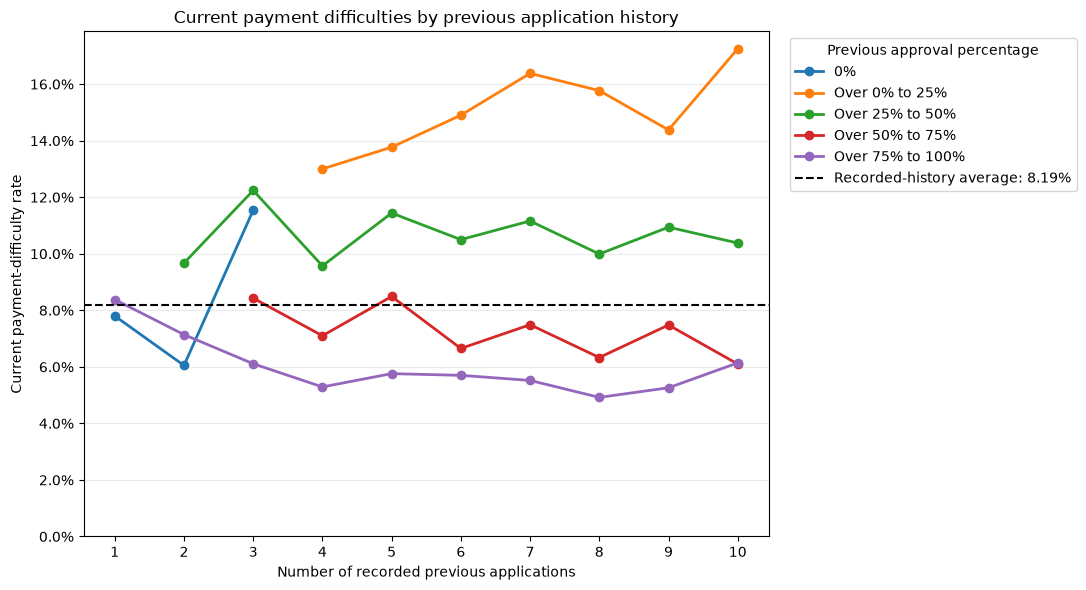

In [127]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Examine history lengths 1–10
plot_counts = count_grid.loc[1:10].copy()
plot_rates = rate_grid.loc[1:10].copy()

# Hide rates supported by fewer than 100 applications
plot_rates = plot_rates.where(plot_counts >= 100)

# Baseline for the same population: applicants with recorded history
baseline = recorded_history["TARGET"].mean() * 100

fig, ax = plt.subplots(figsize=(11, 6))

plot_rates.plot(
    ax=ax,
    marker="o",
    linewidth=2
)

ax.axhline(
    baseline,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Recorded-history average: {baseline:.2f}%"
)

ax.set_title("Current payment difficulties by previous application history")
ax.set_xlabel("Number of recorded previous applications")
ax.set_ylabel("Current payment-difficulty rate")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xticks(plot_rates.index)
ax.set_ylim(bottom=0)

ax.grid(axis="y", alpha=0.25)
ax.legend(
    title="Previous approval percentage",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

fig.tight_layout()
plt.show()

In [128]:
# Search for the bureau CSV, including inside subfolders
bureau_files = [
    file
    for file in data_dir.rglob("*.csv")
    if file.name.lower().startswith("bureau")
    and "balance" not in file.name.lower()
]

print("Matching bureau files:")
for file in bureau_files:
    print(file)

if len(bureau_files) != 1:
    raise ValueError(
        "Could not identify exactly one bureau CSV. "
        "Share the printed filenames."
    )

bureau_ids = pd.read_csv(
    bureau_files[0],
    usecols=["SK_ID_CURR"]
)["SK_ID_CURR"]

Matching bureau files:
C:\home credit data\bureau.csv


In [129]:
# Read external credit-history IDs
bureau_ids = pd.read_csv(
    data_dir / "bureau.csv",
    usecols=["SK_ID_CURR"]
)["SK_ID_CURR"]

credit_history = application_history[
    ["SK_ID_CURR", "TARGET", "PREV_APPLICATIONS"]
].copy()

# Identify recorded Home Credit application history
credit_history["HOME_CREDIT_HISTORY"] = (
    credit_history["PREV_APPLICATIONS"].gt(0).map({
        False: "No previous application recorded",
        True: "Previous application recorded"
    })
)

# Identify recorded external credit history
credit_history["BUREAU_HISTORY"] = (
    credit_history["SK_ID_CURR"].isin(bureau_ids).map({
        False: "No bureau credit recorded",
        True: "Bureau credit recorded"
    })
)

external_history_summary = (
    credit_history
    .groupby(["HOME_CREDIT_HISTORY", "BUREAU_HISTORY"])
    .agg(
        CURRENT_APPLICATIONS=("SK_ID_CURR", "size"),
        DIFFICULTY_CASES=("TARGET", "sum"),
        DIFFICULTY_RATE_PCT=(
            "TARGET", lambda s: s.mean() * 100
        )
    )
)

external_history_summary["DIFFICULTY_RATE_PCT"] = (
    external_history_summary["DIFFICULTY_RATE_PCT"].round(2)
)

display(external_history_summary)

CURRENT_APPLICATIONS  \
HOME_CREDIT_HISTORY              BUREAU_HISTORY                                    
No previous application recorded Bureau credit recorded                    13984   
                                 No bureau credit recorded                  2470   
Previous application recorded    Bureau credit recorded                   249507   
                                 No bureau credit recorded                 41550   

                                                            DIFFICULTY_CASES  \
HOME_CREDIT_HISTORY              BUREAU_HISTORY                                
No previous application recorded Bureau credit recorded                  800   
                                 No bureau credit recorded               180   
Previous application recorded    Bureau credit recorded                19568   
                                 No bureau credit recorded              4277   

                                                            DIFFICULTY_RATE_PCT  
HOME_CREDIT_HISTORY              BUREAU_HISTORY                                  
No previous application recorded Bureau credit recorded                    5.72  
                                 No bureau credit recorded                 7.29  
Previous application recorded    Bureau credit recorded                    7.84  
                                 No bureau credit recorded                10.29

In [130]:
bureau = pd.read_csv(
    bureau_files[0],
    usecols=["SK_ID_CURR", "SK_ID_BUREAU"]
)

# Count distinct external credit records per current application
bureau_counts = (
    bureau.groupby("SK_ID_CURR")["SK_ID_BUREAU"]
    .nunique()
)

bureau_analysis = credit_history.copy()

bureau_analysis["BUREAU_CREDIT_COUNT"] = (
    bureau_analysis["SK_ID_CURR"]
    .map(bureau_counts)
    .fillna(0)
    .astype(int)
)

# Create readable count groups
bureau_analysis["BUREAU_COUNT_BAND"] = pd.cut( 
    bureau_analysis["BUREAU_CREDIT_COUNT"],
    bins=[-1, 0, 1, 2, 5, 10, float("inf")],
    labels=[
        "No bureau credit recorded",
        "1 credit",
        "2 credits",
        "3–5 credits",
        "6–10 credits",
        "11+ credits"
    ]
)

bureau_count_summary = (
    bureau_analysis
    .groupby(
        ["HOME_CREDIT_HISTORY", "BUREAU_COUNT_BAND"],
        observed=True
    )
    .agg(
        CURRENT_APPLICATIONS=("SK_ID_CURR", "size"),
        DIFFICULTY_CASES=("TARGET", "sum"),
        DIFFICULTY_RATE_PCT=(
            "TARGET", lambda s: s.mean() * 100
        )
    )
)

bureau_count_summary["DIFFICULTY_RATE_PCT"] = (
    bureau_count_summary["DIFFICULTY_RATE_PCT"].round(2)
)

display(bureau_count_summary)

CURRENT_APPLICATIONS  \
HOME_CREDIT_HISTORY              BUREAU_COUNT_BAND                                 
No previous application recorded No bureau credit recorded                  2470   
                                 1 credit                                   2743   
                                 2 credits                                  2438   
                                 3–5 credits                                4896   
                                 6–10 credits                               3013   
                                 11+ credits                                 894   
Previous application recorded    No bureau credit recorded                 41550   
                                 1 credit                                  33329   
                                 2 credits                                 33197   
                                 3–5 credits                               81987   
                                 6–10 credits                              69611   
                                 11+ credits                               31383   

                                                            DIFFICULTY_CASES  \
HOME_CREDIT_HISTORY              BUREAU_COUNT_BAND                             
No previous application recorded No bureau credit recorded               180   
                                 1 credit                                141   
                                 2 credits                               128   
                                 3–5 credits                             260   
                                 6–10 credits                            189   
                                 11+ credits                              82   
Previous application recorded    No bureau credit recorded              4277   
                                 1 credit                               2957   
                                 2 credits                              2656   
                                 3–5 credits                            6170   
                                 6–10 credits                           5226   
                                 11+ credits                            2559   

                                                            DIFFICULTY_RATE_PCT  
HOME_CREDIT_HISTORY              BUREAU_COUNT_BAND                               
No previous application recorded No bureau credit recorded                 7.29  
                                 1 credit                                  5.14  
                                 2 credits                                 5.25  
                                 3–5 credits                               5.31  
                                 6–10 credits                              6.27  
                                 11+ credits                               9.17  
Previous application recorded    No bureau credit recorded                10.29  
                                 1 credit                                  8.87  
                                 2 credits                                 8.00  
                                 3–5 credits                               7.53  
                                 6–10 credits                              7.51  
                                 11+ credits                               8.15

In [131]:
  #inspecting the credit statuses
bureau = pd.read_csv(
    bureau_files[0],
    usecols=[
        "SK_ID_CURR",
        "SK_ID_BUREAU",
        "CREDIT_ACTIVE"
    ]
)

display(bureau.head(10))

display(
    bureau["CREDIT_ACTIVE"]
    .value_counts(dropna=False)
    .rename("EXTERNAL_CREDIT_RECORDS")
)

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE
0,215354,5714462,Closed
1,215354,5714463,Active
2,215354,5714464,Active
3,215354,5714465,Active
4,215354,5714466,Active
5,215354,5714467,Active
6,215354,5714468,Active
7,162297,5714469,Closed
8,162297,5714470,Closed
9,162297,5714471,Active


CREDIT_ACTIVE
Closed      1079273
Active       630607
Sold           6527
Bad debt         21
Name: EXTERNAL_CREDIT_RECORDS, dtype: int64

In [132]:
#counting all distinct external credits linked to each current application
total_credit_counts = (
    bureau.groupby("SK_ID_CURR")["SK_ID_BUREAU"]
    .nunique()
    .rename("TOTAL_BUREAU_CREDITS")
)

#selecting the external credits that are recorded as active
active_credits = bureau.loc[
    bureau["CREDIT_ACTIVE"] == "Active"
]

#counting distinct active credits for each current application
active_credit_counts = (
    active_credits.groupby("SK_ID_CURR")["SK_ID_BUREAU"]
    .nunique()
    .rename("ACTIVE_BUREAU_CREDITS")
)

#selecting the external credits that are recorded as closed
closed_credits = bureau.loc[
    bureau["CREDIT_ACTIVE"] == "Closed"
]

#counting distinct closed credits for each current application
closed_credit_counts = (
    closed_credits.groupby("SK_ID_CURR")["SK_ID_BUREAU"]
    .nunique()
    .rename("CLOSED_BUREAU_CREDITS")
)

#combining the counts using the current application ID
bureau_features = (
    total_credit_counts.to_frame()
    .join(active_credit_counts)
    .join(closed_credit_counts)
)

#replacing missing counts with zero where no matching status was recorded
bureau_features = bureau_features.fillna(0).astype(int)

#checking the first ten application-level summaries
display(bureau_features.head(10))

,TOTAL_BUREAU_CREDITS,ACTIVE_BUREAU_CREDITS,CLOSED_BUREAU_CREDITS
SK_ID_CURR,,,
100001,7,3,4
100002,8,2,6
100003,4,1,3
100004,2,0,2
100005,3,2,1
100007,1,0,1
100008,3,1,2
100009,18,4,14
100010,2,1,1


In [133]:
#combining current application outcomes with their external credit summaries
bureau_analysis = application_train[
    ["SK_ID_CURR", "TARGET"]
].merge(
    bureau_features.reset_index(),
    on="SK_ID_CURR",
    how="inner",
    validate="one_to_one"
)

#checking how many current applications have matching bureau history
print("Current applications included:", len(bureau_analysis))

#inspecting the combined data
display(bureau_analysis.head(10))

Current applications included: 263491


,SK_ID_CURR,TARGET,TOTAL_BUREAU_CREDITS,ACTIVE_BUREAU_CREDITS,CLOSED_BUREAU_CREDITS
0,100002,1,8,2,6
1,100003,0,4,1,3
2,100004,0,2,0,2
3,100007,0,1,0,1
4,100008,0,3,1,2
5,100009,0,18,4,14
6,100010,0,2,1,1
7,100011,0,4,0,4
8,100014,0,8,2,6
9,100015,0,4,0,4


In [134]:
#grouping applications by their number of recorded active external credits
active_credit_summary = (
    bureau_analysis
    .groupby("ACTIVE_BUREAU_CREDITS")
    .agg(
        CURRENT_APPLICATIONS=("SK_ID_CURR", "size"),
        KNOWN_OUTCOMES=("TARGET", "count"),
        DIFFICULTY_CASES=("TARGET", "sum"),
        DIFFICULTY_RATE_PCT=(
            "TARGET", lambda s: s.mean() * 100
        )
    )
)

#rounding the difficulty percentages for easier reading
active_credit_summary["DIFFICULTY_RATE_PCT"] = (
    active_credit_summary["DIFFICULTY_RATE_PCT"].round(2)
)

#displaying the results for all observed active-credit counts
display(active_credit_summary)

,CURRENT_APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT
ACTIVE_BUREAU_CREDITS,,,,
0,46341,46341,2621,5.66
1,74103,74103,5260,7.10
2,58383,58383,4346,7.44
3,38011,38011,3140,8.26
4,22041,22041,2035,9.23
5,12051,12051,1285,10.66
6,6107,6107,714,11.69
7,3156,3156,429,13.59
8,1648,1648,226,13.71


In [135]:
#bringing the previous home credit application count into the bureau analysis
bureau_history_analysis = bureau_analysis.merge(
    application_history[
        ["SK_ID_CURR", "PREV_APPLICATIONS"]
    ],
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

#separating applications according to recorded home credit history
bureau_history_analysis["HOME_CREDIT_HISTORY"] = (
    bureau_history_analysis["PREV_APPLICATIONS"]
    .gt(0)
    .map({
        False: "No previous HC application recorded",
        True: "Previous HC application recorded"
    })
)

#combining the sparse high-count groups while keeping all applications
bureau_history_analysis["ACTIVE_CREDIT_BAND"] = pd.cut(
    bureau_history_analysis["ACTIVE_BUREAU_CREDITS"],
    bins=[-1, 0, 1, 2, 3, 4, 5, 10, float("inf")],
    labels=["0", "1", "2", "3", "4", "5", "6–10", "11+"]
)

#comparing current outcomes within each history and active-credit group
history_active_summary = (
    bureau_history_analysis
    .groupby(
        ["HOME_CREDIT_HISTORY", "ACTIVE_CREDIT_BAND"],
        observed=True
    )
    .agg(
        CURRENT_APPLICATIONS=("SK_ID_CURR", "size"),
        DIFFICULTY_CASES=("TARGET", "sum"),
        DIFFICULTY_RATE_PCT=(
            "TARGET", lambda s: s.mean() * 100
        )
    )
)

#rounding the percentages for display
history_active_summary["DIFFICULTY_RATE_PCT"] = (
    history_active_summary["DIFFICULTY_RATE_PCT"].round(2)
)

display(history_active_summary)

CURRENT_APPLICATIONS  \
HOME_CREDIT_HISTORY                 ACTIVE_CREDIT_BAND                         
No previous HC application recorded 0                                   3106   
                                    1                                   4421   
                                    2                                   2889   
                                    3                                   1733   
                                    4                                    913   
                                    5                                    460   
                                    6–10                                 443   
                                    11+                                   19   
Previous HC application recorded    0                                  43235   
                                    1                                  69682   
                                    2                                  55494   
                                    3                                  36278   
                                    4                                  21128   
                                    5                                  11591   
                                    6–10                               11673   
                                    11+                                  426   

                                                        DIFFICULTY_CASES  \
HOME_CREDIT_HISTORY                 ACTIVE_CREDIT_BAND                     
No previous HC application recorded 0                                129   
                                    1                                215   
                                    2                                163   
                                    3                                119   
                                    4                                 65   
                                    5                                 42   
                                    6–10                              60   
                                    11+                                7   
Previous HC application recorded    0                               2492   
                                    1                               5045   
                                    2                               4183   
                                    3                               3021   
                                    4                               1970   
                                    5                               1243   
                                    6–10                            1506   
                                    11+                              108   

                                                        DIFFICULTY_RATE_PCT  
HOME_CREDIT_HISTORY                 ACTIVE_CREDIT_BAND                       
No previous HC application recorded 0                                  4.15  
                                    1                                  4.86  
                                    2                                  5.64  
                                    3                                  6.87  
                                    4                                  7.12  
                                    5                                  9.13  
                                    6–10                              13.54  
                                    11+                               36.84  
Previous HC application recorded    0                                  5.76  
                                    1                                  7.24  
                                    2                                  7.54  
                                    3                                  8.33  
                                    4                                  9.32  
                                    5                                 10.72 

In [136]:
import numpy as np

#rebuilding the statistics using known outcomes as the denominator
stats_summary = (
    bureau_history_analysis
    .groupby(
        ["HOME_CREDIT_HISTORY", "ACTIVE_CREDIT_BAND"],
        observed=True
    )
    .agg(
        KNOWN_OUTCOMES=("TARGET", "count"),
        DIFFICULTY_CASES=("TARGET", "sum")
    )
)

#keeping groups with at least one known outcome
stats_summary = stats_summary.loc[
    stats_summary["KNOWN_OUTCOMES"] > 0
].copy()

#calculating exact percentages before rounding for display
stats_summary["DIFFICULTY_RATE_PCT"] = (
    stats_summary["DIFFICULTY_CASES"]
    / stats_summary["KNOWN_OUTCOMES"]
    * 100
)

#comparing the weighted average with the pooled rate
for history, group in stats_summary.groupby(
    level="HOME_CREDIT_HISTORY"
):
    weighted_rate = np.average(
        group["DIFFICULTY_RATE_PCT"],
        weights=group["KNOWN_OUTCOMES"]
    )

    pooled_rate = (
        group["DIFFICULTY_CASES"].sum()
        / group["KNOWN_OUTCOMES"].sum()
        * 100
    )

    print(history)
    print(f"Weighted rate: {weighted_rate:.2f}%")
    print(f"Pooled rate:   {pooled_rate:.2f}%")
    print()

No previous HC application recorded
Weighted rate: 5.72%
Pooled rate:   5.72%

Previous HC application recorded
Weighted rate: 7.84%
Pooled rate:   7.84%



In [137]:
from statsmodels.stats.proportion import proportion_confint

#calculating wilson confidence intervals for each group
lower, upper = proportion_confint(
    count=stats_summary["DIFFICULTY_CASES"].to_numpy(),
    nobs=stats_summary["KNOWN_OUTCOMES"].to_numpy(),
    alpha=0.05,
    method="wilson"
)

#converting the interval boundaries into percentages
stats_summary["CI_LOWER_PCT"] = lower * 100
stats_summary["CI_UPPER_PCT"] = upper * 100

#displaying rates together with their counts and uncertainty
display(stats_summary.round(2))

KNOWN_OUTCOMES  \
HOME_CREDIT_HISTORY                 ACTIVE_CREDIT_BAND                   
No previous HC application recorded 0                             3106   
                                    1                             4421   
                                    2                             2889   
                                    3                             1733   
                                    4                              913   
                                    5                              460   
                                    6–10                           443   
                                    11+                             19   
Previous HC application recorded    0                            43235   
                                    1                            69682   
                                    2                            55494   
                                    3                            36278   
                                    4                            21128   
                                    5                            11591   
                                    6–10                         11673   
                                    11+                            426   

                                                        DIFFICULTY_CASES  \
HOME_CREDIT_HISTORY                 ACTIVE_CREDIT_BAND                     
No previous HC application recorded 0                                129   
                                    1                                215   
                                    2                                163   
                                    3                                119   
                                    4                                 65   
                                    5                                 42   
                                    6–10                              60   
                                    11+                                7   
Previous HC application recorded    0                               2492   
                                    1                               5045   
                                    2                               4183   
                                    3                               3021   
                                    4                               1970   
                                    5                               1243   
                                    6–10                            1506   
                                    11+                              108   

                                                        DIFFICULTY_RATE_PCT  \
HOME_CREDIT_HISTORY                 ACTIVE_CREDIT_BAND                        
No previous HC application recorded 0                                  4.15   
                                    1                                  4.86   
                                    2                                  5.64   
                                    3                                  6.87   
                                    4                                  7.12   
                                    5                                  9.13   
                                    6–10                              13.54   
                                    11+                               36.84   
Previous HC application recorded    0                                  5.76   
                                    1                                  7.24   
                                    2                                  7.54   
                                    3                                  8.33   
                                    4                                  9.32   
                                    5                                 10.72   
                                    6–10                              12.90   
           

In [138]:
from statsmodels.stats.proportion import proportion_confint

#creating a function to calculate counts, difficulty rates and confidence intervals
def summarise_difficulty(data, group_columns):

    #grouping current applications and counting their known outcomes
    summary = (
        data
        .groupby(group_columns, observed=True)
        .agg(
            CURRENT_APPLICATIONS=("SK_ID_CURR", "size"),
            KNOWN_OUTCOMES=("TARGET", "count"),
            DIFFICULTY_CASES=("TARGET", "sum")
        )
    )

    #keeping groups where an outcome-based rate can be calculated
    summary = summary.loc[
        summary["KNOWN_OUTCOMES"] > 0
    ].copy()

    #calculating the observed difficulty percentage
    summary["DIFFICULTY_RATE_PCT"] = (
        summary["DIFFICULTY_CASES"]
        / summary["KNOWN_OUTCOMES"]
        * 100
    )

    #calculating the lower and upper wilson boundaries
    lower, upper = proportion_confint(
        count=summary["DIFFICULTY_CASES"].to_numpy(),
        nobs=summary["KNOWN_OUTCOMES"].to_numpy(),
        alpha=0.05,
        method="wilson"
    )

    #converting the confidence boundaries to percentages
    summary["CI_LOWER_PCT"] = lower * 100
    summary["CI_UPPER_PCT"] = upper * 100

    return summary

In [139]:
#comparing current outcomes for each previous application count
previous_count_stats = summarise_difficulty(
    application_history,
    ["PREV_APPLICATIONS"]
)

display(previous_count_stats.round(2))

,CURRENT_APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT,CI_LOWER_PCT,CI_UPPER_PCT
PREV_APPLICATIONS,,,,,,
0,16454,16454,980,5.96,5.60,6.33
1,52533,52533,4400,8.38,8.14,8.62
2,45799,45799,3599,7.86,7.62,8.11
3,40014,40014,3126,7.81,7.55,8.08
4,32922,32922,2490,7.56,7.28,7.85
...,...,...,...,...,...,...
64,2,2,0,0.00,0.00,65.76
67,1,1,0,0.00,0.00,79.35
68,1,1,0,0.00,0.00,79.35


In [140]:
#selecting applications with recorded previous home credit applications
previous_analysis = application_history.loc[
    application_history["PREV_APPLICATIONS"] > 0
].copy()

#separating applicants according to whether any previous approval is recorded
previous_analysis["APPROVAL_HISTORY"] = (
    previous_analysis["PREV_APPROVED"]
    .gt(0)
    .map({
        False: "No previous approvals",
        True: "At least one previous approval"
    })
)

#comparing the current difficulty rates and confidence intervals
approval_history_stats = summarise_difficulty(
    previous_analysis,
    ["APPROVAL_HISTORY"]
)

display(approval_history_stats.round(2))

,CURRENT_APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT,CI_LOWER_PCT,CI_UPPER_PCT
APPROVAL_HISTORY,,,,,,
At least one previous approval,290065,290065,23759,8.19,8.09,8.29
No previous approvals,992,992,86,8.67,7.07,10.58


In [141]:
#calculating the share of previous applications that were approved
previous_analysis["PREV_APPROVAL_PCT"] = (
    previous_analysis["PREV_APPROVED"]
    / previous_analysis["PREV_APPLICATIONS"]
    * 100
)

#creating the approval-percentage bands
previous_analysis["APPROVAL_BAND"] = pd.cut(
    previous_analysis["PREV_APPROVAL_PCT"],
    bins=[-1, 0, 25, 50, 75, 100],
    labels=[
        "0%",
        "Over 0% to 25%",
        "Over 25% to 50%",
        "Over 50% to 75%",
        "Over 75% to 100%"
    ]
)

#comparing current outcomes across approval-percentage bands
approval_band_stats = summarise_difficulty(
    previous_analysis,
    ["APPROVAL_BAND"]
)

display(approval_band_stats.round(2))

,CURRENT_APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT,CI_LOWER_PCT,CI_UPPER_PCT
APPROVAL_BAND,,,,,,
0%,992,992,86,8.67,7.07,10.58
Over 0% to 25%,12515,12515,1834,14.65,14.05,15.28
Over 25% to 50%,64071,64071,6677,10.42,10.19,10.66
Over 50% to 75%,64927,64927,4917,7.57,7.37,7.78
Over 75% to 100%,148552,148552,10331,6.95,6.83,7.08


In [142]:
#pooling the approval bands using their underlying counts
overall_rate = (
    approval_band_stats["DIFFICULTY_CASES"].sum()
    / approval_band_stats["KNOWN_OUTCOMES"].sum()
    * 100
)

print(f"Overall rate for recorded previous history: {overall_rate:.2f}%")

Overall rate for recorded previous history: 8.19%


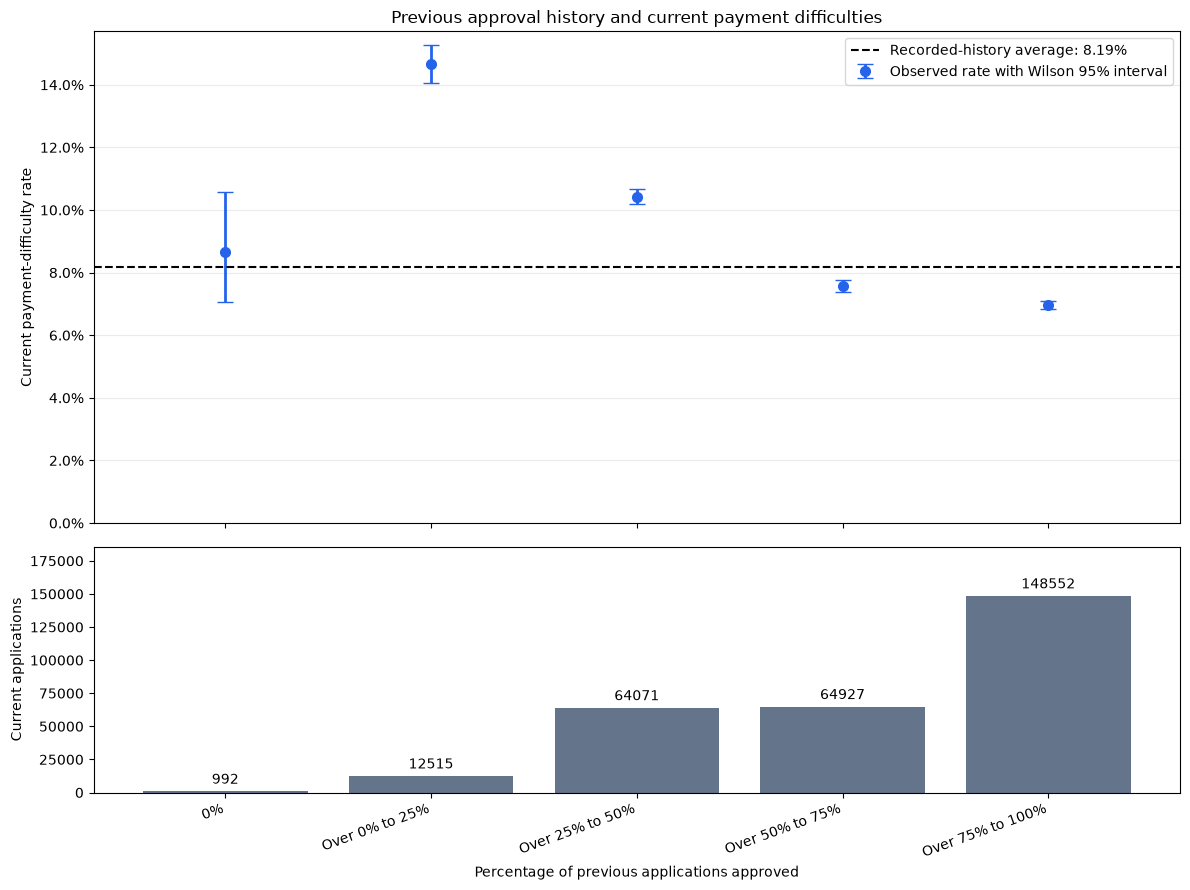

In [143]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

#using the unrounded statistics calculated in the previous cell
plot_stats = approval_band_stats.copy()

#setting the position of each approval band on the x axis
positions = list(range(len(plot_stats)))
labels = plot_stats.index.astype(str)

rates = plot_stats["DIFFICULTY_RATE_PCT"]

#calculating the distance from each rate to its confidence boundaries
lower_errors = (
    rates - plot_stats["CI_LOWER_PCT"]
).clip(lower=0)

upper_errors = (
    plot_stats["CI_UPPER_PCT"] - rates
).clip(lower=0)

#calculating the pooled rate for the same population
baseline = (
    plot_stats["DIFFICULTY_CASES"].sum()
    / plot_stats["KNOWN_OUTCOMES"].sum()
    * 100
)

#creating a rate plot above an application-count plot
fig, (ax_rate, ax_count) = plt.subplots(
    2, 1,
    figsize=(12, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

#plotting observed rates with their wilson confidence intervals
ax_rate.errorbar(
    positions,
    rates,
    yerr=[
        lower_errors.to_numpy(),
        upper_errors.to_numpy()
    ],
    fmt="o",
    color="#2563eb",
    markersize=7,
    capsize=6,
    elinewidth=2,
    label="Observed rate with Wilson 95% interval"
)

#adding the pooled difficulty rate as a reference
ax_rate.axhline(
    baseline,
    color="black",
    linestyle="--",
    label=f"Recorded-history average: {baseline:.2f}%"
)

ax_rate.set_title(
    "Previous approval history and current payment difficulties"
)
ax_rate.set_ylabel("Current payment-difficulty rate")
ax_rate.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax_rate.set_ylim(bottom=0)
ax_rate.grid(axis="y", alpha=0.25)
ax_rate.legend()

#showing how many current applications support each rate
bars = ax_count.bar(
    positions,
    plot_stats["CURRENT_APPLICATIONS"],
    color="#64748b"
)

ax_count.bar_label(bars, fmt="%.0f", padding=3)
ax_count.set_ylabel("Current applications")
ax_count.set_xlabel("Percentage of previous applications approved")
ax_count.set_xticks(positions)
ax_count.set_xticklabels(labels, rotation=20, ha="right")
ax_count.margins(y=0.25)

fig.tight_layout()
plt.show()

In [144]:
#Do applicants with recorded overdue external credit have a higher current payment-difficulty rate?
#reading the overdue information for external credits
bureau_overdue = pd.read_csv(
    bureau_files[0],
    usecols=[
        "SK_ID_CURR",
        "SK_ID_BUREAU",
        "CREDIT_DAY_OVERDUE"
    ]
)

#checking the original credit-level records
display(bureau_overdue.head(10))

#summarising the overdue information for each current application
overdue_features = (
    bureau_overdue
    .groupby("SK_ID_CURR")
    .agg(
        BUREAU_RECORDS=("SK_ID_BUREAU", "size"),
        KNOWN_OVERDUE_RECORDS=("CREDIT_DAY_OVERDUE", "count"),
        MAX_OVERDUE_DAYS=("CREDIT_DAY_OVERDUE", "max")
    )
)

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_DAY_OVERDUE
0,215354,5714462,0
1,215354,5714463,0
2,215354,5714464,0
3,215354,5714465,0
4,215354,5714466,0
5,215354,5714467,0
6,215354,5714468,0
7,162297,5714469,0
8,162297,5714470,0
9,162297,5714471,0


In [145]:
#starting with an unknown classification where information is incomplete
overdue_features["OVERDUE_GROUP"] = (
    "Incomplete overdue information"
)

#checking whether overdue information is available for every record
all_records_known = (
    overdue_features["KNOWN_OVERDUE_RECORDS"]
    == overdue_features["BUREAU_RECORDS"]
)

#identifying applicants whose records all show zero overdue days
overdue_features.loc[
    all_records_known
    & overdue_features["MAX_OVERDUE_DAYS"].eq(0),
    "OVERDUE_GROUP"
] = "All bureau records show zero overdue days"

#identifying applicants with at least one recorded overdue credit
overdue_features.loc[
    overdue_features["MAX_OVERDUE_DAYS"] > 0,
    "OVERDUE_GROUP"
] = "At least one bureau credit overdue"

In [146]:
#attaching the bureau summaries to the current application outcomes
overdue_analysis = application_train[
    ["SK_ID_CURR", "TARGET"]
].merge(
    overdue_features.reset_index(),
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

#keeping applications without matching bureau history as a separate group
overdue_analysis.loc[
    overdue_analysis["BUREAU_RECORDS"].isna(),
    "OVERDUE_GROUP"
] = "No bureau credit recorded"

#using our earlier function to calculate rates and confidence intervals
overdue_summary = summarise_difficulty(
    overdue_analysis,
    ["OVERDUE_GROUP"]
)

display(overdue_summary.round(2))

,CURRENT_APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT,CI_LOWER_PCT,CI_UPPER_PCT
OVERDUE_GROUP,,,,,,
All bureau records show zero overdue days,260094,260094,19828,7.62,7.52,7.73
At least one bureau credit overdue,3397,3397,540,15.90,14.71,17.16
No bureau credit recorded,44020,44020,4457,10.12,9.85,10.41


In [147]:
#Our previous comparison separated “overdue” from “not overdue.” But 
#2 days overdue and 120 days overdue describe different situations.


In [148]:
#copying the application-level overdue analysis
severity_analysis = overdue_analysis.copy()

#grouping applications by their largest recorded overdue-days value
severity_analysis["OVERDUE_SEVERITY"] = pd.cut(
    severity_analysis["MAX_OVERDUE_DAYS"],
    bins=[-1, 0, 7, 30, 90, float("inf")],
    labels=[
        "Zero overdue days",
        "1–7 days",
        "8–30 days",
        "31–90 days",
        "91+ days"
    ]
).astype("object")

#keeping incomplete information separate from confirmed zero overdue days
severity_analysis.loc[
    severity_analysis["OVERDUE_GROUP"]
    == "Incomplete overdue information",
    "OVERDUE_SEVERITY"
] = "Incomplete overdue information"

#keeping applications without bureau records separate
severity_analysis.loc[
    severity_analysis["OVERDUE_GROUP"]
    == "No bureau credit recorded",
    "OVERDUE_SEVERITY"
] = "No bureau credit recorded"

#calculating current difficulty rates and wilson confidence intervals
severity_summary = summarise_difficulty(
    severity_analysis,
    ["OVERDUE_SEVERITY"]
)

#arranging the results in a meaningful order
severity_order = [
    "Zero overdue days",
    "1–7 days",
    "8–30 days",
    "31–90 days",
    "91+ days",
    "Incomplete overdue information",
    "No bureau credit recorded"
]

severity_summary = severity_summary.reindex(
    [group for group in severity_order
     if group in severity_summary.index]
)

display(severity_summary.round(2))
#using maximum overdue to capture most severe onserved observed overdue

,CURRENT_APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT,CI_LOWER_PCT,CI_UPPER_PCT
OVERDUE_SEVERITY,,,,,,
Zero overdue days,260094,260094,19828,7.62,7.52,7.73
1–7 days,206,206,42,20.39,15.45,26.41
8–30 days,1317,1317,238,18.07,16.09,20.24
31–90 days,790,790,137,17.34,14.86,20.14
91+ days,1084,1084,123,11.35,9.59,13.37
No bureau credit recorded,44020,44020,4457,10.12,9.85,10.41


In [149]:
#reading the overdue days and status of each external credit
bureau_detail = pd.read_csv(
    bureau_files[0],
    usecols=[
        "SK_ID_CURR",
        "SK_ID_BUREAU",
        "CREDIT_ACTIVE",
        "CREDIT_DAY_OVERDUE"
    ]
)

#selecting external credit records with positive overdue days
overdue_credit_records = bureau_detail.loc[
    bureau_detail["CREDIT_DAY_OVERDUE"] > 0
].copy()

#grouping these credit records by overdue severity
overdue_credit_records["OVERDUE_BAND"] = pd.cut(
    overdue_credit_records["CREDIT_DAY_OVERDUE"],
    bins=[0, 7, 30, 90, float("inf")],
    labels=["1–7 days", "8–30 days", "31–90 days", "91+ days"]
)

#keeping missing credit statuses visible
overdue_credit_records["CREDIT_ACTIVE"] = (
    overdue_credit_records["CREDIT_ACTIVE"]
    .fillna("Unknown status")
)

#counting external credit records within each severity and status combination
status_counts = pd.crosstab(
    overdue_credit_records["OVERDUE_BAND"],
    overdue_credit_records["CREDIT_ACTIVE"]
)

#calculating the status percentages within each overdue range
status_percentages = (
    status_counts
    .div(status_counts.sum(axis=1), axis=0)
    * 100
)

print("External credit record counts:")
display(status_counts)

print("Status percentages within each overdue range:")
display(status_percentages.round(2))

External credit record counts:


CREDIT_ACTIVE,Active,Bad debt,Closed,Sold
OVERDUE_BAND,,,,
1–7 days,298,0,2,0
8–30 days,1708,1,2,0
31–90 days,932,0,0,0
91+ days,1106,9,79,80


Status percentages within each overdue range:


CREDIT_ACTIVE,Active,Bad debt,Closed,Sold
OVERDUE_BAND,,,,
1–7 days,99.33,0.00,0.67,0.00
8–30 days,99.82,0.06,0.12,0.00
31–90 days,100.00,0.00,0.00,0.00
91+ days,86.81,0.71,6.20,6.28


In [150]:
#selecting only external credits recorded as active
active_bureau = bureau_detail.loc[
    bureau_detail["CREDIT_ACTIVE"] == "Active"
].copy()

#summarising active-credit overdue information for each current application
active_overdue_features = (
    active_bureau
    .groupby("SK_ID_CURR")
    .agg(
        ACTIVE_RECORDS=("SK_ID_BUREAU", "size"),
        KNOWN_OVERDUE_RECORDS=("CREDIT_DAY_OVERDUE", "count"),
        MAX_ACTIVE_OVERDUE_DAYS=("CREDIT_DAY_OVERDUE", "max")
    )
)

#matching the summaries to current applications with known target labels
active_overdue_analysis = application_train[
    ["SK_ID_CURR", "TARGET"]
].merge(
    active_overdue_features.reset_index(),
    on="SK_ID_CURR",
    how="inner",
    validate="one_to_one"
)

#grouping applications by the largest observed overdue value on active credits
active_overdue_analysis["ACTIVE_OVERDUE_SEVERITY"] = pd.cut(
    active_overdue_analysis["MAX_ACTIVE_OVERDUE_DAYS"],
    bins=[-1, 0, 7, 30, 90, float("inf")],
    labels=[
        "Zero overdue days",
        "1–7 days",
        "8–30 days",
        "31–90 days",
        "91+ days"
    ]
).astype("object")

#identifying applications with some missing overdue information
incomplete_information = (
    active_overdue_analysis["KNOWN_OVERDUE_RECORDS"]
    < active_overdue_analysis["ACTIVE_RECORDS"]
)

#avoiding a confirmed-zero label when some active-credit values are missing
active_overdue_analysis.loc[
    incomplete_information
    & active_overdue_analysis["MAX_ACTIVE_OVERDUE_DAYS"].eq(0),
    "ACTIVE_OVERDUE_SEVERITY"
] = "Incomplete overdue information"

#labelling applications where no overdue-days value is available
active_overdue_analysis["ACTIVE_OVERDUE_SEVERITY"] = (
    active_overdue_analysis["ACTIVE_OVERDUE_SEVERITY"]
    .fillna("Incomplete or unclassified overdue information")
)

#calculating current difficulty rates and wilson confidence intervals
active_severity_summary = summarise_difficulty(
    active_overdue_analysis,
    ["ACTIVE_OVERDUE_SEVERITY"]
)

#displaying the groups in severity order
severity_order = [
    "Zero overdue days",
    "1–7 days",
    "8–30 days",
    "31–90 days",
    "91+ days",
    "Incomplete overdue information",
    "Incomplete or unclassified overdue information"
]

active_severity_summary = active_severity_summary.reindex(
    [group for group in severity_order
     if group in active_severity_summary.index]
)

display(active_severity_summary.round(2))

,CURRENT_APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT,CI_LOWER_PCT,CI_UPPER_PCT
ACTIVE_OVERDUE_SEVERITY,,,,,,
Zero overdue days,213900,213900,17224,8.05,7.94,8.17
1–7 days,206,206,42,20.39,15.45,26.41
8–30 days,1317,1317,237,18.00,16.01,20.16
31–90 days,791,791,137,17.32,14.84,20.11
91+ days,936,936,107,11.43,9.55,13.63


In [151]:
#finding the instalment-payment csv inside the data folder
installment_files = [
    file
    for file in data_dir.rglob("*.csv")
    if file.name.lower().startswith("installments_payments")
]

#checking that exactly one matching file is available
if len(installment_files) != 1:
    raise ValueError(
        f"Expected one instalment-payment CSV. Found: {installment_files}"
    )

#reading ten rows to understand the structure before loading more data
installment_preview = pd.read_csv(
    installment_files[0],
    usecols=[
        "SK_ID_CURR",
        "SK_ID_PREV",
        "NUM_INSTALMENT_VERSION",
        "NUM_INSTALMENT_NUMBER",
        "DAYS_INSTALMENT",
        "DAYS_ENTRY_PAYMENT",
        "AMT_INSTALMENT",
        "AMT_PAYMENT"
    ],
    nrows=10
)

display(installment_preview)

,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585
5,1137312,164489,1.0,12,-1384.0,-1417.0,5970.375,5970.375
6,2234264,184693,4.0,11,-349.0,-352.0,29432.295,29432.295
7,1818599,111420,2.0,4,-968.0,-994.0,17862.165,17862.165
8,2723183,112102,0.0,14,-197.0,-197.0,70.740,70.740
9,1413990,109741,1.0,4,-570.0,-609.0,14308.470,14308.470


In [152]:
#calculating whether each recorded payment was before or after its due date
installment_preview["PAYMENT_DATE_GAP_DAYS"] = (
    installment_preview["DAYS_ENTRY_PAYMENT"]
    - installment_preview["DAYS_INSTALMENT"]
)

#comparing each recorded payment with the scheduled instalment amount
installment_preview["SCHEDULED_MINUS_THIS_PAYMENT"] = (
    installment_preview["AMT_INSTALMENT"]
    - installment_preview["AMT_PAYMENT"]
)

#inspecting the payment dates and amounts together
display(
    installment_preview[
        [
            "SK_ID_CURR",
            "SK_ID_PREV",
            "NUM_INSTALMENT_NUMBER",
            "PAYMENT_DATE_GAP_DAYS",
            "SCHEDULED_MINUS_THIS_PAYMENT"
        ]
    ]
)

,SK_ID_CURR,SK_ID_PREV,NUM_INSTALMENT_NUMBER,PAYMENT_DATE_GAP_DAYS,SCHEDULED_MINUS_THIS_PAYMENT
0,161674,1054186,6,-7.0,0.000
1,151639,1330831,34,0.0,0.000
2,193053,2085231,1,0.0,0.000
3,199697,2452527,3,-8.0,0.000
4,167756,2714724,2,17.0,4.455
5,164489,1137312,12,-33.0,0.000
6,184693,2234264,11,-3.0,0.000
7,111420,1818599,4,-26.0,0.000
8,112102,2723183,14,0.0,0.000
9,109741,1413990,4,-39.0,0.000


In [153]:
#choosing the columns needed to inspect the payment records
payment_columns = [
    "SK_ID_CURR",
    "SK_ID_PREV",
    "NUM_INSTALMENT_VERSION",
    "NUM_INSTALMENT_NUMBER",
    "DAYS_INSTALMENT",
    "DAYS_ENTRY_PAYMENT",
    "AMT_INSTALMENT",
    "AMT_PAYMENT"
]

#collecting all matching records from the complete file
matching_parts = []

#reading in chunks to avoid loading the entire large file into memory
for chunk in pd.read_csv(
    installment_files[0],
    usecols=payment_columns,
    chunksize=300_000
):
    matching_rows = chunk.loc[
        (chunk["SK_ID_CURR"] == 167756)
        & (chunk["SK_ID_PREV"] == 2714724)
        & (chunk["NUM_INSTALMENT_VERSION"] == 1)
        & (chunk["NUM_INSTALMENT_NUMBER"] == 2)
        & (chunk["DAYS_INSTALMENT"] == -1383)
    ]

    if not matching_rows.empty:
        matching_parts.append(matching_rows.copy())

#combining and displaying all records for this instalment
if matching_parts:
    example_instalment = (
        pd.concat(matching_parts, ignore_index=True)
        .sort_values("DAYS_ENTRY_PAYMENT")
    )

    display(example_instalment)

    print(
        "Total recorded payments:",
        example_instalment["AMT_PAYMENT"].sum(min_count=1)
    )
else:
    print("No matching records found.")

,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
1,2714724,167756,1.0,2,-1383.0,-1421.0,2165.04,4.455
0,2714724,167756,1.0,2,-1383.0,-1366.0,2165.04,2160.585


Total recorded payments: 2165.04


In [154]:
#checking that the instalment has one consistent scheduled amount
scheduled_amounts = (
    example_instalment["AMT_INSTALMENT"]
    .dropna()
    .unique()
)

if len(scheduled_amounts) != 1:
    raise ValueError("Inspect the scheduled amounts before continuing.")

#checking that payment amounts and dates are available
if example_instalment[
    ["AMT_PAYMENT", "DAYS_ENTRY_PAYMENT"]
].isna().any().any():
    raise ValueError("Some payment amounts or dates are missing.")

#arranging the payments from earliest to latest
payment_check = (
    example_instalment
    .sort_values("DAYS_ENTRY_PAYMENT")
    .copy()
)

#keeping payments recorded on or before the current application date
payment_check = payment_check.loc[
    payment_check["DAYS_ENTRY_PAYMENT"] <= 0
].copy()

if payment_check.empty:
    raise ValueError("No dated payments are available before the cutoff.")

#calculating how much had been paid after each recorded payment
payment_check["CUMULATIVE_PAYMENT"] = (
    payment_check["AMT_PAYMENT"].cumsum()
)

#comparing the total recorded payments with the scheduled amount
scheduled_amount = scheduled_amounts[0]
total_paid = payment_check["AMT_PAYMENT"].sum()
difference = scheduled_amount - total_paid

display(
    payment_check[
        [
            "DAYS_INSTALMENT",
            "DAYS_ENTRY_PAYMENT",
            "AMT_INSTALMENT",
            "AMT_PAYMENT",
            "CUMULATIVE_PAYMENT"
        ]
    ]
)

print(f"Scheduled amount: {scheduled_amount:.3f}")
print(f"Total recorded payments by application date: {total_paid:.3f}")
print(f"Scheduled minus total paid: {difference:.3f}")

,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT,CUMULATIVE_PAYMENT
1,-1383.0,-1421.0,2165.04,4.455,4.455
0,-1383.0,-1366.0,2165.04,2160.585,2165.040


Scheduled amount: 2165.040
Total recorded payments by application date: 2165.040
Scheduled minus total paid: 0.000


In [155]:
#checking that there is one consistent due date
due_dates = payment_check["DAYS_INSTALMENT"].dropna().unique()

if (
    len(due_dates) != 1
    or payment_check["DAYS_INSTALMENT"].isna().any()
):
    raise ValueError("Inspect the instalment due dates before continuing.")

due_day = due_dates[0]

#checking for negative payments that would need separate investigation
if payment_check["AMT_PAYMENT"].lt(0).any():
    raise ValueError("Negative payments found. Inspect these before continuing.")

#calculating how much was recorded as paid by the due date
paid_by_due = payment_check.loc[
    payment_check["DAYS_ENTRY_PAYMENT"] <= due_day,
    "AMT_PAYMENT"
].sum()

#allowing only a tiny tolerance for floating-point arithmetic
tolerance = 0.000001

#finding when cumulative payments first covered the scheduled amount
covered_rows = payment_check.loc[
    payment_check["CUMULATIVE_PAYMENT"]
    >= scheduled_amount - tolerance
]

print(f"Scheduled amount: {scheduled_amount:.3f}")
print(f"Amount recorded as paid by due date: {paid_by_due:.3f}")

if covered_rows.empty:
    print("The recorded payments do not fully cover this instalment by the application date.")

else:
    first_covered_day = covered_rows["DAYS_ENTRY_PAYMENT"].iloc[0]

    #comparing the first full-coverage date with the due date
    coverage_gap = first_covered_day - due_day

    print("Due day:", due_day)
    print("First full-coverage day:", first_covered_day)

    if coverage_gap > 0:
        print(f"The instalment was fully covered {coverage_gap:.0f} days late.")
    elif coverage_gap < 0:
        print(f"The instalment was fully covered {-coverage_gap:.0f} days early.")
    else:
        print("The instalment was fully covered on its due date.")

Scheduled amount: 2165.040
Amount recorded as paid by due date: 4.455
Due day: -1383.0
First full-coverage day: -1366.0
The instalment was fully covered 17 days late.


In [156]:
#selecting the current application from our earlier example
application_to_inspect = 167756

#collecting all payment records linked to this application
applicant_parts = []

#searching the complete file in manageable chunks
for chunk in pd.read_csv(
    installment_files[0],
    usecols=payment_columns,
    chunksize=300_000
):
    matching_rows = chunk.loc[
        chunk["SK_ID_CURR"] == application_to_inspect
    ]

    if not matching_rows.empty:
        applicant_parts.append(matching_rows.copy())

if not applicant_parts:
    raise ValueError("No payment records found for this application.")

#combining the applicant's records
applicant_payments = pd.concat(
    applicant_parts,
    ignore_index=True
)

#checking how many records and previous credits are represented
print("Payment-related records:", len(applicant_payments))

print(
    "Distinct previous credit IDs:",
    applicant_payments["SK_ID_PREV"].nunique()
)

display(applicant_payments.head(10))

Payment-related records: 30
Distinct previous credit IDs: 3


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585
1,1542252,167756,1.0,9,-807.0,-805.0,2390.265,1711.800
2,1542252,167756,1.0,7,-867.0,-862.0,2390.265,1881.270
3,1542252,167756,1.0,4,-957.0,-957.0,2390.265,2390.265
4,1542252,167756,1.0,1,-1047.0,-1044.0,2390.265,2389.680
5,2714724,167756,1.0,3,-1353.0,-1366.0,2165.040,8.415
6,1542252,167756,1.0,10,-777.0,-771.0,2390.265,1627.065
7,1542251,167756,1.0,1,-1863.0,-1868.0,4849.065,4849.065
8,1542251,167756,1.0,6,-1713.0,-1716.0,4849.065,4849.065
9,1542251,167756,1.0,3,-1803.0,-1807.0,4849.065,4849.065


In [157]:
#identifying each instalment within its loan and schedule version
instalment_keys = [
    "SK_ID_CURR",
    "SK_ID_PREV",
    "NUM_INSTALMENT_VERSION",
    "NUM_INSTALMENT_NUMBER",
    "DAYS_INSTALMENT"
]

#checking the payment records associated with each instalment schedule entry
instalment_audit = (
    applicant_payments
    .groupby(instalment_keys, dropna=False)
    .agg(
        PAYMENT_RECORDS=("AMT_PAYMENT", "size"),
        KNOWN_PAYMENT_AMOUNTS=("AMT_PAYMENT", "count"),
        DISTINCT_SCHEDULED_AMOUNTS=("AMT_INSTALMENT", "nunique"),
        SCHEDULED_AMOUNT=("AMT_INSTALMENT", "first"),
        RECORDED_PAYMENT_TOTAL=(
            "AMT_PAYMENT",
            lambda s: s.sum(min_count=1)
        )
    )
    .reset_index()
)

#displaying entries with multiple payment records
multiple_payment_entries = instalment_audit.loc[
    instalment_audit["PAYMENT_RECORDS"] > 1
]

print("Instalment schedule entries:", len(instalment_audit))

print(
    "Entries with multiple payment records:",
    len(multiple_payment_entries)
)

display(multiple_payment_entries.head(10))

Instalment schedule entries: 22
Entries with multiple payment records: 8


,SK_ID_CURR,SK_ID_PREV,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,PAYMENT_RECORDS,KNOWN_PAYMENT_AMOUNTS,DISTINCT_SCHEDULED_AMOUNTS,SCHEDULED_AMOUNT,RECORDED_PAYMENT_TOTAL
7,167756,1542252,1.0,1,-1047.0,2,2,1,2390.265,2390.265
12,167756,1542252,1.0,6,-897.0,2,2,1,2390.265,2390.265
13,167756,1542252,1.0,7,-867.0,2,2,1,2390.265,2390.265
14,167756,1542252,1.0,8,-837.0,2,2,1,2390.265,2390.265
15,167756,1542252,1.0,9,-807.0,2,2,1,2390.265,2390.265
16,167756,1542252,1.0,10,-777.0,2,2,1,2390.265,2390.265
19,167756,2714724,1.0,2,-1383.0,2,2,1,2165.040,2165.040
20,167756,2714724,1.0,3,-1353.0,2,2,1,2165.040,2165.040


In [158]:
#storing one result for each instalment schedule entry
instalment_results = []

#allowing a tiny tolerance for floating-point arithmetic
tolerance = 0.000001

#examining all payment records belonging to each schedule entry
for keys, records in applicant_payments.groupby(
    instalment_keys,
    dropna=False
):
    result = dict(zip(instalment_keys, keys))
    result["PAYMENT_RECORDS"] = len(records)

    due_day = result["DAYS_INSTALMENT"]
    amounts = records["AMT_INSTALMENT"].dropna().unique()

    #checking that the due date and scheduled amount are usable
    if (
        pd.isna(due_day)
        or len(amounts) != 1
        or records["AMT_INSTALMENT"].isna().any()
        or amounts[0] <= 0
    ):
        result["PAYMENT_STATUS"] = "Review required"

    #keeping obligations due today or later separate from past-due obligations
    elif due_day >= 0:
        result["PAYMENT_STATUS"] = "Due today or later"

    #avoiding a definite classification when payment information is missing
    elif records[
        ["AMT_PAYMENT", "DAYS_ENTRY_PAYMENT"]
    ].isna().any().any():
        result["PAYMENT_STATUS"] = "Review required"

    else:
        scheduled = amounts[0]

        #using only payments recorded by the current application date
        eligible = records.loc[
            records["DAYS_ENTRY_PAYMENT"] <= 0
        ].copy()

        #leaving negative payments for separate investigation
        if eligible["AMT_PAYMENT"].lt(0).any():
            result["PAYMENT_STATUS"] = "Review required"

        else:
            #combining payments made on the same day and ordering the dates
            daily_payments = (
                eligible.groupby("DAYS_ENTRY_PAYMENT")["AMT_PAYMENT"]
                .sum()
                .sort_index()
            )

            #calculating the running total across payment dates
            cumulative_paid = daily_payments.cumsum()

            result["SCHEDULED_AMOUNT"] = scheduled
            result["PAID_BY_CUTOFF"] = daily_payments.sum()

            #finding the first date when the scheduled amount was covered
            covered = cumulative_paid.loc[
                cumulative_paid >= scheduled - tolerance
            ]

            if covered.empty:
                result["PAYMENT_STATUS"] = "Not fully covered by cutoff"

            else:
                coverage_day = covered.index[0]
                date_gap = coverage_day - due_day

                result["FIRST_COVERED_DAY"] = coverage_day
                result["COVERAGE_GAP_DAYS"] = date_gap

                if date_gap > 0:
                    result["PAYMENT_STATUS"] = "Covered late"
                else:
                    result["PAYMENT_STATUS"] = "Covered on time or early"

    instalment_results.append(result)

#turning the results into a table
applicant_instalment_summary = pd.DataFrame(instalment_results)

display(
    applicant_instalment_summary.sort_values(
        ["SK_ID_PREV", "DAYS_INSTALMENT"]
    )
)

,SK_ID_CURR,SK_ID_PREV,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,PAYMENT_RECORDS,SCHEDULED_AMOUNT,PAID_BY_CUTOFF,FIRST_COVERED_DAY,COVERAGE_GAP_DAYS,PAYMENT_STATUS
0,167756,1542251,1.0,1,-1863.0,1,4849.065,4849.065,-1868.0,-5.0,Covered on time or early
1,167756,1542251,1.0,2,-1833.0,1,4849.065,4849.065,-1835.0,-2.0,Covered on time or early
2,167756,1542251,1.0,3,-1803.0,1,4849.065,4849.065,-1807.0,-4.0,Covered on time or early
3,167756,1542251,1.0,4,-1773.0,1,4849.065,4849.065,-1778.0,-5.0,Covered on time or early
4,167756,1542251,1.0,5,-1743.0,1,4849.065,4849.065,-1743.0,0.0,Covered on time or early
5,167756,1542251,1.0,6,-1713.0,1,4849.065,4849.065,-1716.0,-3.0,Covered on time or early
6,167756,1542251,2.0,7,-1683.0,1,31097.295,31097.295,-1703.0,-20.0,Covered on time or early
7,167756,1542252,1.0,1,-1047.0,2,2390.265,2390.265,-1044.0,3.0,Covered late
8,167756,1542252,1.0,2,-1017.0,1,2390.265,2390.265,-1018.0,-1.0,Covered on time or early
9,167756,1542252,1.0,3,-987.0,1,2390.265,2390.265,-988.0,-1.0,Covered on time or early


In [159]:
#checking which schedule versions are recorded for each previous credit
version_audit = (
    applicant_payments
    .groupby(["SK_ID_CURR", "SK_ID_PREV"])
    .agg(
        PAYMENT_RECORDS=("NUM_INSTALMENT_VERSION", "size"),
        DISTINCT_VERSIONS=("NUM_INSTALMENT_VERSION", "nunique"),
        RECORDED_VERSIONS=(
            "NUM_INSTALMENT_VERSION",
            lambda s: sorted(s.dropna().unique().tolist())
        )
    )
    .reset_index()
)

display(version_audit)

,SK_ID_CURR,SK_ID_PREV,PAYMENT_RECORDS,DISTINCT_VERSIONS,RECORDED_VERSIONS
0,167756,1542251,7,2,"[1.0, 2.0]"
1,167756,1542252,17,2,"[1.0, 2.0]"
2,167756,2714724,6,2,"[1.0, 2.0]"


In [160]:
#checking schedule consistency within each previous credit and instalment number
schedule_audit = (
    applicant_payments
    .groupby(
        ["SK_ID_CURR", "SK_ID_PREV", "NUM_INSTALMENT_NUMBER"],
        dropna=False
    )
    .agg(
        DISTINCT_VERSIONS=("NUM_INSTALMENT_VERSION", "nunique"),
        DISTINCT_DUE_DATES=("DAYS_INSTALMENT", "nunique"),
        PAYMENT_RECORDS=("AMT_PAYMENT", "size")
    )
    .reset_index()
)

#identifying entries that need investigation before counting obligations
schedule_review = schedule_audit.loc[
    (schedule_audit["DISTINCT_VERSIONS"] > 1)
    | (schedule_audit["DISTINCT_DUE_DATES"] > 1)
]

print("Instalment numbers requiring schedule review:", len(schedule_review))
display(schedule_review)

Instalment numbers requiring schedule review: 0


,SK_ID_CURR,SK_ID_PREV,NUM_INSTALMENT_NUMBER,DISTINCT_VERSIONS,DISTINCT_DUE_DATES,PAYMENT_RECORDS


In [161]:
#attaching the schedule checks to our classified instalment entries
checked_instalments = applicant_instalment_summary.merge(
    schedule_audit[
        [
            "SK_ID_CURR",
            "SK_ID_PREV",
            "NUM_INSTALMENT_NUMBER",
            "DISTINCT_VERSIONS",
            "DISTINCT_DUE_DATES"
        ]
    ],
    on=["SK_ID_CURR", "SK_ID_PREV", "NUM_INSTALMENT_NUMBER"],
    how="left",
    validate="many_to_one"
)

#keeping identifiable non-card entries without detected schedule conflicts
eligible_entries = checked_instalments.loc[
    checked_instalments[
        ["SK_ID_CURR", "SK_ID_PREV", "NUM_INSTALMENT_NUMBER"]
    ].notna().all(axis=1)
    & checked_instalments["NUM_INSTALMENT_VERSION"].gt(0)
    & checked_instalments["DISTINCT_VERSIONS"].eq(1)
    & checked_instalments["DISTINCT_DUE_DATES"].eq(1)
].copy()

#checking the classifications before combining them
display(
    eligible_entries["PAYMENT_STATUS"]
    .value_counts(dropna=False)
)

PAYMENT_STATUS
Covered on time or early    13
Covered late                 9
Name: count, dtype: int64

In [162]:
#selecting past-due entries whose payment coverage could be assessed
assessed_statuses = [
    "Covered on time or early",
    "Covered late",
    "Not fully covered by cutoff"
]

assessed_entries = eligible_entries.loc[
    eligible_entries["PAYMENT_STATUS"].isin(assessed_statuses)
].copy()

#counting the repayment outcomes for each current application
repayment_summary = (
    assessed_entries
    .groupby("SK_ID_CURR")
    .agg(
        ASSESSED_DUE_ENTRIES=("PAYMENT_STATUS", "size"),
        COVERED_ON_TIME=(
            "PAYMENT_STATUS",
            lambda s: s.eq("Covered on time or early").sum()
        ),
        COVERED_LATE=(
            "PAYMENT_STATUS",
            lambda s: s.eq("Covered late").sum()
        ),
        NOT_FULLY_COVERED=(
            "PAYMENT_STATUS",
            lambda s: s.eq("Not fully covered by cutoff").sum()
        )
    )
)

#calculating the share that was not fully covered by its due date
repayment_summary["NOT_COVERED_ON_TIME_PCT"] = (
    (
        repayment_summary["COVERED_LATE"]
        + repayment_summary["NOT_FULLY_COVERED"]
    )
    / repayment_summary["ASSESSED_DUE_ENTRIES"]
    * 100
)

#calculating lateness among only the entries eventually covered by the cutoff
covered_count = (
    repayment_summary["COVERED_ON_TIME"]
    + repayment_summary["COVERED_LATE"]
)

repayment_summary["LATE_AMONG_COVERED_PCT"] = (
    repayment_summary["COVERED_LATE"]
    / covered_count.where(covered_count > 0)
    * 100
)

print("Schedule entries before filtering:", len(checked_instalments))
print("Entries included in the calculation:", len(assessed_entries))

display(repayment_summary.round(2))

Schedule entries before filtering: 22
Entries included in the calculation: 22


,ASSESSED_DUE_ENTRIES,COVERED_ON_TIME,COVERED_LATE,NOT_FULLY_COVERED,NOT_COVERED_ON_TIME_PCT,LATE_AMONG_COVERED_PCT
SK_ID_CURR,,,,,,
167756,22,13,9,0,40.91,40.91


In [163]:
'''
Do applicants with a higher historical percentage of instalments not covered on time have 
higher current payment-difficulty rates?
'''
#selecting a reproducible sample without choosing applications by target
cohort_applications = (
    application_train[["SK_ID_CURR", "TARGET"]]
    .sample(
        n=min(1000, len(application_train)),
        random_state=42
    )
    .copy()
)

#creating a set of application IDs for matching payment records
cohort_ids = set(cohort_applications["SK_ID_CURR"])

print("Current applications selected:", len(cohort_applications))


Current applications selected: 1000


In [164]:
#collecting complete recorded histories for the selected applications
cohort_parts = []

#searching the entire payment file in manageable chunks
for chunk in pd.read_csv(
    installment_files[0],
    usecols=payment_columns,
    chunksize=300_000
):
    matching_rows = chunk.loc[
        chunk["SK_ID_CURR"].isin(cohort_ids)
    ]

    if not matching_rows.empty:
        cohort_parts.append(matching_rows.copy())

if not cohort_parts:
    raise ValueError("No payment records matched the selected applications.")

#combining records only after the complete file has been searched
cohort_payments = pd.concat(
    cohort_parts,
    ignore_index=True
)

#checking how many selected applications have recorded payment history
applications_with_history = cohort_payments["SK_ID_CURR"].nunique()

print("Payment-related records collected:", len(cohort_payments))
print("Applications with payment history:", applications_with_history)
print(
    "Applications without matching payment history:",
    len(cohort_applications) - applications_with_history
)

Payment-related records collected: 36448
Applications with payment history: 938
Applications without matching payment history: 62


In [165]:
#checking missing values in the collected payment history
display(
    cohort_payments.isna()
    .sum()
    .rename("MISSING_VALUES")
)

#checking records assigned to credit-card schedules
print(
    "Version-zero payment records:",
    cohort_payments["NUM_INSTALMENT_VERSION"].eq(0).sum()
)

#checking payment dates after the current application date
print(
    "Payment records dated after application:",
    cohort_payments["DAYS_ENTRY_PAYMENT"].gt(0).sum()
)

#checking scheduled due dates on or after the application date
print(
    "Records due on application day or later:",
    cohort_payments["DAYS_INSTALMENT"].ge(0).sum()
)

#checking negative payments that need separate treatment
print(
    "Negative payment records:",
    cohort_payments["AMT_PAYMENT"].lt(0).sum()
)

SK_ID_PREV                0
SK_ID_CURR                0
NUM_INSTALMENT_VERSION    0
NUM_INSTALMENT_NUMBER     0
DAYS_INSTALMENT           0
DAYS_ENTRY_PAYMENT        1
AMT_INSTALMENT            0
AMT_PAYMENT               1
Name: MISSING_VALUES, dtype: int64

Version-zero payment records: 10381
Payment records dated after application: 0
Records due on application day or later: 0
Negative payment records: 0


In [166]:
#creating a reusable function to assess one instalment's recorded payments
def classify_instalment(records, tolerance=0.000001):

    #starting with an unknown result until the checks pass
    result = {
        "STATUS": "Review required",
        "COVERAGE_GAP_DAYS": float("nan")
    }

    required = [
        "SK_ID_CURR",
        "SK_ID_PREV",
        "NUM_INSTALMENT_NUMBER",
        "NUM_INSTALMENT_VERSION",
        "DAYS_INSTALMENT",
        "AMT_INSTALMENT"
    ]

    #checking that the identifiers and schedule information are available
    if records[required].isna().any().any():
        return result

    versions = records["NUM_INSTALMENT_VERSION"].unique()

    #leaving multiple schedule versions for separate investigation
    if len(versions) != 1:
        return result

    #keeping credit-card records separate
    if versions[0] == 0:
        result["STATUS"] = "Credit card: separate analysis"
        return result

    #checking for conflicting due dates or scheduled amounts
    if (
        versions[0] < 0
        or records["DAYS_INSTALMENT"].nunique() != 1
        or records["AMT_INSTALMENT"].nunique() != 1
    ):
        return result

    due_day = records["DAYS_INSTALMENT"].iloc[0]
    scheduled_amount = records["AMT_INSTALMENT"].iloc[0]

    if scheduled_amount <= 0:
        return result

    #keeping instalments that are not yet past their due date separate
    if due_day >= 0:
        result["STATUS"] = "Due today or later"
        return result

    #avoiding conclusions when payment dates are missing
    if records["DAYS_ENTRY_PAYMENT"].isna().any():
        return result

    #using only payments recorded by the application date
    eligible = records.loc[
        records["DAYS_ENTRY_PAYMENT"] <= 0
    ]

    #leaving missing amounts and negative payments for review
    if (
        eligible["AMT_PAYMENT"].isna().any()
        or eligible["AMT_PAYMENT"].lt(0).any()
    ):
        return result

    #combining same-day payments and ordering them chronologically
    daily_payments = (
        eligible.groupby("DAYS_ENTRY_PAYMENT")["AMT_PAYMENT"]
        .sum()
        .sort_index()
    )

    #finding the first date when cumulative payments covered the amount due
    cumulative_paid = daily_payments.cumsum()

    covered = cumulative_paid.loc[
        cumulative_paid >= scheduled_amount - tolerance
    ]

    if covered.empty:
        result["STATUS"] = "Not fully covered by cutoff"

    else:
        coverage_gap = covered.index[0] - due_day

        result["COVERAGE_GAP_DAYS"] = coverage_gap
        result["STATUS"] = (
            "Covered late"
            if coverage_gap > 0
            else "Covered on time or early"
        )

    return result

In [167]:
#identifying an instalment number within its previous credit
group_columns = [
    "SK_ID_CURR",
    "SK_ID_PREV",
    "NUM_INSTALMENT_NUMBER"
]

#storing one assessment for each group
assessment_rows = []

for keys, records in cohort_payments.groupby(
    group_columns,
    dropna=False
):
    #preserving the application, previous credit and instalment identifiers
    row = dict(zip(group_columns, keys))

    #assessing all payment records belonging to this group
    row.update(classify_instalment(records))

    assessment_rows.append(row)

#creating the instalment-level assessment table
cohort_instalment_audit = pd.DataFrame(assessment_rows)

display(
    cohort_instalment_audit["STATUS"]
    .value_counts(dropna=False)
    .rename("INSTALMENT_GROUPS")
)

display(cohort_instalment_audit.head(10))

STATUS
Covered on time or early          21450
Credit card: separate analysis    10201
Covered late                       2569
Review required                     227
Not fully covered by cutoff           5
Name: INSTALMENT_GROUPS, dtype: int64

,SK_ID_CURR,SK_ID_PREV,NUM_INSTALMENT_NUMBER,STATUS,COVERAGE_GAP_DAYS
0,100020,1074770,1,Covered on time or early,-2.0
1,100020,1074770,2,Covered on time or early,-17.0
2,100020,1074770,3,Covered on time or early,-3.0
3,100020,1074770,4,Covered on time or early,-18.0
4,100020,1074770,5,Covered on time or early,-15.0
5,100020,1074770,6,Covered on time or early,-11.0
6,100020,1074770,7,Covered on time or early,-4.0
7,100020,1294812,1,Covered on time or early,-7.0
8,100020,1294812,2,Covered on time or early,-8.0
9,100020,1294812,3,Covered on time or early,-6.0


In [168]:
#listing the three outcomes included in our assessed-history percentage
assessed_statuses = [
    "Covered on time or early",
    "Covered late",
    "Not fully covered by cutoff"
]

#counting each assessed outcome for every current application
repayment_counts = pd.crosstab(
    cohort_instalment_audit["SK_ID_CURR"],
    cohort_instalment_audit["STATUS"]
).reindex(
    columns=assessed_statuses,
    fill_value=0
)

repayment_counts.columns = [
    "COVERED_ON_TIME",
    "COVERED_LATE",
    "NOT_FULLY_COVERED"
]

#counting all recorded instalment groups, including excluded groups
repayment_counts["RECORDED_INSTALMENT_GROUPS"] = (
    cohort_instalment_audit.groupby("SK_ID_CURR").size()
)

#keeping every selected application, including those without payment history
cohort_repayment_features = cohort_applications.merge(
    repayment_counts,
    left_on="SK_ID_CURR",
    right_index=True,
    how="left",
    validate="one_to_one"
)

#using zero for counts where no matching records were found
count_columns = repayment_counts.columns.tolist()

cohort_repayment_features[count_columns] = (
    cohort_repayment_features[count_columns]
    .fillna(0)
    .astype(int)
)

#calculating the number of instalment groups we could assess
cohort_repayment_features["ASSESSED_DUE_ENTRIES"] = (
    cohort_repayment_features[
        ["COVERED_ON_TIME", "COVERED_LATE", "NOT_FULLY_COVERED"]
    ].sum(axis=1)
)

#tracking groups excluded because of card records, timing or review requirements
cohort_repayment_features["EXCLUDED_ENTRIES"] = (
    cohort_repayment_features["RECORDED_INSTALMENT_GROUPS"]
    - cohort_repayment_features["ASSESSED_DUE_ENTRIES"]
)

#leaving the percentage undefined when no entries could be assessed
denominator = cohort_repayment_features[
    "ASSESSED_DUE_ENTRIES"
].where(
    cohort_repayment_features["ASSESSED_DUE_ENTRIES"] > 0
)

cohort_repayment_features["NOT_COVERED_ON_TIME_PCT"] = (
    (
        cohort_repayment_features["COVERED_LATE"]
        + cohort_repayment_features["NOT_FULLY_COVERED"]
    )
    / denominator
    * 100
)

display(cohort_repayment_features.head(10).round(2))

,SK_ID_CURR,TARGET,COVERED_ON_TIME,COVERED_LATE,NOT_FULLY_COVERED,RECORDED_INSTALMENT_GROUPS,ASSESSED_DUE_ENTRIES,EXCLUDED_ENTRIES,NOT_COVERED_ON_TIME_PCT
245895,384575,0,12,10,0,22,22,0,45.45
98194,214010,0,34,1,0,69,35,34,2.86
36463,142232,0,17,1,0,18,18,0,5.56
249923,389171,0,1,11,0,12,12,0,91.67
158389,283617,0,12,9,0,21,21,0,42.86
226343,362171,0,18,8,0,26,26,0,30.77
69571,180689,0,0,0,0,0,0,0,NaN
181469,310328,0,0,0,0,0,0,0,NaN
114736,233043,0,52,5,0,57,57,0,8.77
114007,232220,0,18,3,0,21,21,0,14.29


In [169]:
#copying the application-level repayment summaries
repayment_analysis = cohort_repayment_features.copy()

#grouping applicants by their historical percentage not covered on time
repayment_analysis["REPAYMENT_HISTORY_BAND"] = pd.cut(
    repayment_analysis["NOT_COVERED_ON_TIME_PCT"],
    bins=[-1, 0, 10, 25, 50, 100],
    labels=[
        "0%",
        "Over 0% to 10%",
        "Over 10% to 25%",
        "Over 25% to 50%",
        "Over 50% to 100%"
    ]
).astype("object")

#keeping applications with no recorded payment history separate
repayment_analysis.loc[
    repayment_analysis["RECORDED_INSTALMENT_GROUPS"].eq(0),
    "REPAYMENT_HISTORY_BAND"
] = "No recorded payment history"

#keeping recorded history with no assessable entries separate
repayment_analysis.loc[
    repayment_analysis["RECORDED_INSTALMENT_GROUPS"].gt(0)
    & repayment_analysis["ASSESSED_DUE_ENTRIES"].eq(0),
    "REPAYMENT_HISTORY_BAND"
] = "History recorded but none assessed"

#calculating current target rates and wilson confidence intervals
repayment_target_summary = summarise_difficulty(
    repayment_analysis,
    ["REPAYMENT_HISTORY_BAND"]
)

#checking how much assessed history supports the applicants in each band
history_support = (
    repayment_analysis
    .groupby("REPAYMENT_HISTORY_BAND", observed=True)
    .agg(
        MEDIAN_ASSESSED_ENTRIES=("ASSESSED_DUE_ENTRIES", "median"),
        TOTAL_EXCLUDED_ENTRIES=("EXCLUDED_ENTRIES", "sum")
    )
)

#adding the history-support information to the outcome comparison
repayment_target_summary = repayment_target_summary.join(
    history_support
)

#arranging the groups in a useful order
band_order = [
    "0%",
    "Over 0% to 10%",
    "Over 10% to 25%",
    "Over 25% to 50%",
    "Over 50% to 100%",
    "No recorded payment history",
    "History recorded but none assessed"
]

repayment_target_summary = repayment_target_summary.reindex(
    [band for band in band_order
     if band in repayment_target_summary.index]
)

display(repayment_target_summary.round(2))

,CURRENT_APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT,CI_LOWER_PCT,CI_UPPER_PCT,MEDIAN_ASSESSED_ENTRIES,TOTAL_EXCLUDED_ENTRIES
REPAYMENT_HISTORY_BAND,,,,,,,,
0%,467,467,35,7.49,5.44,10.24,12.0,3813
Over 0% to 10%,192,192,18,9.38,6.01,14.33,32.0,2937
Over 10% to 25%,148,148,11,7.43,4.20,12.82,27.0,2441
Over 25% to 50%,100,100,19,19.00,12.51,27.78,25.5,880
Over 50% to 100%,27,27,6,22.22,10.61,40.76,17.0,208
No recorded payment history,62,62,4,6.45,2.54,15.45,0.0,0
History recorded but none assessed,4,4,0,0.00,0.00,48.99,0.0,149


In [170]:
#checking how many assessed instalments support each applicant's percentage
display(
    repayment_analysis["ASSESSED_DUE_ENTRIES"].describe()
)

#selecting applicants with at least ten assessed historical instalments
supported_history = repayment_analysis.loc[
    repayment_analysis["ASSESSED_DUE_ENTRIES"] >= 10
].copy()

#checking how much of the sample remains
print("Original applications:", len(repayment_analysis))
print("Applications with at least ten assessed entries:", len(supported_history))
print(
    "Applications excluded by this check:",
    len(repayment_analysis) - len(supported_history)
)

#recalculating current difficulty rates and wilson intervals
supported_history_summary = summarise_difficulty(
    supported_history,
    ["REPAYMENT_HISTORY_BAND"]
)

#keeping the repayment bands in their original order
repayment_band_order = [
    "0%",
    "Over 0% to 10%",
    "Over 10% to 25%",
    "Over 25% to 50%",
    "Over 50% to 100%"
]

supported_history_summary = supported_history_summary.reindex(
    [band for band in repayment_band_order
     if band in supported_history_summary.index]
)

#displaying the evidence supporting each estimated rate
display(supported_history_summary.round(2))

count    1000.000000
mean       24.024000
std        21.061363
min         0.000000
25%         9.000000
50%        18.000000
75%        33.000000
max       130.000000
Name: ASSESSED_DUE_ENTRIES, dtype: float64

Original applications: 1000
Applications with at least ten assessed entries: 739
Applications excluded by this check: 261


,CURRENT_APPLICATIONS,KNOWN_OUTCOMES,DIFFICULTY_CASES,DIFFICULTY_RATE_PCT,CI_LOWER_PCT,CI_UPPER_PCT
REPAYMENT_HISTORY_BAND,,,,,,
0%,306,306,21,6.86,4.53,10.26
Over 0% to 10%,192,192,18,9.38,6.01,14.33
Over 10% to 25%,128,128,8,6.25,3.20,11.85
Over 25% to 50%,90,90,15,16.67,10.37,25.69
Over 50% to 100%,23,23,6,26.09,12.55,46.47


## Feature engineering

The selected model uses 16 original inputs:

- Four basic application inputs: income, credit amount, annuity, and age.
- Three external scores already provided in the application table.
- Five ratios describing credit, annuity, goods price, income, and family size.
- Four repayment-history inputs describing assessable history,
  excluded records, late or incomplete entries, and incomplete entries.

Ratios with missing or invalid denominators remain missing.

Repayment records requiring review are excluded from assessed repayment
rates. An applicant with no assessable repayment history is not treated
as having a perfect repayment record.

The modelling pipeline fills missing numeric inputs with training-data
medians and adds missingness indicators where applicable.

In [171]:
#choosing basic information available in the current application
basic_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH"
]

#choosing the historical repayment features we have calculated
repayment_features = [
    "RECORDED_INSTALMENT_GROUPS",
    "ASSESSED_DUE_ENTRIES",
    "EXCLUDED_ENTRIES",
    "NOT_COVERED_ON_TIME_PCT"
]

#keeping one outcome and repayment summary per selected application
model_data = cohort_repayment_features[
    ["SK_ID_CURR", "TARGET"] + repayment_features
].merge(
    application_train[["SK_ID_CURR"] + basic_features],
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

#checking that the merge preserved the selected applications
print("Selected applications:", len(cohort_applications))
print("Rows after merging:", len(model_data))
print("Unique application IDs:", model_data["SK_ID_CURR"].nunique())

display(model_data.head(10))

Selected applications: 1000
Rows after merging: 1000
Unique application IDs: 1000


,SK_ID_CURR,TARGET,RECORDED_INSTALMENT_GROUPS,ASSESSED_DUE_ENTRIES,EXCLUDED_ENTRIES,NOT_COVERED_ON_TIME_PCT,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,DAYS_BIRTH
0,384575,0,22,22,0,45.454545,207000.0,465457.5,52641.0,-13297
1,214010,0,69,35,34,2.857143,247500.0,1281712.5,48946.5,-14778
2,142232,0,18,18,0,5.555556,202500.0,495000.0,39109.5,-17907
3,389171,0,12,12,0,91.666667,247500.0,254700.0,24939.0,-19626
4,283617,0,21,21,0,42.857143,112500.0,308133.0,15862.5,-20327
5,362171,0,26,26,0,30.769231,85500.0,152820.0,16456.5,-19130
6,180689,0,0,0,0,NaN,112500.0,900000.0,24750.0,-15722
7,310328,0,0,0,0,NaN,141606.0,810000.0,33120.0,-10801
8,233043,0,57,57,0,8.771930,130500.0,781920.0,34443.0,-23516
9,232220,0,21,21,0,14.285714,99000.0,900000.0,35824.5,-8755


In [172]:
#checking missing values before deciding how to handle them
missing_summary = pd.DataFrame({
    "MISSING_COUNT": model_data[
        basic_features + repayment_features
    ].isna().sum(),

    "MISSING_PCT": model_data[
        basic_features + repayment_features
    ].isna().mean() * 100
})

display(
    missing_summary
    .sort_values("MISSING_PCT", ascending=False)
    .round(2)
)

#checking the current outcome distribution in this sample
display(
    model_data["TARGET"]
    .value_counts(dropna=False)
    .rename("CURRENT_APPLICATIONS")
)

,MISSING_COUNT,MISSING_PCT
NOT_COVERED_ON_TIME_PCT,66,6.6
AMT_INCOME_TOTAL,0,0.0
AMT_ANNUITY,0,0.0
AMT_CREDIT,0,0.0
DAYS_BIRTH,0,0.0
RECORDED_INSTALMENT_GROUPS,0,0.0
ASSESSED_DUE_ENTRIES,0,0.0
EXCLUDED_ENTRIES,0,0.0


TARGET
0    907
1     93
Name: CURRENT_APPLICATIONS, dtype: int64

In [173]:
#creating the basic input table
X_basic = model_data[basic_features].copy()

#creating the input table with additional repayment history
X_with_history = model_data[
    basic_features + repayment_features
].copy()

#keeping the current outcome separate from the predictors
y = model_data["TARGET"].copy()

print("Basic input shape:", X_basic.shape)
print("Inputs with history:", X_with_history.shape)
print("Outcome shape:", y.shape)


Basic input shape: (1000, 4)
Inputs with history: (1000, 8)
Outcome shape: (1000,)


In [174]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate


#creating a fresh pipeline for each model
def make_logistic_pipeline():

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                solver="lbfgs"
            )
        )
    ])

In [175]:
#checking that each row refers to one current application
assert model_data["SK_ID_CURR"].is_unique

#checking that inputs and outcomes have matching row order
assert X_basic.index.equals(y.index)
assert X_with_history.index.equals(y.index)

#checking that both target classes have enough examples
assert y.notna().all()
assert set(y.unique()) == {0, 1}
assert y.value_counts().min() >= 5

#creating five reproducible splits with similar target proportions
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#saving the splits so both models use exactly the same applications
cv_splits = list(cv.split(X_basic, y))

## Development and validation strategy

The labelled application data contains 307,511 applications:

- Development partition: 246,208 applications.
- Holdout partition: 61,303 applications.

The development partition is used for model comparison with five-fold
stratified cross-validation.

Preprocessing is fitted inside each training fold. This prevents
validation-fold information from influencing the imputer or scaler.

Models are compared using ROC AUC and average precision. After selecting
XGBoost, its fixed pipeline is fitted on the development partition and
evaluated on the reserved holdout.

The split is historical and random; it does not establish performance
on future applications.

In [176]:
#choosing probability-based evaluation metrics
scoring = {
    "ROC_AUC": "roc_auc",
    "AVERAGE_PRECISION": "average_precision"
}

#evaluating basic application information
basic_scores = cross_validate(
    make_logistic_pipeline(),
    X_basic,
    y,
    cv=cv_splits,
    scoring=scoring,
    error_score="raise"
)

#evaluating the same model with repayment history added
history_scores = cross_validate(
    make_logistic_pipeline(),
    X_with_history,
    y,
    cv=cv_splits,
    scoring=scoring,
    error_score="raise"
)

#comparing the validation scores fold by fold
fold_comparison = pd.DataFrame({
    "FOLD": range(1, 6),
    "BASIC_ROC_AUC": basic_scores["test_ROC_AUC"],
    "HISTORY_ROC_AUC": history_scores["test_ROC_AUC"],
    "BASIC_AP": basic_scores["test_AVERAGE_PRECISION"],
    "HISTORY_AP": history_scores["test_AVERAGE_PRECISION"]
})

#calculating the change after adding repayment history
fold_comparison["ROC_AUC_CHANGE"] = (
    fold_comparison["HISTORY_ROC_AUC"]
    - fold_comparison["BASIC_ROC_AUC"]
)

fold_comparison["AP_CHANGE"] = (
    fold_comparison["HISTORY_AP"]
    - fold_comparison["BASIC_AP"]
)

display(fold_comparison.round(4))

#summarising the average scores and variation across folds
display(
    fold_comparison
    .drop(columns="FOLD")
    .agg(["mean", "std"])
    .round(4)
)

,FOLD,BASIC_ROC_AUC,HISTORY_ROC_AUC,BASIC_AP,HISTORY_AP,ROC_AUC_CHANGE,AP_CHANGE
0,1,0.5858,0.5421,0.1215,0.1151,-0.0437,-0.0064
1,2,0.6441,0.6755,0.1581,0.2201,0.0314,0.0620
2,3,0.7086,0.7211,0.1777,0.2765,0.0125,0.0988
3,4,0.5301,0.5621,0.1612,0.1497,0.0320,-0.0115
4,5,0.5507,0.5743,0.1141,0.2027,0.0236,0.0886


,BASIC_ROC_AUC,HISTORY_ROC_AUC,BASIC_AP,HISTORY_AP,ROC_AUC_CHANGE,AP_CHANGE
mean,0.6039,0.6150,0.1465,0.1928,0.0112,0.0463
std,0.0728,0.0786,0.0274,0.0627,0.0316,0.0522


In [177]:
from sklearn.model_selection import cross_val_predict

#predicting each application's probability using its held-out fold
basic_oof = cross_val_predict(
    make_logistic_pipeline(),
    X_basic,
    y,
    cv=cv_splits,
    method="predict_proba"
)[:, 1]

history_oof = cross_val_predict(
    make_logistic_pipeline(),
    X_with_history,
    y,
    cv=cv_splits,
    method="predict_proba"
)[:, 1]

#keeping predictions beside the actual outcomes
prediction_comparison = model_data[
    ["SK_ID_CURR", "TARGET"]
].copy()

prediction_comparison["BASIC_SCORE"] = basic_oof
prediction_comparison["HISTORY_SCORE"] = history_oof

display(prediction_comparison.head(10).round(4))

,SK_ID_CURR,TARGET,BASIC_SCORE,HISTORY_SCORE
0,384575,0,0.1229,0.1950
1,214010,0,0.0864,0.0757
2,142232,0,0.0704,0.0684
3,389171,0,0.0429,0.1394
4,283617,0,0.0615,0.0994
5,362171,0,0.0761,0.1005
6,180689,0,0.0930,0.0849
7,310328,0,0.1352,0.1027
8,233043,0,0.0558,0.0625
9,232220,0,0.1573,0.1784


In [178]:
import math

#setting the number of applications we can review
review_count = math.ceil(0.10 * len(prediction_comparison))

#calculating the sample's overall difficulty rate
overall_rate = prediction_comparison["TARGET"].mean()
total_cases = prediction_comparison["TARGET"].sum()

review_results = []

for model_name, score_column in [
    ("Basic", "BASIC_SCORE"),
    ("With repayment history", "HISTORY_SCORE")
]:
    #ranking by score, with application ID breaking any ties
    selected = (
        prediction_comparison
        .sort_values(
            [score_column, "SK_ID_CURR"],
            ascending=[False, True]
        )
        .head(review_count)
    )

    cases_found = selected["TARGET"].sum()
    selected_rate = selected["TARGET"].mean()

    review_results.append({
        "MODEL": model_name,
        "APPLICATIONS_REVIEWED": len(selected),
        "DIFFICULTY_CASES_FOUND": int(cases_found),
        "PRECISION_PCT": 100 * selected_rate,
        "RECALL_PCT": 100 * cases_found / total_cases,
        "LIFT": selected_rate / overall_rate
    })

review_comparison = pd.DataFrame(review_results)

print(f"Overall difficulty rate: {overall_rate:.2%}")
print("Total difficulty cases:", int(total_cases))

display(review_comparison.round(2))

Overall difficulty rate: 9.30%
Total difficulty cases: 93


,MODEL,APPLICATIONS_REVIEWED,DIFFICULTY_CASES_FOUND,PRECISION_PCT,RECALL_PCT,LIFT
0,Basic,100,11,11.0,11.83,1.18
1,With repayment history,100,19,19.0,20.43,2.04


In [179]:
import math

#counting all actual difficulty cases in our sample
total_cases = prediction_comparison["TARGET"].sum()

#calculating the overall difficulty rate
overall_rate = prediction_comparison["TARGET"].mean()

capacity_results = []

#trying four possible review capacities
for fraction in [0.05, 0.10, 0.20, 0.30]:

    review_count = math.ceil(
        fraction * len(prediction_comparison)
    )

    for model_name, score_column in [
        ("Basic", "BASIC_SCORE"),
        ("With repayment history", "HISTORY_SCORE")
    ]:
        #selecting the highest-scored applications
        selected = (
            prediction_comparison
            .sort_values(
                [score_column, "SK_ID_CURR"],
                ascending=[False, True]
            )
            .head(review_count)
        )

        #TARGET is 1 for each actual difficulty case
        cases_found = int(selected["TARGET"].sum())

        precision = cases_found / len(selected)
        recall = cases_found / total_cases

        capacity_results.append({
            "REVIEW_CAPACITY_PCT": int(fraction * 100),
            "MODEL": model_name,
            "APPLICATIONS_REVIEWED": len(selected),
            "CASES_FOUND": cases_found,
            "FALSE_ALARMS": len(selected) - cases_found,
            "CASES_MISSED": int(total_cases) - cases_found,
            "PRECISION_PCT": precision * 100,
            "RECALL_PCT": recall * 100,
            "LIFT": precision / overall_rate
        })

capacity_comparison = pd.DataFrame(capacity_results)

display(capacity_comparison.round(2))

,REVIEW_CAPACITY_PCT,MODEL,APPLICATIONS_REVIEWED,CASES_FOUND,FALSE_ALARMS,CASES_MISSED,PRECISION_PCT,RECALL_PCT,LIFT
0,5,Basic,50,6,44,87,12.00,6.45,1.29
1,5,With repayment history,50,13,37,80,26.00,13.98,2.80
2,10,Basic,100,11,89,82,11.00,11.83,1.18
3,10,With repayment history,100,19,81,74,19.00,20.43,2.04
4,20,Basic,200,31,169,62,15.50,33.33,1.67
5,20,With repayment history,200,28,172,65,14.00,30.11,1.51
6,30,Basic,300,38,262,55,12.67,40.86,1.36
7,30,With repayment history,300,42,258,51,14.00,45.16,1.51


In [180]:
#selecting features that describe the amount of recorded history
history_count_features = [
    "RECORDED_INSTALMENT_GROUPS",
    "ASSESSED_DUE_ENTRIES",
    "EXCLUDED_ENTRIES"
]

#combining application information with history counts
X_counts_only = model_data[
    basic_features + history_count_features
].copy()

#using the same pipeline and validation splits as before
counts_scores = cross_validate(
    make_logistic_pipeline(),
    X_counts_only,
    y,
    cv=cv_splits,
    scoring={
        "ROC_AUC": "roc_auc",
        "AVERAGE_PRECISION": "average_precision"
    },
    error_score="raise"
)

In [181]:
#collecting scores from the three feature sets
experiment_scores = {
    "Basic": basic_scores,
    "Basic + history counts": counts_scores,
    "Basic + counts + repayment percentage": history_scores
}

experiment_rows = []

for model_name, scores in experiment_scores.items():

    experiment_rows.append({
        "MODEL": model_name,

        "MEAN_ROC_AUC": scores["test_ROC_AUC"].mean(),

        "STD_ROC_AUC": scores["test_ROC_AUC"].std(ddof=1),

        "MEAN_AP": scores["test_AVERAGE_PRECISION"].mean(),

        "STD_AP": scores["test_AVERAGE_PRECISION"].std(ddof=1)
    })

feature_experiment = pd.DataFrame(experiment_rows)

display(feature_experiment.round(4))

,MODEL,MEAN_ROC_AUC,STD_ROC_AUC,MEAN_AP,STD_AP
0,Basic,0.6039,0.0728,0.1465,0.0274
1,Basic + history counts,0.5958,0.0729,0.1423,0.0297
2,Basic + counts + repayment percentage,0.6150,0.0786,0.1928,0.0627


In [182]:
#measuring the change when the repayment percentage is added
percentage_contribution = pd.DataFrame({
    "FOLD": range(1, 6),

    "ROC_AUC_CHANGE": (
        history_scores["test_ROC_AUC"]
        - counts_scores["test_ROC_AUC"]
    ),

    "AP_CHANGE": (
        history_scores["test_AVERAGE_PRECISION"]
        - counts_scores["test_AVERAGE_PRECISION"]
    )
})

display(percentage_contribution.round(4))

,FOLD,ROC_AUC_CHANGE,AP_CHANGE
0,1,-0.0250,0.0082
1,2,0.0611,0.0797
2,3,0.0073,0.0933
3,4,0.0331,-0.0079
4,5,0.0195,0.0795


In [183]:
import numpy as np
import pandas as pd
from pathlib import Path


#leaving ratios undefined when the denominator is missing or non-positive
def safe_ratio(numerator, denominator):
    return (
        numerator
        .div(denominator.where(denominator > 0))
        .replace([np.inf, -np.inf], np.nan)
    )


#selecting application information
application_columns = [
    "SK_ID_CURR",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH",
    "AMT_GOODS_PRICE",
    "CNT_FAM_MEMBERS",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

#combining current application data with existing repayment features
feature_data = cohort_repayment_features.merge(
    application_train[application_columns],
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

#defining each ratio as numerator and denominator
ratio_definitions = {
    "CREDIT_INCOME_RATIO":
        ("AMT_CREDIT", "AMT_INCOME_TOTAL"),

    "ANNUITY_INCOME_RATIO":
        ("AMT_ANNUITY", "AMT_INCOME_TOTAL"),

    "ANNUITY_CREDIT_RATIO":
        ("AMT_ANNUITY", "AMT_CREDIT"),

    "CREDIT_GOODS_RATIO":
        ("AMT_CREDIT", "AMT_GOODS_PRICE"),

    "INCOME_PER_FAMILY_MEMBER":
        ("AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS")
}

#creating the ratios
for feature_name, (numerator, denominator) in ratio_definitions.items():
    feature_data[feature_name] = safe_ratio(
        feature_data[numerator],
        feature_data[denominator]
    )

display(
    feature_data[
        ["SK_ID_CURR"] + list(ratio_definitions)
    ].head(10).round(3)
)

,SK_ID_CURR,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,ANNUITY_CREDIT_RATIO,CREDIT_GOODS_RATIO,INCOME_PER_FAMILY_MEMBER
0,384575,2.249,0.254,0.113,1.112,51750.0
1,214010,5.179,0.198,0.038,1.087,247500.0
2,142232,2.444,0.193,0.079,1.000,101250.0
3,389171,1.029,0.101,0.098,1.132,247500.0
4,283617,2.739,0.141,0.051,1.317,112500.0
5,362171,1.787,0.192,0.108,1.132,42750.0
6,180689,8.000,0.220,0.028,1.000,37500.0
7,310328,5.720,0.234,0.041,1.000,141606.0
8,233043,5.992,0.264,0.044,1.158,65250.0
9,232220,9.091,0.362,0.040,1.000,49500.0


In [184]:
#assuming the CSV files are in the same folder
previous_path = (
    Path(installment_files[0]).parent
    / "previous_application.csv"
)

if not previous_path.exists():
    raise FileNotFoundError(
        "Set previous_path to your previous_application.csv location."
    )

previous_columns = [
    "SK_ID_CURR",
    "SK_ID_PREV",
    "NAME_CONTRACT_STATUS",
    "DAYS_DECISION"
]

selected_ids = set(feature_data["SK_ID_CURR"])
previous_parts = []

#searching the entire file while collecting only our cohort's records
for chunk in pd.read_csv(
    previous_path,
    usecols=previous_columns,
    chunksize=300_000
):
    matching = chunk.loc[
        chunk["SK_ID_CURR"].isin(selected_ids)
    ]

    if not matching.empty:
        previous_parts.append(matching.copy())

previous_cohort = (
    pd.concat(previous_parts, ignore_index=True)
    if previous_parts
    else pd.DataFrame(columns=previous_columns)
)

#keeping only decisions recorded before the current application
eligible_timing = previous_cohort["DAYS_DECISION"].lt(0)

print("Previous-application records found:", len(previous_cohort))
print(
    "Excluded for missing or non-prior decision dates:",
    int((~eligible_timing).sum())
)

previous = previous_cohort.loc[eligible_timing].copy()

#checking that an application record is not counted twice
if previous["SK_ID_PREV"].isna().any():
    raise ValueError("Missing previous-application IDs need inspection.")

if previous.duplicated(["SK_ID_CURR", "SK_ID_PREV"]).any():
    raise ValueError("Repeated previous-application IDs need inspection.")

Previous-application records found: 4426
Excluded for missing or non-prior decision dates: 0


In [185]:
#counting all eligible previous applications
previous_count = previous.groupby("SK_ID_CURR").size()

#counting the recorded statuses
statuses = ["Approved", "Refused", "Canceled", "Unused offer"]

previous_features = pd.crosstab(
    previous["SK_ID_CURR"],
    previous["NAME_CONTRACT_STATUS"]
).reindex(
    index=previous_count.index,
    columns=statuses,
    fill_value=0
)

previous_features.columns = [
    "PREV_APPROVED_COUNT",
    "PREV_REFUSED_COUNT",
    "PREV_CANCELED_COUNT",
    "PREV_UNUSED_OFFER_COUNT"
]

previous_features["PREV_APPLICATION_COUNT"] = previous_count

#keeping missing or unexpected statuses visible
previous_features["PREV_OTHER_STATUS_COUNT"] = (
    previous_features["PREV_APPLICATION_COUNT"]
    - previous_features[
        [
            "PREV_APPROVED_COUNT",
            "PREV_REFUSED_COUNT",
            "PREV_CANCELED_COUNT",
            "PREV_UNUSED_OFFER_COUNT"
        ]
    ].sum(axis=1)
)

#measuring recency of the latest eligible decision
previous_features["PREV_DAYS_SINCE_LAST_DECISION"] = (
    -previous.groupby("SK_ID_CURR")["DAYS_DECISION"].max()
)

#counting records whose decision occurred in the preceding 365 days
previous_features["PREV_RECENT_365D_COUNT"] = (
    previous.loc[previous["DAYS_DECISION"] >= -365]
    .groupby("SK_ID_CURR")
    .size()
    .reindex(previous_count.index, fill_value=0)
)

#calculating approval among all eligible previous applications
previous_features["PREV_APPROVAL_PCT"] = 100 * safe_ratio(
    previous_features["PREV_APPROVED_COUNT"],
    previous_features["PREV_APPLICATION_COUNT"]
)

#calculating approval among approved/refused applications only
previous_features["PREV_APPROVAL_DECIDED_PCT"] = 100 * safe_ratio(
    previous_features["PREV_APPROVED_COUNT"],
    (
        previous_features["PREV_APPROVED_COUNT"]
        + previous_features["PREV_REFUSED_COUNT"]
    )
)

#adding one previous-application summary per current application
feature_data = feature_data.merge(
    previous_features,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

#zero means no matching eligible records for these counts
previous_count_columns = [
    column for column in previous_features.columns
    if column.endswith("_COUNT")
]

feature_data[previous_count_columns] = (
    feature_data[previous_count_columns]
    .fillna(0)
    .astype(int)
)

display(
    feature_data[
        [
            "SK_ID_CURR",
            "PREV_APPLICATION_COUNT",
            "PREV_APPROVED_COUNT",
            "PREV_REFUSED_COUNT",
            "PREV_APPROVAL_PCT",
            "PREV_APPROVAL_DECIDED_PCT",
            "PREV_DAYS_SINCE_LAST_DECISION"
        ]
    ].head(10).round(2)
)

,SK_ID_CURR,PREV_APPLICATION_COUNT,PREV_APPROVED_COUNT,PREV_REFUSED_COUNT,PREV_APPROVAL_PCT,PREV_APPROVAL_DECIDED_PCT,PREV_DAYS_SINCE_LAST_DECISION
0,384575,5,2,3,40.00,40.00,1291.0
1,214010,12,10,2,83.33,83.33,757.0
2,142232,7,3,1,42.86,75.00,107.0
3,389171,1,1,0,100.00,100.00,2000.0
4,283617,9,5,3,55.56,62.50,173.0
5,362171,2,2,0,100.00,100.00,423.0
6,180689,0,0,0,NaN,NaN,NaN
7,310328,0,0,0,NaN,NaN,NaN
8,233043,11,5,5,45.45,50.00,101.0
9,232220,11,5,0,45.45,100.00,127.0


In [186]:
#calculating lateness among entries covered by the cutoff
covered_count = (
    feature_data["COVERED_ON_TIME"]
    + feature_data["COVERED_LATE"]
)

feature_data["LATE_AMONG_COVERED_PCT"] = 100 * safe_ratio(
    feature_data["COVERED_LATE"],
    covered_count
)

#calculating incomplete coverage among assessed due entries
feature_data["INCOMPLETE_ENTRY_PCT"] = 100 * safe_ratio(
    feature_data["NOT_FULLY_COVERED"],
    feature_data["ASSESSED_DUE_ENTRIES"]
)

#measuring how much recorded history was assessable
feature_data["ASSESSED_HISTORY_PCT"] = 100 * safe_ratio(
    feature_data["ASSESSED_DUE_ENTRIES"],
    feature_data["RECORDED_INSTALMENT_GROUPS"]
)

#checking that the feature table preserves the cohort
assert feature_data["SK_ID_CURR"].is_unique
assert len(feature_data) == len(cohort_repayment_features)

#reviewing availability of the newly constructed features
new_feature_columns = (
    list(ratio_definitions)
    + previous_features.columns.tolist()
    + [
        "LATE_AMONG_COVERED_PCT",
        "INCOMPLETE_ENTRY_PCT",
        "ASSESSED_HISTORY_PCT"
    ]
)

feature_availability = pd.DataFrame({
    "MISSING_COUNT": feature_data[new_feature_columns].isna().sum(),
    "MISSING_PCT": (
        feature_data[new_feature_columns].isna().mean() * 100
    )
})

display(feature_availability.round(2))

,MISSING_COUNT,MISSING_PCT
CREDIT_INCOME_RATIO,0,0.0
ANNUITY_INCOME_RATIO,0,0.0
ANNUITY_CREDIT_RATIO,0,0.0
CREDIT_GOODS_RATIO,1,0.1
INCOME_PER_FAMILY_MEMBER,0,0.0
PREV_APPROVED_COUNT,0,0.0
PREV_REFUSED_COUNT,0,0.0
PREV_CANCELED_COUNT,0,0.0
PREV_UNUSED_OFFER_COUNT,0,0.0
PREV_APPLICATION_COUNT,0,0.0


In [187]:
#retaining our original basic features
basic_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH"
]

#choosing candidate features from each group
feature_groups = {
    "Ratios": [
        "CREDIT_INCOME_RATIO",
        "ANNUITY_INCOME_RATIO",
        "ANNUITY_CREDIT_RATIO",
        "CREDIT_GOODS_RATIO",
        "INCOME_PER_FAMILY_MEMBER"
    ],

    "External scores": [
        "EXT_SOURCE_1",
        "EXT_SOURCE_2",
        "EXT_SOURCE_3"
    ],

    "Previous applications": [
        "PREV_APPLICATION_COUNT",
        "PREV_APPROVAL_PCT",
        "PREV_RECENT_365D_COUNT",
        "PREV_DAYS_SINCE_LAST_DECISION"
    ],

    "Repayment history": [
        "ASSESSED_DUE_ENTRIES",
        "EXCLUDED_ENTRIES",
        "NOT_COVERED_ON_TIME_PCT",
        "INCOMPLETE_ENTRY_PCT"
    ]
}

#creating the basic and individual-group experiments
model_versions = {
    "Basic": basic_features.copy()
}

for group_name, columns in feature_groups.items():
    model_versions[f"Basic + {group_name}"] = (
        basic_features + columns
    )

#combining all groups while avoiding repeated column names
all_features = basic_features.copy()

for columns in feature_groups.values():
    all_features.extend(columns)

model_versions["All groups"] = list(dict.fromkeys(all_features))

In [188]:
#checking that both tables contain the same applications
assert feature_data["SK_ID_CURR"].is_unique

assert set(feature_data["SK_ID_CURR"]) == set(
    model_data["SK_ID_CURR"]
)

#arranging the expanded table in the original modelling order
experiment_data = (
    feature_data
    .set_index("SK_ID_CURR")
    .loc[model_data["SK_ID_CURR"].tolist()]
    .reset_index()
)

#checking that the outcomes also match the original order
assert np.array_equal(
    experiment_data["TARGET"].to_numpy(),
    y.to_numpy()
)

experiment_y = experiment_data["TARGET"].copy()

print("Applications:", len(experiment_data))
print("Candidate inputs in all-groups model:", len(all_features))

Applications: 1000
Candidate inputs in all-groups model: 20


In [189]:
from sklearn.model_selection import cross_validate

#keeping the complete scores for later inspection
scores_by_feature_group = {}

#collecting one result per model version and validation fold
fold_rows = []

for model_name, columns in model_versions.items():

    print("Evaluating:", model_name)

    scores = cross_validate(
        make_logistic_pipeline(),
        experiment_data[columns],
        experiment_y,
        cv=cv_splits,
        scoring={
            "ROC_AUC": "roc_auc",
            "AP": "average_precision"
        },
        error_score="raise"
    )

    scores_by_feature_group[model_name] = scores

    for fold_number in range(len(cv_splits)):
        fold_rows.append({
            "MODEL": model_name,
            "FOLD": fold_number + 1,
            "ROC_AUC": scores["test_ROC_AUC"][fold_number],
            "AP": scores["test_AP"][fold_number]
        })

group_fold_results = pd.DataFrame(fold_rows)

Evaluating: Basic
Evaluating: Basic + Ratios
Evaluating: Basic + External scores
Evaluating: Basic + Previous applications
Evaluating: Basic + Repayment history
Evaluating: All groups


In [190]:
#summarising performance across the five folds
group_comparison = (
    group_fold_results
    .groupby("MODEL", sort=False)
    .agg(
        MEAN_ROC_AUC=("ROC_AUC", "mean"),
        STD_ROC_AUC=("ROC_AUC", "std"),
        MEAN_AP=("AP", "mean"),
        STD_AP=("AP", "std")
    )
)

#calculating improvement relative to the basic model
group_comparison["ROC_AUC_CHANGE_VS_BASIC"] = (
    group_comparison["MEAN_ROC_AUC"]
    - group_comparison.loc["Basic", "MEAN_ROC_AUC"]
)

group_comparison["AP_CHANGE_VS_BASIC"] = (
    group_comparison["MEAN_AP"]
    - group_comparison.loc["Basic", "MEAN_AP"]
)

display(group_comparison.round(4))

,MEAN_ROC_AUC,STD_ROC_AUC,MEAN_AP,STD_AP,ROC_AUC_CHANGE_VS_BASIC,AP_CHANGE_VS_BASIC
MODEL,,,,,,
Basic,0.6039,0.0728,0.1465,0.0274,0.0000,0.0000
Basic + Ratios,0.6278,0.0760,0.1635,0.0299,0.0239,0.0169
Basic + External scores,0.6563,0.0433,0.2133,0.0581,0.0525,0.0667
Basic + Previous applications,0.5776,0.0699,0.1432,0.0326,-0.0262,-0.0033
Basic + Repayment history,0.6062,0.0897,0.1890,0.0673,0.0023,0.0424
All groups,0.6606,0.0870,0.2072,0.0616,0.0567,0.0607


In [191]:
#reusing the existing all-groups evaluation
ablation_scores = {
    "All groups": scores_by_feature_group["All groups"]
}

full_feature_list = model_versions["All groups"]

#removing one feature group at a time
for group_name, group_columns in feature_groups.items():

    columns_to_remove = set(group_columns)

    remaining_columns = [
        column
        for column in full_feature_list
        if column not in columns_to_remove
    ]

    model_name = f"Without {group_name}"

    print("Evaluating:", model_name)

    ablation_scores[model_name] = cross_validate(
        make_logistic_pipeline(),
        experiment_data[remaining_columns],
        experiment_y,
        cv=cv_splits,
        scoring={
            "ROC_AUC": "roc_auc",
            "AP": "average_precision"
        },
        error_score="raise"
    )

Evaluating: Without Ratios
Evaluating: Without External scores
Evaluating: Without Previous applications
Evaluating: Without Repayment history


In [192]:
#obtaining the reference model's average scores
full_roc_auc = (
    ablation_scores["All groups"]["test_ROC_AUC"].mean()
)

full_ap = (
    ablation_scores["All groups"]["test_AP"].mean()
)

ablation_rows = []

for model_name, scores in ablation_scores.items():

    mean_roc_auc = scores["test_ROC_AUC"].mean()
    mean_ap = scores["test_AP"].mean()

    ablation_rows.append({
        "MODEL": model_name,

        "MEAN_ROC_AUC": mean_roc_auc,

        "STD_ROC_AUC": (
            scores["test_ROC_AUC"].std(ddof=1)
        ),

        "MEAN_AP": mean_ap,

        "STD_AP": scores["test_AP"].std(ddof=1),

        "ROC_CHANGE_VS_ALL": mean_roc_auc - full_roc_auc,

        "AP_CHANGE_VS_ALL": mean_ap - full_ap
    })

ablation_comparison = (
    pd.DataFrame(ablation_rows)
    .set_index("MODEL")
)

display(ablation_comparison.round(4))

,MEAN_ROC_AUC,STD_ROC_AUC,MEAN_AP,STD_AP,ROC_CHANGE_VS_ALL,AP_CHANGE_VS_ALL
MODEL,,,,,,
All groups,0.6606,0.0870,0.2072,0.0616,0.0000,0.0000
Without Ratios,0.6498,0.0613,0.2048,0.0631,-0.0108,-0.0024
Without External scores,0.6257,0.0847,0.1696,0.0524,-0.0349,-0.0377
Without Previous applications,0.6612,0.0905,0.2275,0.0834,0.0006,0.0202
Without Repayment history,0.6485,0.0692,0.1969,0.0412,-0.0121,-0.0104


In [193]:
#identifying the previous-application features to leave out
previous_application_columns = set(
    feature_groups["Previous applications"]
)

#keeping a baseline and two promising candidates
candidate_feature_sets = {
    "Basic": basic_features.copy(),

    "Basic + external scores": (
        basic_features + feature_groups["External scores"]
    ),

    "Refined history model": [
        column
        for column in model_versions["All groups"]
        if column not in previous_application_columns
    ]
}

#checking the number of original input columns
for model_name, columns in candidate_feature_sets.items():
    print(model_name, ":", len(columns), "features")

Basic : 4 features
Basic + external scores : 7 features
Refined history model : 16 features


In [194]:
from sklearn.model_selection import train_test_split

#using the complete labelled application population
all_applications = application_train[
    ["SK_ID_CURR", "TARGET"]
].copy()

assert all_applications["SK_ID_CURR"].is_unique
assert all_applications["TARGET"].notna().all()
assert set(all_applications["TARGET"].unique()) == {0, 1}

#identifying applications used in our exploratory experiments
explored_ids = set(experiment_data["SK_ID_CURR"])

assert explored_ids.issubset(
    set(all_applications["SK_ID_CURR"])
)

explored_applications = all_applications.loc[
    all_applications["SK_ID_CURR"].isin(explored_ids)
].copy()

remaining_applications = all_applications.loc[
    ~all_applications["SK_ID_CURR"].isin(explored_ids)
].copy()

#reserving applications outside the exploratory sample
new_development, holdout_applications = train_test_split(
    remaining_applications,
    test_size=0.20,
    stratify=remaining_applications["TARGET"],
    random_state=42
)

#keeping the exploratory applications in development
development_applications = pd.concat(
    [explored_applications, new_development],
    ignore_index=True
)

holdout_applications = (
    holdout_applications.reset_index(drop=True)
)

#checking separation and complete coverage
development_ids = set(development_applications["SK_ID_CURR"])
holdout_ids = set(holdout_applications["SK_ID_CURR"])

assert development_ids.isdisjoint(holdout_ids)
assert explored_ids.isdisjoint(holdout_ids)

assert development_ids | holdout_ids == set(
    all_applications["SK_ID_CURR"]
)

print("All labelled applications:", len(all_applications))
print("Original exploratory sample:", len(explored_applications))
print("Development applications:", len(development_applications))
print("Reserved holdout applications:", len(holdout_applications))

All labelled applications: 307511
Original exploratory sample: 1000
Development applications: 246208
Reserved holdout applications: 61303


In [195]:
#listing the application inputs used by our candidates
application_feature_columns = (
    basic_features
    + feature_groups["Ratios"]
    + feature_groups["External scores"]
)


def build_application_features(applications):

    #including raw columns needed to calculate the ratios
    required_columns = [
        "SK_ID_CURR",
        "AMT_INCOME_TOTAL",
        "AMT_CREDIT",
        "AMT_ANNUITY",
        "DAYS_BIRTH",
        "AMT_GOODS_PRICE",
        "CNT_FAM_MEMBERS",
        "EXT_SOURCE_1",
        "EXT_SOURCE_2",
        "EXT_SOURCE_3"
    ]

    missing_columns = (
        set(required_columns) - set(applications.columns)
    )

    if missing_columns:
        raise ValueError(
            f"Required columns missing: {sorted(missing_columns)}"
        )

    if not applications["SK_ID_CURR"].is_unique:
        raise ValueError("Application IDs must be unique.")

    result = applications[required_columns].copy()

    #using the same ratio definitions as our exploratory experiment
    for feature_name, (numerator, denominator) in (
        ratio_definitions.items()
    ):
        result[feature_name] = safe_ratio(
            result[numerator],
            result[denominator]
        )

    #returning identifiers and selected application inputs
    return result[
        ["SK_ID_CURR"] + application_feature_columns
    ]

In [196]:
#calculating the fixed, per-application transformations
all_application_features = build_application_features(
    application_train
)

#using IDs to retrieve rows in each partition's exact order
application_features_by_id = (
    all_application_features.set_index("SK_ID_CURR")
)

development_application_features = (
    application_features_by_id
    .loc[development_applications["SK_ID_CURR"].tolist()]
    .reset_index()
)

holdout_application_features = (
    application_features_by_id
    .loc[holdout_applications["SK_ID_CURR"].tolist()]
    .reset_index()
)

#keeping the development outcomes separate from the inputs
y_development = (
    development_applications["TARGET"]
    .reset_index(drop=True)
    .copy()
)

#checking row alignment
assert development_application_features["SK_ID_CURR"].equals(
    development_applications["SK_ID_CURR"].reset_index(drop=True)
)

assert holdout_application_features["SK_ID_CURR"].equals(
    holdout_applications["SK_ID_CURR"].reset_index(drop=True)
)

assert development_application_features.shape[1] == 13
assert holdout_application_features.shape[1] == 13

print(
    "Development application-feature table:",
    development_application_features.shape
)

print(
    "Holdout application-feature table:",
    holdout_application_features.shape
)

Development application-feature table: (246208, 13)
Holdout application-feature table: (61303, 13)


In [197]:
#retrieving the original exploratory applications
exploratory_order = experiment_data["SK_ID_CURR"].tolist()

rebuilt_sample = application_features_by_id.loc[
    exploratory_order,
    application_feature_columns
]

original_sample = (
    experiment_data
    .set_index("SK_ID_CURR")
    .loc[exploratory_order, application_feature_columns]
)

#checking values while allowing tiny numerical differences
pd.testing.assert_frame_equal(
    rebuilt_sample,
    original_sample,
    check_dtype=False,
    check_exact=False,
    rtol=1e-9,
    atol=1e-9
)

print("Application features match the original sample.")

Application features match the original sample.


In [198]:
development_missing = pd.DataFrame({
    "MISSING_COUNT": (
        development_application_features[
            application_feature_columns
        ].isna().sum()
    ),

    "MISSING_PCT": (
        development_application_features[
            application_feature_columns
        ].isna().mean() * 100
    )
})

display(
    development_missing
    .sort_values("MISSING_PCT", ascending=False)
    .round(2)
)

,MISSING_COUNT,MISSING_PCT
EXT_SOURCE_1,138830,56.39
EXT_SOURCE_3,49070,19.93
EXT_SOURCE_2,542,0.22
CREDIT_GOODS_RATIO,221,0.09
ANNUITY_INCOME_RATIO,12,0.00
ANNUITY_CREDIT_RATIO,12,0.00
AMT_ANNUITY,12,0.00
INCOME_PER_FAMILY_MEMBER,2,0.00
DAYS_BIRTH,0,0.00
AMT_CREDIT,0,0.00


In [199]:
from pathlib import Path

print(Path.cwd())

C:\Users\Raiyan Sulemani\Home credit default risk


In [200]:
from home_credit_repayment_features import build_repayment_features

In [201]:
#rebuilding complete histories for the original sample
sample_repayment_check = build_repayment_features(
    csv_path=installment_files[0],
    application_ids=cohort_applications["SK_ID_CURR"],
    work_dir=Path(installment_files[0]).parent
)

#comparing counts and the original repayment percentage
comparison_columns = [
    "RECORDED_INSTALMENT_GROUPS",
    "COVERED_ON_TIME",
    "COVERED_LATE",
    "NOT_FULLY_COVERED",
    "ASSESSED_DUE_ENTRIES",
    "EXCLUDED_ENTRIES",
    "NOT_COVERED_ON_TIME_PCT"
]

original_results = (
    cohort_repayment_features
    .set_index("SK_ID_CURR")[comparison_columns]
    .sort_index()
)

rebuilt_results = (
    sample_repayment_check
    .set_index("SK_ID_CURR")[comparison_columns]
    .sort_index()
)

pd.testing.assert_frame_equal(
    original_results,
    rebuilt_results,
    check_dtype=False,
    check_exact=False,
    rtol=1e-9,
    atol=1e-9
)

print("Verified: repayment features match the original sample.")

Chunk 1: scanned 300,000; matched 772 payment records
Chunk 2: scanned 600,000; matched 1,504 payment records
Chunk 3: scanned 900,000; matched 2,318 payment records
Chunk 4: scanned 1,200,000; matched 3,132 payment records
Chunk 5: scanned 1,500,000; matched 3,898 payment records
Chunk 6: scanned 1,800,000; matched 4,730 payment records
Chunk 7: scanned 2,100,000; matched 5,464 payment records
Chunk 8: scanned 2,400,000; matched 6,246 payment records
Chunk 9: scanned 2,700,000; matched 6,994 payment records
Chunk 10: scanned 3,000,000; matched 7,773 payment records
Chunk 11: scanned 3,300,000; matched 8,534 payment records
Chunk 12: scanned 3,600,000; matched 9,290 payment records
Chunk 13: scanned 3,900,000; matched 10,087 payment records
Chunk 14: scanned 4,200,000; matched 10,980 payment records
Chunk 15: scanned 4,500,000; matched 11,851 payment records
Chunk 16: scanned 4,800,000; matched 12,719 payment records
Chunk 17: scanned 5,100,000; matched 13,589 payment records
Chunk 18:

In [202]:
repayment_features_full = build_repayment_features(
    csv_path=installment_files[0],
    application_ids=application_train["SK_ID_CURR"],
    work_dir=Path(installment_files[0]).parent
)

display(repayment_features_full.head(10).round(2))

print("Repayment-feature table:", repayment_features_full.shape)

Chunk 1: scanned 300,000; matched 255,183 payment records
Chunk 2: scanned 600,000; matched 510,392 payment records
Chunk 3: scanned 900,000; matched 765,707 payment records
Chunk 4: scanned 1,200,000; matched 1,020,789 payment records
Chunk 5: scanned 1,500,000; matched 1,275,485 payment records
Chunk 6: scanned 1,800,000; matched 1,530,790 payment records
Chunk 7: scanned 2,100,000; matched 1,785,699 payment records
Chunk 8: scanned 2,400,000; matched 2,040,694 payment records
Chunk 9: scanned 2,700,000; matched 2,295,891 payment records
Chunk 10: scanned 3,000,000; matched 2,551,067 payment records
Chunk 11: scanned 3,300,000; matched 2,806,067 payment records
Chunk 12: scanned 3,600,000; matched 3,061,356 payment records
Chunk 13: scanned 3,900,000; matched 3,316,900 payment records
Chunk 14: scanned 4,200,000; matched 3,572,653 payment records
Chunk 15: scanned 4,500,000; matched 3,828,328 payment records
Chunk 16: scanned 4,800,000; matched 4,084,406 payment records
Chunk 17: sca

,SK_ID_CURR,RECORDED_INSTALMENT_GROUPS,COVERED_ON_TIME,COVERED_LATE,NOT_FULLY_COVERED,REVIEW_GROUPS,CARD_GROUPS,DUE_TODAY_OR_LATER_GROUPS,ASSESSED_DUE_ENTRIES,EXCLUDED_ENTRIES,NOT_COVERED_ON_TIME_PCT,INCOMPLETE_ENTRY_PCT
0,100002,19,19,0,0,0,0,0,19,0,0.00,0.0
1,100003,25,25,0,0,0,0,0,25,0,0.00,0.0
2,100004,3,3,0,0,0,0,0,3,0,0.00,0.0
3,100006,16,16,0,0,0,0,0,16,0,0.00,0.0
4,100007,63,47,16,0,0,0,0,63,0,25.40,0.0
5,100008,34,33,1,0,0,0,0,34,0,2.94,0.0
6,100009,51,50,1,0,0,0,0,51,0,1.96,0.0
7,100010,10,10,0,0,0,0,0,10,0,0.00,0.0
8,100011,118,24,18,0,0,76,0,42,76,42.86,0.0
9,100012,44,39,4,0,1,0,0,43,1,9.30,0.0


Repayment-feature table: (307511, 12)


In [203]:
repayment_model_columns = feature_groups["Repayment history"]

repayment_inputs = repayment_features_full[
    ["SK_ID_CURR"] + repayment_model_columns
]

development_features = development_application_features.merge(
    repayment_inputs,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one",
    sort=False
)

holdout_features = holdout_application_features.merge(
    repayment_inputs,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one",
    sort=False
)

#checking that application order has been preserved
assert development_features["SK_ID_CURR"].equals(
    development_application_features["SK_ID_CURR"]
)

assert holdout_features["SK_ID_CURR"].equals(
    holdout_application_features["SK_ID_CURR"]
)

print("Development features:", development_features.shape)
print("Holdout features:", holdout_features.shape)

Development features: (246208, 17)
Holdout features: (61303, 17)


In [204]:
repayment_output_path = (
    Path(installment_files[0]).parent
    / "repayment_features_full.csv"
)

repayment_features_full.to_csv(
    repayment_output_path,
    index=False
)

In [205]:
from sklearn.model_selection import StratifiedKFold, cross_validate

#checking that the development table contains the intended applications
assert development_features["SK_ID_CURR"].is_unique

assert set(development_features["SK_ID_CURR"]) == set(
    development_applications["SK_ID_CURR"]
)

assert set(development_features["SK_ID_CURR"]).isdisjoint(
    set(holdout_applications["SK_ID_CURR"])
)

#matching each application's outcome by its ID
development_target_by_id = (
    development_applications
    .set_index("SK_ID_CURR")["TARGET"]
)

y_dev = development_features["SK_ID_CURR"].map(
    development_target_by_id
)

assert y_dev.notna().all()
assert set(y_dev.unique()) == {0, 1}

#checking all candidate inputs are available
required_features = list(dict.fromkeys(
    column
    for columns in candidate_feature_sets.values()
    for column in columns
))

assert set(required_features).issubset(
    development_features.columns
)

assert "TARGET" not in required_features
assert "SK_ID_CURR" not in required_features

#checking that inputs contain no infinite values; NaN remains allowed
assert not np.isinf(
    development_features[required_features].to_numpy(dtype=float)
).any()

#creating five shared development folds
development_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

development_cv_splits = list(
    development_cv.split(development_features, y_dev)
)

print("Development applications:", len(development_features))
print(f"Development difficulty rate: {y_dev.mean():.2%}")

Development applications: 246208
Development difficulty rate: 8.07%


In [206]:
basic_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH"
]

external_features = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

ratio_features = [
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "ANNUITY_CREDIT_RATIO",
    "CREDIT_GOODS_RATIO",
    "INCOME_PER_FAMILY_MEMBER"
]

repayment_features = [
    "ASSESSED_DUE_ENTRIES",
    "EXCLUDED_ENTRIES",
    "NOT_COVERED_ON_TIME_PCT",
    "INCOMPLETE_ENTRY_PCT"
    
]

candidate_feature_sets = {
    "Basic": basic_features,

    "Basic + external scores": (
        basic_features + external_features
    ),

    "Refined history model": (
        basic_features
        + external_features
        + ratio_features
        + repayment_features
    )
}

for name, columns in candidate_feature_sets.items():
    print(name, ":", len(columns), "original inputs")

Basic : 4 original inputs
Basic + external scores : 7 original inputs
Refined history model : 16 original inputs


In [207]:
large_cv_results = {}

for model_name, columns in candidate_feature_sets.items():

    print("Evaluating:", model_name, flush=True)

    large_cv_results[model_name] = cross_validate(
        make_logistic_pipeline(),
        development_features[columns],
        y_dev,
        cv=development_cv_splits,
        scoring={
            "ROC_AUC": "roc_auc",
            "AP": "average_precision"
        },
        return_train_score=True,
        error_score="raise",
        n_jobs=1
    )

Evaluating: Basic
Evaluating: Basic + external scores
Evaluating: Refined history model


In [208]:
#comparison tabble
large_comparison_rows = []

for model_name, scores in large_cv_results.items():

    train_auc = scores["train_ROC_AUC"].mean()
    valid_auc = scores["test_ROC_AUC"].mean()

    large_comparison_rows.append({
        "MODEL": model_name,

        "TRAIN_AUC": train_auc,

        "VALID_AUC": valid_auc,

        "VALID_AUC_STD": (
            scores["test_ROC_AUC"].std(ddof=1)
        ),

        "AUC_GAP": train_auc - valid_auc,

        "VALID_AP": scores["test_AP"].mean(),

        "VALID_AP_STD": (
            scores["test_AP"].std(ddof=1)
        )
    })

large_model_comparison = (
    pd.DataFrame(large_comparison_rows)
    .set_index("MODEL")
)

display(large_model_comparison.round(4))

,TRAIN_AUC,VALID_AUC,VALID_AUC_STD,AUC_GAP,VALID_AP,VALID_AP_STD
MODEL,,,,,,
Basic,0.5892,0.5889,0.0034,0.0003,0.1056,0.0016
Basic + external scores,0.7240,0.7238,0.0050,0.0002,0.2037,0.0040
Refined history model,0.7374,0.7370,0.0045,0.0003,0.2177,0.0024


In [209]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate


def make_random_forest_pipeline():

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                # Replace missing inputs using training-fold medians.
                strategy="median",

                # Add flags identifying inputs that were missing.
                add_indicator=True
            )
        ),

        (
            "model",
            RandomForestClassifier(
                # Build 200 trees and combine their predictions.
                n_estimators=200,

                # Limit the maximum depth of each tree.
                # This restricts how complicated its rules can become.
                max_depth=10,

                # Require at least 100 training samples in a final leaf.
                # This discourages rules based on very small groups.
                min_samples_leaf=100,

                # Consider a random subset of inputs at each split.
                # "sqrt" uses the square root of the input count.
                max_features="sqrt",

                # Train each tree on a sample drawn with replacement.
                bootstrap=True,

                # Make the experiment reproducible.
                random_state=42,

                # Allow trees to use the available CPU cores.
                n_jobs=-1
            )
        )
    ])

In [210]:
# Select exactly the features used by the refined logistic model.
forest_feature_columns = candidate_feature_sets[
    "Refined history model"
]

X_forest = development_features[
    forest_feature_columns
].copy()

# Check that the application ID and outcome are not predictors.
assert "SK_ID_CURR" not in X_forest.columns
assert "TARGET" not in X_forest.columns

# Check that inputs and outcomes have matching row order.
assert X_forest.index.equals(y_dev.index)

print("Applications:", len(X_forest))
print("Original input features:", X_forest.shape[1])

# Evaluate a fresh forest in each of the same five folds.
forest_cv_scores = cross_validate(
    estimator=make_random_forest_pipeline(),
    X=X_forest,
    y=y_dev,

    # Reuse the larger development folds, not the old 1,000-row folds.
    cv=development_cv_splits,

    # Evaluate ranking performance using probability predictions.
    scoring={
        "ROC_AUC": "roc_auc",
        "AP": "average_precision"
    },

    # Also measure performance on each fold's training portion.
    return_train_score=True,

    # Show the underlying error if fitting fails.
    error_score="raise",

    # Process folds sequentially.
    # Trees already run in parallel inside the forest.
    n_jobs=1,

    # Print progress as fold evaluations finish.
    verbose=2
)

Applications: 246208
Original input features: 16
[CV] END .................................................... total time=  20.2s
[CV] END .................................................... total time=  21.2s
[CV] END .................................................... total time=  20.6s
[CV] END .................................................... total time=  21.0s
[CV] END .................................................... total time=  21.3s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  1.8min finished


In [211]:
# Calculate average training and validation AUC for the forest.
forest_train_auc = forest_cv_scores["train_ROC_AUC"].mean()
forest_valid_auc = forest_cv_scores["test_ROC_AUC"].mean()

# Summarise the forest using the same columns as our logistic results.
forest_summary = pd.DataFrame(
    {
        "TRAIN_AUC": [forest_train_auc],

        "VALID_AUC": [forest_valid_auc],

        "VALID_AUC_STD": [
            forest_cv_scores["test_ROC_AUC"].std(ddof=1)
        ],

        "AUC_GAP": [
            forest_train_auc - forest_valid_auc
        ],

        "VALID_AP": [
            forest_cv_scores["test_AP"].mean()
        ],

        "VALID_AP_STD": [
            forest_cv_scores["test_AP"].std(ddof=1)
        ]
    },
    index=["Random forest"]
)

# Retrieve the existing refined logistic-regression results.
logistic_summary = large_model_comparison.loc[
    ["Refined history model"]
].copy()

logistic_summary.index = ["Logistic regression"]

# Combine the results without overwriting earlier experiments.
algorithm_comparison = pd.concat([
    logistic_summary,
    forest_summary
])

algorithm_comparison.index.name = "MODEL"

display(algorithm_comparison.round(4))

,TRAIN_AUC,VALID_AUC,VALID_AUC_STD,AUC_GAP,VALID_AP,VALID_AP_STD
MODEL,,,,,,
Logistic regression,0.7374,0.7370,0.0045,0.0003,0.2177,0.0024
Random forest,0.7781,0.7466,0.0053,0.0315,0.2304,0.0041


In [214]:
import pandas as pd

# Retrieve the refined logistic model's five-fold results.
logistic_cv_scores = large_cv_results[
    "Refined history model"
]

# Place results from matching validation folds beside each other.
# Fold 1 for both models contains the same validation applications.
paired_fold_comparison = pd.DataFrame({
    "FOLD": range(1, len(development_cv_splits) + 1),

    "LOGISTIC_AUC": logistic_cv_scores["test_ROC_AUC"],

    "FOREST_AUC": forest_cv_scores["test_ROC_AUC"],

    "LOGISTIC_AP": logistic_cv_scores["test_AP"],

    "FOREST_AP": forest_cv_scores["test_AP"]
})

# Calculate the forest's improvement within each matching fold.
paired_fold_comparison["AUC_GAIN"] = (
    paired_fold_comparison["FOREST_AUC"]
    - paired_fold_comparison["LOGISTIC_AUC"]
)

paired_fold_comparison["AP_GAIN"] = (
    paired_fold_comparison["FOREST_AP"]
    - paired_fold_comparison["LOGISTIC_AP"]
)

# Arrange the columns so each score is beside its comparison.
paired_fold_comparison = paired_fold_comparison[
    [
        "FOLD",
        "LOGISTIC_AUC",
        "FOREST_AUC",
        "AUC_GAIN",
        "LOGISTIC_AP",
        "FOREST_AP",
        "AP_GAIN"
    ]
]

display(paired_fold_comparison.round(4))

,FOLD,LOGISTIC_AUC,FOREST_AUC,AUC_GAIN,LOGISTIC_AP,FOREST_AP,AP_GAIN
0,1,0.7368,0.7467,0.0099,0.2161,0.2290,0.0129
1,2,0.7329,0.7445,0.0116,0.2157,0.2278,0.0121
2,3,0.7358,0.7427,0.0069,0.2174,0.2259,0.0085
3,4,0.7351,0.7433,0.0082,0.2218,0.2355,0.0137
4,5,0.7446,0.7556,0.0110,0.2176,0.2337,0.0161


In [215]:
# Summarise the size and variation of the fold-level improvements.
gain_summary = paired_fold_comparison[
    ["AUC_GAIN", "AP_GAIN"]
].agg(["mean", "std", "min", "max"])

display(gain_summary.round(4))

# Count how many folds favour the forest for each metric.
auc_wins = paired_fold_comparison["AUC_GAIN"].gt(0).sum()
ap_wins = paired_fold_comparison["AP_GAIN"].gt(0).sum()

fold_count = len(paired_fold_comparison)

print(f"Forest has higher AUC in {auc_wins}/{fold_count} folds.")
print(f"Forest has higher AP in {ap_wins}/{fold_count} folds.")

,AUC_GAIN,AP_GAIN
mean,0.0095,0.0126
std,0.0020,0.0027
min,0.0069,0.0085
max,0.0116,0.0161


Forest has higher AUC in 5/5 folds.
Forest has higher AP in 5/5 folds.


In [220]:
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate


def make_xgboost_pipeline():

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                # Learn replacement medians from each training fold.
                strategy="median",

                # Preserve information about which inputs were missing.
                add_indicator=True
            )
        ),

        (
            "model",
            XGBClassifier(
                # Fit a binary classification model producing probabilities.
                objective="binary:logistic",

                # Use a fixed budget of 300 boosting rounds.
                n_estimators=300,

                # Keep individual trees relatively shallow.
                max_depth=3,

                # Apply only a fraction of each new tree's correction.
                learning_rate=0.05,

                # Randomly sample 80% of training rows per boosting round.
                subsample=0.8,

                # Randomly select 80% of input columns for each tree.
                colsample_bytree=0.8,

                # Penalise large leaf scores to make updates more conservative.
                reg_lambda=5.0,

                # Use histogram-based split finding for efficient training.
                tree_method="hist",

                # Specify the internal evaluation metric.
                # Our external cross-validation metrics remain AUC and AP.
                eval_metric="logloss",

                # Make random sampling reproducible.
                random_state=42,

                # Allow up to four threads for model computation.
                n_jobs=4
            )
        )
    ])

In [221]:
# Select the same original inputs used by the refined logistic model
# and random forest.
boost_feature_columns = candidate_feature_sets[
    "Refined history model"
]

X_boost = development_features[
    boost_feature_columns
].copy()

# Check that row order matches the outcome Series.
assert X_boost.index.equals(y_dev.index)

# Keep the identifier and answer outside the predictors.
assert "SK_ID_CURR" not in X_boost.columns
assert "TARGET" not in X_boost.columns

# Evaluate five fresh pipelines on the existing development folds.
xgb_cv_scores = cross_validate(
    estimator=make_xgboost_pipeline(),
    X=X_boost,
    y=y_dev,
    cv=development_cv_splits,

    # Calculate the same metrics used for the other algorithms.
    scoring={
        "ROC_AUC": "roc_auc",
        "AP": "average_precision"
    },

    # Retain training scores to inspect the training-validation gap.
    return_train_score=True,

    # Expose errors rather than silently accepting failed fits.
    error_score="raise",

    # Run folds sequentially; XGBoost handles its internal threads.
    n_jobs=1,

    # Print progress as fold evaluations finish.
    verbose=2
)

[CV] END .................................................... total time=   7.0s
[CV] END .................................................... total time=   6.5s
[CV] END .................................................... total time=   6.0s
[CV] END .................................................... total time=   6.1s
[CV] END .................................................... total time=   6.1s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   34.8s finished


In [223]:
# Calculate the average XGBoost training and validation AUC.
xgb_train_auc = xgb_cv_scores["train_ROC_AUC"].mean()
xgb_valid_auc = xgb_cv_scores["test_ROC_AUC"].mean()

# Use the same summary columns as our existing comparison.
xgb_summary = pd.DataFrame(
    {
        "TRAIN_AUC": [xgb_train_auc],

        "VALID_AUC": [xgb_valid_auc],

        "VALID_AUC_STD": [
            xgb_cv_scores["test_ROC_AUC"].std(ddof=1)
        ],

        "AUC_GAP": [
            xgb_train_auc - xgb_valid_auc
        ],

        "VALID_AP": [
            xgb_cv_scores["test_AP"].mean()
        ],

        "VALID_AP_STD": [
            xgb_cv_scores["test_AP"].std(ddof=1)
        ]
    },
    index=["XGBoost"]
)

# Add XGBoost while preserving the earlier two-model table.
three_model_comparison = pd.concat([
    algorithm_comparison,
    xgb_summary
])

three_model_comparison.index.name = "MODEL"

display(three_model_comparison.round(4))

,TRAIN_AUC,VALID_AUC,VALID_AUC_STD,AUC_GAP,VALID_AP,VALID_AP_STD
MODEL,,,,,,
Logistic regression,0.7374,0.7370,0.0045,0.0003,0.2177,0.0024
Random forest,0.7781,0.7466,0.0053,0.0315,0.2304,0.0041
XGBoost,0.7661,0.7561,0.0052,0.0100,0.2427,0.0050


In [224]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

# Keep the feature list used in our XGBoost development experiment.
final_feature_columns = boost_feature_columns.copy()

# Prepare the complete development inputs.
X_development_final = development_features[
    final_feature_columns
].copy()

# Prepare holdout inputs with exactly the same column order.
X_holdout_final = holdout_features[
    final_feature_columns
].copy()

# Retain the development outcomes already aligned with these rows.
y_development_final = y_dev.copy()

# Match each holdout outcome to its application ID.
holdout_target_by_id = (
    holdout_applications
    .set_index("SK_ID_CURR")["TARGET"]
)

y_holdout_final = holdout_features["SK_ID_CURR"].map(
    holdout_target_by_id
)

# Check that applications are unique and partitions do not overlap.
assert development_features["SK_ID_CURR"].is_unique
assert holdout_features["SK_ID_CURR"].is_unique

assert set(development_features["SK_ID_CURR"]).isdisjoint(
    set(holdout_features["SK_ID_CURR"])
)

# Check that every row has its outcome and matching index.
assert y_development_final.notna().all()
assert y_holdout_final.notna().all()

assert X_development_final.index.equals(y_development_final.index)
assert X_holdout_final.index.equals(y_holdout_final.index)

# Create a fresh pipeline with the selected settings.
final_model = make_xgboost_pipeline()

# Fit the imputer and model using ALL development applications.
# Holdout inputs and outcomes do not participate in fitting.
print("Training selected XGBoost model...", flush=True)

final_model.fit(
    X_development_final,
    y_development_final
)

# Verify that probability column 1 corresponds to TARGET = 1.
assert list(final_model.classes_) == [0, 1]

# Apply the development-fitted pipeline to the holdout applications.
holdout_probabilities = final_model.predict_proba(
    X_holdout_final
)[:, 1]

print("Holdout predictions generated.")

Training selected XGBoost model...
Holdout predictions generated.


In [225]:
import math

# Keep the previously chosen review fraction fixed at 10%.
review_fraction = 0.10

# Combine each holdout score with its ID and actual outcome.
holdout_predictions = pd.DataFrame({
    "SK_ID_CURR": holdout_features["SK_ID_CURR"].to_numpy(),
    "TARGET": y_holdout_final.to_numpy(),
    "PREDICTED_RISK": holdout_probabilities
})

# Select the highest-scored 10%; use ID to break score ties.
review_count = math.ceil(
    review_fraction * len(holdout_predictions)
)

reviewed = (
    holdout_predictions
    .sort_values(
        ["PREDICTED_RISK", "SK_ID_CURR"],
        ascending=[False, True]
    )
    .head(review_count)
)

# Count actual difficulty cases inside and outside the selection.
cases_found = int(reviewed["TARGET"].sum())
total_cases = int(holdout_predictions["TARGET"].sum())

precision = cases_found / len(reviewed)
recall = cases_found / total_cases
overall_rate = holdout_predictions["TARGET"].mean()

holdout_review_summary = pd.DataFrame([{
    "APPLICATIONS_REVIEWED": len(reviewed),
    "DIFFICULTY_CASES_FOUND": cases_found,
    "FALSE_ALARMS": len(reviewed) - cases_found,
    "CASES_MISSED": total_cases - cases_found,
    "PRECISION_PCT": precision * 100,
    "RECALL_PCT": recall * 100,
    "LIFT": precision / overall_rate
}])

display(holdout_review_summary.round(2))

,APPLICATIONS_REVIEWED,DIFFICULTY_CASES_FOUND,FALSE_ALARMS,CASES_MISSED,PRECISION_PCT,RECALL_PCT,LIFT
0,6131,1656,4475,3290,27.01,33.48,3.35


In [227]:
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

# Retrieve the actual outcomes and probabilities already calculated.
evaluation_data = holdout_predictions[
    ["TARGET", "PREDICTED_RISK"]
].copy()

# Check that the evaluation inputs are complete and valid.
assert evaluation_data.notna().all().all()
assert evaluation_data["TARGET"].isin([0, 1]).all()
assert evaluation_data["PREDICTED_RISK"].between(0, 1).all()

# Reconstruct the missing evaluation table.
# This calculates metrics only; it does not train the model again.
holdout_evaluation = pd.DataFrame(
    [{
        "MODEL": "Selected XGBoost",

        "APPLICATIONS": len(evaluation_data),

        "HOLDOUT_AUC": roc_auc_score(
            evaluation_data["TARGET"],
            evaluation_data["PREDICTED_RISK"]
        ),

        "HOLDOUT_AP": average_precision_score(
            evaluation_data["TARGET"],
            evaluation_data["PREDICTED_RISK"]
        )
    }]
).set_index("MODEL")

display(holdout_evaluation.round(4))

,APPLICATIONS,HOLDOUT_AUC,HOLDOUT_AP
MODEL,,,
Selected XGBoost,61303,0.7605,0.2383


In [228]:
display(holdout_evaluation.round(4))

,APPLICATIONS,HOLDOUT_AUC,HOLDOUT_AP
MODEL,,,
Selected XGBoost,61303,0.7605,0.2383


In [229]:
import pandas as pd

# Copy the existing holdout predictions.
# This does not retrain or modify the model.
calibration_data = holdout_predictions.copy()

# Check that every predicted probability is available and valid.
assert calibration_data["PREDICTED_RISK"].notna().all()
assert calibration_data["PREDICTED_RISK"].between(0, 1).all()

# Divide applications into approximately equal-sized risk groups.
# Group 1 has the lowest predicted risks.
# The highest-numbered group has the highest predicted risks.
# Tied boundaries can result in fewer than ten groups.
calibration_data["RISK_GROUP"] = (
    pd.qcut(
        calibration_data["PREDICTED_RISK"],
        q=10,
        labels=False,
        duplicates="drop"
    ) + 1
)

# Compare predicted risk with the actual outcome rate in each group.
calibration_summary = (
    calibration_data
    .groupby("RISK_GROUP", observed=True)
    .agg(
        APPLICATIONS=("TARGET", "size"),
        DIFFICULTY_CASES=("TARGET", "sum"),
        MEAN_PREDICTED_PCT=("PREDICTED_RISK", "mean"),
        ACTUAL_DIFFICULTY_PCT=("TARGET", "mean")
    )
)

# Convert probabilities and outcome proportions into percentages.
calibration_summary[
    ["MEAN_PREDICTED_PCT", "ACTUAL_DIFFICULTY_PCT"]
] *= 100

# Positive gap means the group-average risk was overestimated.
# Negative gap means the group-average risk was underestimated.
calibration_summary["PREDICTED_MINUS_ACTUAL_PP"] = (
    calibration_summary["MEAN_PREDICTED_PCT"]
    - calibration_summary["ACTUAL_DIFFICULTY_PCT"]
)

display(calibration_summary.round(2))

# Also show the overall ranking metrics for the holdout.
display(holdout_evaluation.round(4))

,APPLICATIONS,DIFFICULTY_CASES,MEAN_PREDICTED_PCT,ACTUAL_DIFFICULTY_PCT,PREDICTED_MINUS_ACTUAL_PP
RISK_GROUP,,,,,
1,6131,62,1.47,1.01,0.46
2,6130,123,2.36,2.01,0.35
3,6130,158,3.12,2.58,0.54
4,6130,220,3.96,3.59,0.37
5,6131,310,4.94,5.06,-0.12
6,6130,369,6.15,6.02,0.13
7,6130,460,7.78,7.50,0.28
8,6130,689,10.15,11.24,-1.09
9,6130,899,14.26,14.67,-0.41


,APPLICATIONS,HOLDOUT_AUC,HOLDOUT_AP
MODEL,,,
Selected XGBoost,61303,0.7605,0.2383


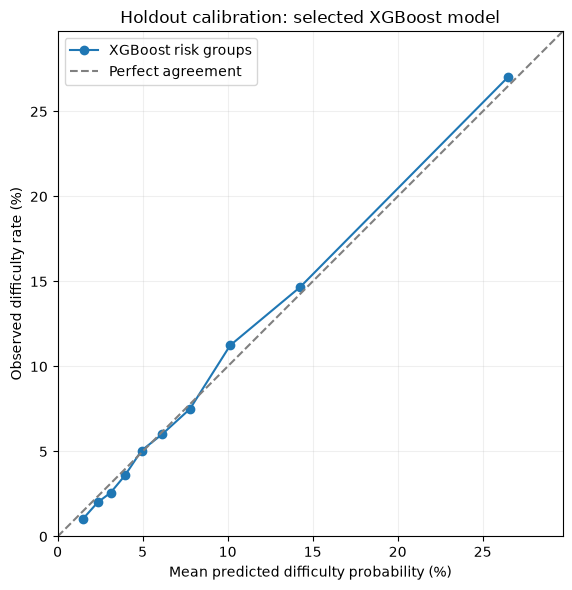

In [230]:
import matplotlib.pyplot as plt

# Retrieve the two group-average percentages.
predicted_pct = calibration_summary["MEAN_PREDICTED_PCT"]
actual_pct = calibration_summary["ACTUAL_DIFFICULTY_PCT"]

# Set matching axis limits that cover the displayed group averages.
axis_max = max(predicted_pct.max(), actual_pct.max()) * 1.1

fig, ax = plt.subplots(figsize=(7, 6))

# Plot the model's observed calibration relationship.
ax.plot(
    predicted_pct,
    actual_pct,
    marker="o",
    label="XGBoost risk groups"
)

# On this diagonal, predicted and observed percentages are equal.
ax.plot(
    [0, axis_max],
    [0, axis_max],
    linestyle="--",
    color="gray",
    label="Perfect agreement"
)

# Label both axes in percentage units.
ax.set_xlabel("Mean predicted difficulty probability (%)")
ax.set_ylabel("Observed difficulty rate (%)")
ax.set_title("Holdout calibration: selected XGBoost model")

# Keep horizontal and vertical distances comparable.
ax.set_xlim(0, axis_max)
ax.set_ylim(0, axis_max)
ax.set_aspect("equal", adjustable="box")

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

In [231]:
from pathlib import Path
from datetime import datetime
import json
import platform

import joblib
import numpy as np
import pandas as pd
import sklearn
import xgboost

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.utils.validation import check_is_fitted


# Check that the evaluated model and its supporting data exist.
required_variables = [
    "final_model",
    "final_feature_columns",
    "holdout_features",
    "holdout_predictions",
    "calibration_summary"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Required notebook objects are missing: "
        + ", ".join(missing_variables)
    )

# Check that preprocessing was fitted, rather than merely configured.
check_is_fitted(
    final_model.named_steps["imputer"],
    attributes=["statistics_"]
)

# Confirm that the saved input order matches the fitted pipeline.
assert (
    final_model.named_steps["imputer"].feature_names_in_.tolist()
    == list(final_feature_columns)
)

# Give each save its own folder to preserve earlier versions.
run_name = datetime.now().strftime("xgboost_%Y%m%d_%H%M%S")

artifact_dir = Path.cwd() / "artifacts" / run_name
artifact_dir.mkdir(parents=True, exist_ok=False)

# Calculate metrics directly from the existing holdout predictions.
# No model fitting or new predictions occur here.
holdout_metrics = {
    "applications": int(len(holdout_predictions)),
    "difficulty_cases": int(holdout_predictions["TARGET"].sum()),

    "roc_auc": float(roc_auc_score(
        holdout_predictions["TARGET"],
        holdout_predictions["PREDICTED_RISK"]
    )),

    "average_precision": float(average_precision_score(
        holdout_predictions["TARGET"],
        holdout_predictions["PREDICTED_RISK"]
    ))
}

print("Output folder:", artifact_dir.resolve())

Output folder: C:\Users\Raiyan Sulemani\Home credit default risk\artifacts\xgboost_20261102_233810


In [232]:
# Record the software versions used by this saved model.
package_versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "joblib": joblib.__version__
}

# Retrieve the configuration from the fitted XGBoost object.
model_parameters = final_model.named_steps["model"].get_params()

parameter_names = [
    "objective",
    "n_estimators",
    "max_depth",
    "learning_rate",
    "subsample",
    "colsample_bytree",
    "reg_lambda",
    "tree_method",
    "random_state",
    "n_jobs"
]

# Keep readable information about the model and its evaluation.
metadata = {
    "model_name": "Selected XGBoost pipeline",
    "target_column": "TARGET",
    "positive_class": 1,
    "input_type": "Engineered application-level features",
    "feature_columns": list(final_feature_columns),
    "package_versions": package_versions,
    "model_parameters": {
        name: model_parameters[name]
        for name in parameter_names
    },
    "holdout_metrics": holdout_metrics,
    "review_fraction": 0.10
}

# Bundle the fitted pipeline with its required column order.
model_bundle = {
    "pipeline": final_model,
    "feature_columns": list(final_feature_columns),
    "metadata": metadata
}

model_path = artifact_dir / "credit_risk_pipeline.joblib"

# Persist the objects using moderate compression.
joblib.dump(
    model_bundle,
    model_path,
    compress=3
)

# Also save metadata as readable text.
metadata_path = artifact_dir / "model_metadata.json"

with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(
        metadata,
        file,
        indent=2,
        allow_nan=False
    )

print("Model saved:", model_path)

Model saved: C:\Users\Raiyan Sulemani\Home credit default risk\artifacts\xgboost_20261102_233810\credit_risk_pipeline.joblib


In [233]:
# Save overall holdout metrics as a one-row CSV.
pd.DataFrame([holdout_metrics]).to_csv(
    artifact_dir / "holdout_metrics.csv",
    index=False
)

# Save the predicted-versus-observed risk comparison.
calibration_summary.to_csv(
    artifact_dir / "calibration_summary.csv",
    index=True
)

# Save the three-model comparison if it is still in this session.
if "three_model_comparison" in globals():
    three_model_comparison.to_csv(
        artifact_dir / "development_model_comparison.csv",
        index=True
    )

# Save the fixed 10% review-capacity results if available.
if "holdout_review_summary" in globals():
    holdout_review_summary.to_csv(
        artifact_dir / "holdout_review_summary.csv",
        index=False
    )

In [234]:
# Reload the file we just created.
loaded_bundle = joblib.load(model_path)

loaded_pipeline = loaded_bundle["pipeline"]
loaded_feature_columns = loaded_bundle["feature_columns"]

# Select a small verification batch.
probe_rows = holdout_features.head(100)

# Arrange inputs using the feature order stored with the model.
probe_inputs = probe_rows[
    loaded_feature_columns
].copy()

# Retrieve the original probabilities by application ID.
original_probabilities = (
    holdout_predictions
    .set_index("SK_ID_CURR")
    .loc[
        probe_rows["SK_ID_CURR"].tolist(),
        "PREDICTED_RISK"
    ]
    .to_numpy()
)

# Predict using the reloaded pipeline.
reloaded_probabilities = loaded_pipeline.predict_proba(
    probe_inputs
)[:, 1]

# Stop if the reloaded model produces materially different results.
np.testing.assert_allclose(
    reloaded_probabilities,
    original_probabilities,
    rtol=1e-6,
    atol=1e-8
)

print("Verified: reloaded pipeline reproduces the saved predictions.")
print("Files available in:", artifact_dir.resolve())

Verified: reloaded pipeline reproduces the saved predictions.
Files available in: C:\Users\Raiyan Sulemani\Home credit default risk\artifacts\xgboost_20261102_233810


In [235]:
import numpy as np
import pandas as pd

# Retrieve the fitted preprocessing and model steps.
fitted_imputer = final_model.named_steps["imputer"]
fitted_xgb = final_model.named_steps["model"]

# Retrieve all model-input names, including missingness indicators.
transformed_feature_names = fitted_imputer.get_feature_names_out(
    final_feature_columns
)

# Retrieve XGBoost's fitted tree ensemble.
booster = fitted_xgb.get_booster()

# Sum recorded split gains for each feature across the ensemble.
gain_scores = booster.get_score(
    importance_type="total_gain"
)

# XGBoost may store internal names such as f0, f1, and f2 when
# preprocessing supplies a NumPy array instead of a named DataFrame.
internal_feature_names = booster.feature_names

if internal_feature_names is None:
    internal_feature_names = [
        f"f{i}"
        for i in range(booster.num_features())
    ]

# Ensure internal names and readable names correspond by position.
assert len(internal_feature_names) == len(
    transformed_feature_names
)

assert set(gain_scores).issubset(
    set(internal_feature_names)
)

# Features absent from get_score had no recorded split gain.
raw_gains = np.array([
    gain_scores.get(name, 0.0)
    for name in internal_feature_names
])

assert raw_gains.sum() > 0

# Express each feature's total gain as a share of all recorded gains.
importance_table = pd.DataFrame({
    "FEATURE": transformed_feature_names,
    "TOTAL_GAIN": raw_gains,
    "GAIN_SHARE_PCT": (
        raw_gains / raw_gains.sum() * 100
    )
})

# Put the largest gain shares first.
importance_table = (
    importance_table
    .sort_values("GAIN_SHARE_PCT", ascending=False)
    .reset_index(drop=True)
)

display(importance_table.round(3))

,FEATURE,TOTAL_GAIN,GAIN_SHARE_PCT
0,EXT_SOURCE_3,43871.816,28.877
1,EXT_SOURCE_2,43391.328,28.560
2,EXT_SOURCE_1,13325.506,8.771
3,ANNUITY_CREDIT_RATIO,13201.855,8.690
4,CREDIT_GOODS_RATIO,8544.966,5.624
5,NOT_COVERED_ON_TIME_PCT,7236.814,4.763
6,DAYS_BIRTH,6308.372,4.152
7,EXCLUDED_ENTRIES,3501.057,2.304
8,ASSESSED_DUE_ENTRIES,3216.499,2.117
9,AMT_ANNUITY,2301.850,1.515


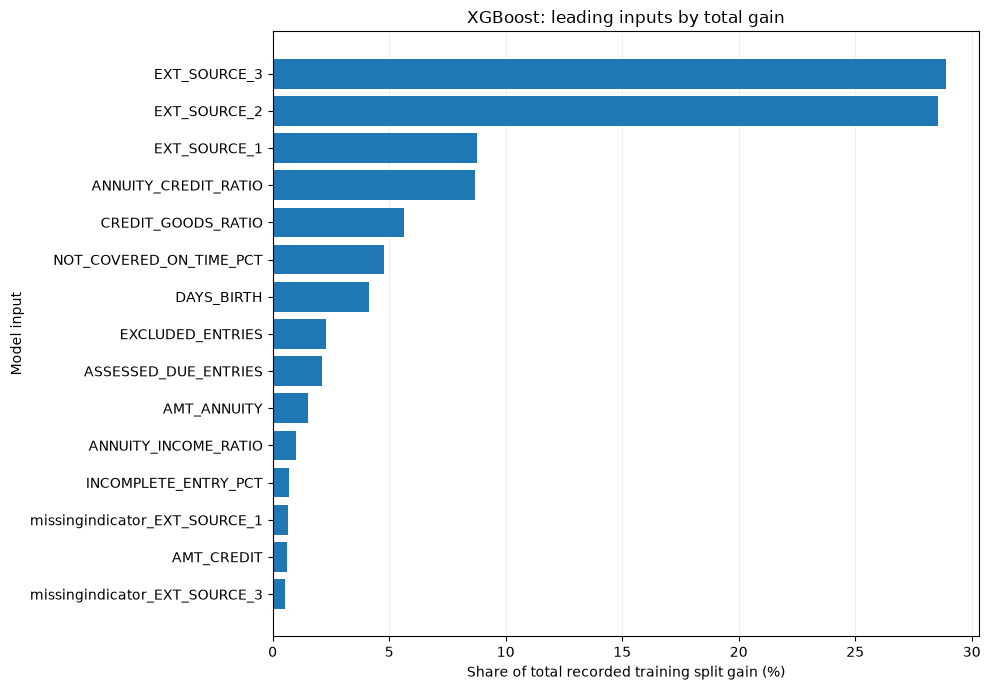

In [236]:
import matplotlib.pyplot as plt

# Select the 15 largest gain shares.
# Reverse the order so the largest bar appears at the top.
plot_data = (
    importance_table
    .head(15)
    .sort_values("GAIN_SHARE_PCT")
)

fig_importance, ax = plt.subplots(figsize=(10, 7))

# Draw one horizontal bar per model input.
ax.barh(
    plot_data["FEATURE"],
    plot_data["GAIN_SHARE_PCT"]
)

# Label the quantity being displayed precisely.
ax.set_xlabel("Share of total recorded training split gain (%)")
ax.set_ylabel("Model input")
ax.set_title("XGBoost: leading inputs by total gain")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [237]:
# Save alongside the model and evaluation results.
if "artifact_dir" in globals():

    importance_table.to_csv(
        artifact_dir / "feature_importance_total_gain.csv",
        index=False
    )

    fig_importance.savefig(
        artifact_dir / "feature_importance_total_gain.png",
        dpi=200,
        bbox_inches="tight"
    )

    print("Feature-importance outputs saved in:", artifact_dir)

Feature-importance outputs saved in: C:\Users\Raiyan Sulemani\Home credit default risk\artifacts\xgboost_20261102_233810


In [239]:
import numpy as np
import pandas as pd
import xgboost as xgb

# Select the highest predicted risk.
# Application ID provides a consistent tie-breaker.
case_record = (
    holdout_predictions
    .sort_values(
        ["PREDICTED_RISK", "SK_ID_CURR"],
        ascending=[False, True]
    )
    .iloc[0]
)

case_id = int(case_record["SK_ID_CURR"])

# Retrieve that application's original engineered inputs.
# Keep a DataFrame by selecting the ID inside a list.
case_inputs = (
    holdout_features
    .set_index("SK_ID_CURR")
    .loc[[case_id], final_feature_columns]
)

print("Application ID:", case_id)
print(f"Stored predicted risk: {case_record['PREDICTED_RISK']:.2%}")
print("Actual TARGET:", int(case_record["TARGET"]))

Application ID: 397023
Stored predicted risk: 74.12%
Actual TARGET: 0


In [240]:
# Retrieve the fitted preprocessing and model.
fitted_imputer = final_model.named_steps["imputer"]
fitted_xgb = final_model.named_steps["model"]

# Apply existing preprocessing without fitting it again.
processed_case = fitted_imputer.transform(case_inputs)

# Retrieve names for the transformed inputs, including missing flags.
explanation_feature_names = fitted_imputer.get_feature_names_out(
    final_feature_columns
)

# Access the fitted XGBoost ensemble.
booster = fitted_xgb.get_booster()

# DMatrix is XGBoost's input-data container.
# Preserve internal names if the booster has them.
case_matrix = xgb.DMatrix(
    processed_case,
    feature_names=booster.feature_names
)

# Request feature contributions for this application.
# The last output column contains the reference/bias term.
contribution_matrix = booster.predict(
    case_matrix,
    pred_contribs=True,
    approx_contribs=False
)

assert contribution_matrix.shape == (
    1,
    len(explanation_feature_names) + 1
)

# Select the single application's contribution vector.
contributions = contribution_matrix[0]

# Separate the reference score from feature contributions.
reference_raw_score = float(contributions[-1])
feature_contributions = contributions[:-1]

# Reconstruct the raw score from all contributions.
reconstructed_raw_score = float(
    contributions.sum(dtype=np.float64)
)

# Convert the reconstructed raw score into a probability.
reconstructed_probability = (
    1 / (1 + np.exp(-reconstructed_raw_score))
)

# Obtain the normal pipeline prediction for comparison.
pipeline_probability = float(
    final_model.predict_proba(case_inputs)[0, 1]
)

# Verify that the explanation reconstructs the pipeline prediction.
np.testing.assert_allclose(
    reconstructed_probability,
    pipeline_probability,
    rtol=1e-5,
    atol=1e-6
)

# Also verify that it matches our previously stored prediction.
np.testing.assert_allclose(
    pipeline_probability,
    float(case_record["PREDICTED_RISK"]),
    rtol=1e-5,
    atol=1e-6
)

print(f"Reference raw score: {reference_raw_score:.4f}")
print(f"Reconstructed probability: {reconstructed_probability:.2%}")
print(f"Pipeline probability: {pipeline_probability:.2%}")
print("Verified: contributions reconstruct the prediction.")

Reference raw score: -2.4423
Reconstructed probability: 74.12%
Pipeline probability: 74.12%
Verified: contributions reconstruct the prediction.


In [241]:
# Pair each transformed input with its value and contribution.
local_explanation = pd.DataFrame({
    "FEATURE": explanation_feature_names,

    # These are the values after median replacement and flag creation.
    "INPUT_VALUE_USED": processed_case[0],

    "SHAP_LOG_ODDS": feature_contributions
})

# Measure contribution size regardless of direction.
local_explanation["ABS_CONTRIBUTION"] = (
    local_explanation["SHAP_LOG_ODDS"].abs()
)

# Put the most influential inputs for this application first.
local_explanation = (
    local_explanation
    .sort_values("ABS_CONTRIBUTION", ascending=False)
    .reset_index(drop=True)
)

display(local_explanation.round(4))

,FEATURE,INPUT_VALUE_USED,SHAP_LOG_ODDS,ABS_CONTRIBUTION
0,EXT_SOURCE_3,0.0005,1.1109,1.1109
1,EXT_SOURCE_1,0.0792,0.8869,0.8869
2,EXT_SOURCE_2,0.1893,0.5328,0.5328
3,CREDIT_GOODS_RATIO,1.5280,0.4341,0.4341
4,ANNUITY_CREDIT_RATIO,0.0490,0.2923,0.2923
5,NOT_COVERED_ON_TIME_PCT,33.3333,0.1945,0.1945
6,ASSESSED_DUE_ENTRIES,12.0000,0.1275,0.1275
7,DAYS_BIRTH,-12383.0000,0.1046,0.1046
8,ANNUITY_INCOME_RATIO,0.0832,-0.0664,0.0664
9,missingindicator_EXT_SOURCE_1,0.0000,-0.0516,0.0516


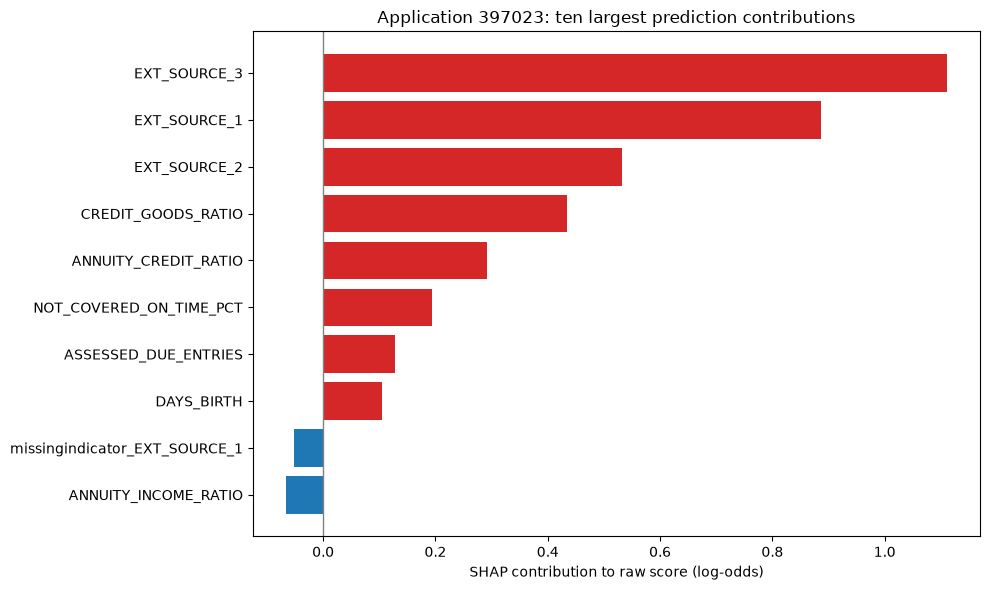

In [242]:
import matplotlib.pyplot as plt

# Show the ten largest contributions by absolute size.
plot_data = (
    local_explanation
    .head(10)
    .sort_values("SHAP_LOG_ODDS")
)

# Use colour alongside signed positions to show direction.
bar_colors = [
    "tab:red" if value > 0 else "tab:blue"
    for value in plot_data["SHAP_LOG_ODDS"]
]

fig_local, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data["FEATURE"],
    plot_data["SHAP_LOG_ODDS"],
    color=bar_colors
)

# Separate upward and downward contributions.
ax.axvline(0, color="gray", linewidth=1)

ax.set_xlabel("SHAP contribution to raw score (log-odds)")
ax.set_title(
    f"Application {case_id}: ten largest prediction contributions"
)

plt.tight_layout()
plt.show()

## Explaining model predictions

Individual SHAP explanations show which inputs contribute toward higher
or lower predicted risk for a particular application.

Global importance is summarized using mean absolute SHAP contributions
across a reproducible random sample of up to 2,000 holdout applications.

This explanation sample does not replace the full holdout evaluation.

Contributions are measured in log-odds. They explain the fitted model's
behaviour and do not establish causal relationships.

In [243]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

# Use up to 2,000 applications to summarize model explanations.
# This sample does not replace the full holdout performance evaluation.
explanation_sample_size = min(2000, len(holdout_features))

# random_state makes the random sample reproducible.
explanation_sample = holdout_features.sample(
    n=explanation_sample_size,
    random_state=42
).copy()

# Select the same inputs, in the same order, used to train the model.
sample_inputs = explanation_sample[final_feature_columns].copy()

# Retrieve the already-fitted preprocessing step and XGBoost model.
# We do not fit or train anything again.
fitted_imputer = final_model.named_steps["imputer"]
fitted_xgb = final_model.named_steps["model"]

# Apply the existing missing-value treatment.
# This also creates the missingness indicators learned during training.
processed_sample = fitted_imputer.transform(sample_inputs)

# Get names for the columns after preprocessing.
explanation_feature_names = fitted_imputer.get_feature_names_out(
    final_feature_columns
)

# Access the fitted XGBoost trees.
booster = fitted_xgb.get_booster()

# DMatrix is XGBoost's input container for its native prediction methods.
sample_matrix = xgb.DMatrix(
    processed_sample,
    feature_names=booster.feature_names
)

# Calculate exact tree SHAP contributions for each sampled application.
# The final column is the reference contribution, also called the bias.
sample_contributions = booster.predict(
    sample_matrix,
    pred_contribs=True,
    approx_contribs=False
)

# Check that the output contains one contribution per feature,
# plus the reference contribution.
assert sample_contributions.shape == (
    len(sample_inputs),
    len(explanation_feature_names) + 1
)

# Keep feature contributions separately from the final reference column.
sample_shap_values = sample_contributions[:, :-1]

print("Applications explained:", len(sample_inputs))
print("Inputs after preprocessing:", len(explanation_feature_names))



Applications explained: 2000
Inputs after preprocessing: 26


In [244]:
# Add the reference contribution and every feature contribution.
reconstructed_raw_scores = sample_contributions.sum(
    axis=1,
    dtype=np.float64
)

# Convert raw log-odds scores into probabilities using the sigmoid.
# This form is numerically stable for both positive and negative scores.
reconstructed_probabilities = np.exp(
    -np.logaddexp(0, -reconstructed_raw_scores)
)

# Get probabilities directly from the complete fitted pipeline.
pipeline_probabilities = final_model.predict_proba(sample_inputs)[:, 1]

# Allow tiny differences caused by floating-point arithmetic.
np.testing.assert_allclose(
    reconstructed_probabilities,
    pipeline_probabilities,
    rtol=1e-5,
    atol=1e-6
)

print("Check passed: SHAP contributions reconstruct the predictions.")

Check passed: SHAP contributions reconstruct the predictions.


,MEAN_ABS_SHAP
FEATURE,
EXT_SOURCE_2,0.3603
EXT_SOURCE_3,0.3372
NOT_COVERED_ON_TIME_PCT,0.1633
ANNUITY_CREDIT_RATIO,0.1584
EXT_SOURCE_1,0.1453
CREDIT_GOODS_RATIO,0.1439
ASSESSED_DUE_ENTRIES,0.1022
DAYS_BIRTH,0.0787
EXCLUDED_ENTRIES,0.0733


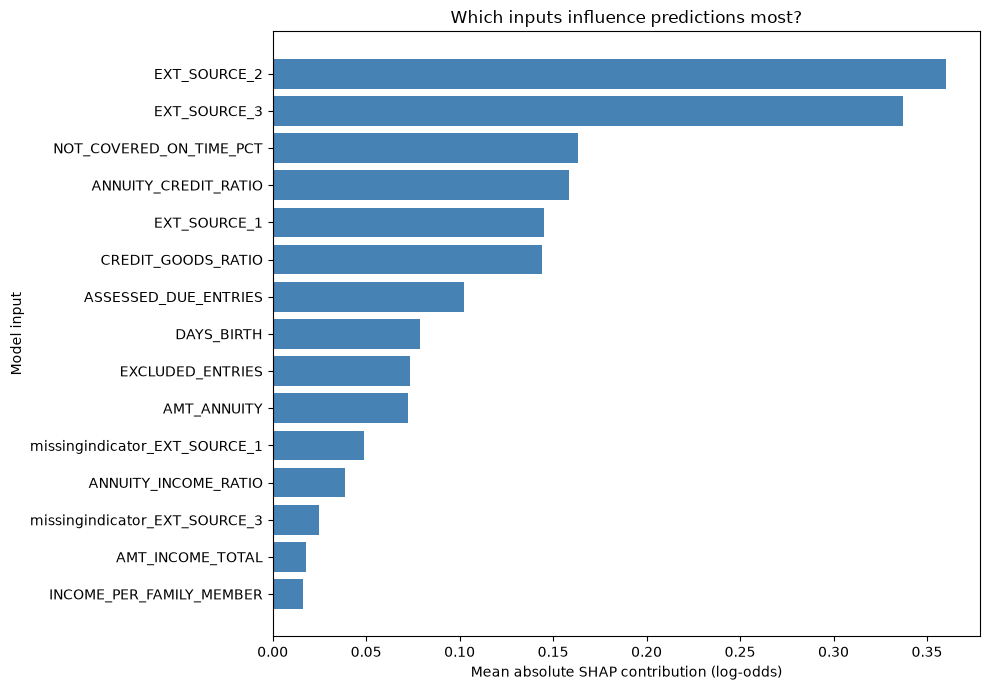

In [245]:
# Create a table with one row per application and one column per input.
sample_shap_table = pd.DataFrame(
    sample_shap_values,
    columns=explanation_feature_names
)

# abs() converts negative contributions into positive magnitudes.
# mean(axis=0) calculates the average down each feature's column.
global_shap_summary = (
    sample_shap_table
    .abs()
    .mean(axis=0)
    .rename("MEAN_ABS_SHAP")
    .to_frame()
    .sort_values("MEAN_ABS_SHAP", ascending=False)
)

# Give the table's row index a descriptive name.
global_shap_summary.index.name = "FEATURE"

display(global_shap_summary.round(4))

# Show the 15 inputs with the largest average contribution magnitudes.
# Sort ascending so the largest bar appears at the top of a horizontal plot.
plot_data = (
    global_shap_summary.head(15)
    .sort_values("MEAN_ABS_SHAP")
)

fig_global_shap, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_data.index,
    plot_data["MEAN_ABS_SHAP"],
    color="steelblue"
)

ax.set_xlabel("Mean absolute SHAP contribution (log-odds)")
ax.set_ylabel("Model input")
ax.set_title("Which inputs influence predictions most?")
fig_global_shap.tight_layout()

plt.show()

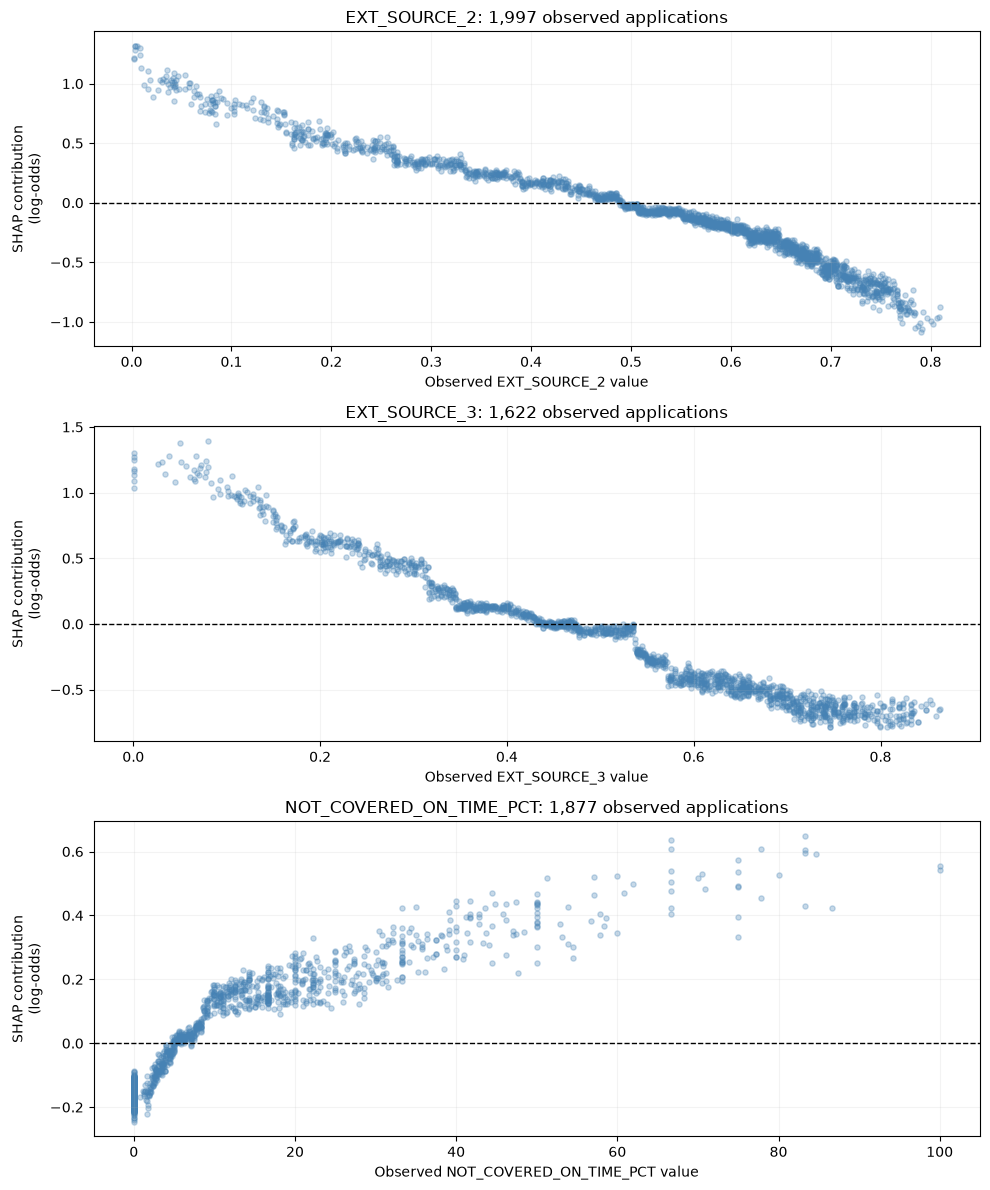

In [246]:
import matplotlib.pyplot as plt

# Examine the three leading features from your importance table.
features_to_explain = [
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "NOT_COVERED_ON_TIME_PCT"
]

# Reset row labels in both tables.
# Their row order already matches because SHAP used these same inputs.
plot_inputs = sample_inputs.reset_index(drop=True)
plot_contributions = sample_shap_table.reset_index(drop=True)

# Confirm that both tables contain the same number of applications.
assert len(plot_inputs) == len(plot_contributions)

# Create three charts arranged vertically.
# Each chart gets its own horizontal scale.
fig_dependence, axes = plt.subplots(
    nrows=len(features_to_explain),
    ncols=1,
    figsize=(10, 12)
)

# Pair each chart with the feature it will display.
for ax, feature in zip(axes, features_to_explain):

    # Use original observed values for the horizontal axis.
    feature_values = plot_inputs[feature]

    # Keep the signed SHAP contributions for this feature.
    feature_effects = plot_contributions[feature]

    # Plot only applications where the original value was available.
    # This avoids presenting imputed medians as observed values.
    observed = feature_values.notna()

    # Each dot represents one application.
    # Transparency makes overlapping dots easier to see.
    ax.scatter(
        feature_values.loc[observed],
        feature_effects.loc[observed],
        s=14,
        alpha=0.3,
        color="steelblue"
    )

    # Zero separates upward and downward contributions.
    ax.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    # Show how many applications have an observed value.
    ax.set_title(
        f"{feature}: {int(observed.sum()):,} observed applications"
    )

    ax.set_xlabel(f"Observed {feature} value")
    ax.set_ylabel("SHAP contribution\n(log-odds)")
    ax.grid(alpha=0.15)

# Add space between charts and display them.
fig_dependence.tight_layout()
plt.show()

In [247]:
import math
import pandas as pd

from sklearn.metrics import roc_auc_score, average_precision_score

# Copy the existing holdout predictions.
# This does not train or modify the model.
evaluation_data = holdout_predictions[
    ["SK_ID_CURR", "TARGET", "PREDICTED_RISK"]
].copy()

# Count applications and actual payment-difficulty cases.
total_applications = len(evaluation_data)
total_difficulty_cases = int(evaluation_data["TARGET"].sum())

# Baseline: the fraction of all holdout applications with TARGET = 1.
baseline_rate = total_difficulty_cases / total_applications

# Evaluate ranking across the complete holdout.
holdout_auc = roc_auc_score(
    evaluation_data["TARGET"],
    evaluation_data["PREDICTED_RISK"]
)

holdout_ap = average_precision_score(
    evaluation_data["TARGET"],
    evaluation_data["PREDICTED_RISK"]
)

# Reproduce our previously chosen review capacity: the highest-risk 10%.
# ceil rounds upward because we must select a whole number of applications.
review_count = math.ceil(0.10 * total_applications)

# Rank by predicted risk.
# Application ID provides a reproducible tie-breaker for equal scores.
ranked_applications = evaluation_data.sort_values(
    ["PREDICTED_RISK", "SK_ID_CURR"],
    ascending=[False, True]
)

# Select the applications that would receive additional review.
reviewed_applications = ranked_applications.head(review_count)

# Count actual difficulty cases among those selected.
cases_found = int(reviewed_applications["TARGET"].sum())

# Selected applications without recorded difficulty are false positives.
false_alarms = review_count - cases_found

# Actual difficulty cases outside the selected group are missed cases.
cases_missed = total_difficulty_cases - cases_found

# Precision: how many selected applications actually had difficulty?
review_precision = cases_found / review_count

# Recall: how many of all difficulty cases did we select?
review_recall = cases_found / total_difficulty_cases

# Lift: how concentrated are difficulty cases compared with the baseline?
review_lift = review_precision / baseline_rate

# Use a vertical table so the results are easy to read.
final_holdout_summary = pd.DataFrame(
    {
        "VALUE": [
            total_applications,
            total_difficulty_cases,
            baseline_rate * 100,
            holdout_auc,
            holdout_ap,
            review_count,
            cases_found,
            false_alarms,
            cases_missed,
            review_precision * 100,
            review_recall * 100,
            review_lift
        ]
    },
    index=[
        "Holdout applications",
        "Actual difficulty cases",
        "Baseline difficulty rate (%)",
        "Holdout ROC AUC",
        "Holdout average precision",
        "Applications selected for review",
        "Difficulty cases found",
        "False alarms",
        "Difficulty cases missed",
        "Review precision (%)",
        "Review recall (%)",
        "Lift"
    ]
)

display(final_holdout_summary.round(4))

,VALUE
Holdout applications,61303.0000
Actual difficulty cases,4946.0000
Baseline difficulty rate (%),8.0681
Holdout ROC AUC,0.7605
Holdout average precision,0.2383
Applications selected for review,6131.0000
Difficulty cases found,1656.0000
False alarms,4475.0000
Difficulty cases missed,3290.0000
Review precision (%),27.0103


## Results and findings

### Model development

Models were compared using five-fold stratified cross-validation
on the development partition.

| Model | Mean validation ROC AUC | Mean validation average precision |
|---|---:|---:|
| Logistic regression | 0.7370 | 0.2177 |
| Random forest | 0.7466 | 0.2304 |
| XGBoost | 0.7561 | 0.2427 |

XGBoost was selected using development results. Its fixed pipeline
was then fitted on the development partition and evaluated on the
reserved holdout. Holdout results appear in the table above.

### Review prioritization

Selecting the highest-risk 10% of holdout applications identified
1,656 of 4,946 recorded payment-difficulty cases.

Precision was 27.01%, recall was 33.48%, and lift was approximately
3.35 relative to the overall holdout difficulty rate.

These results describe a simulated review queue. They do not measure
the effect of a real intervention or demonstrate financial savings.

### Model interpretation

In the SHAP explanation sample, EXT_SOURCE_2 and EXT_SOURCE_3 had
the largest average absolute contributions.

Repayment timeliness and loan ratios also contributed substantially.
The strongest repayment input was NOT_COVERED_ON_TIME_PCT.

SHAP describes how inputs contribute to the fitted model's predictions.
It does not establish that those inputs cause repayment difficulty.

### Limitations

- Validation used a random historical split; performance on future
  applications has not been established.
- Missing and excluded repayment records limit the available evidence.
- No recorded repayment history does not imply perfect repayment.
- Correlated inputs can share or substitute for one another's contributions.
- Group-level calibration does not guarantee accurate probabilities
  for every individual application.
- The model has not been validated for live lending decisions.

In [248]:
from pathlib import Path
import pandas as pd

# Create the project folder inside the notebook's current working directory.
project_dir = Path.cwd() / "home-credit-default-risk"

# Separate the notebook, numerical results, and chart images.
notebooks_dir = project_dir / "notebooks"
reports_dir = project_dir / "reports"
figures_dir = project_dir / "figures"

# parents=True creates any missing parent folders.
# exist_ok=True allows us to run the cell again.
for folder in [notebooks_dir, reports_dir, figures_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# Map each output filename to its existing notebook variable.
tables_to_export = {
    "holdout_results.csv": "final_holdout_summary",
    "model_comparison_cv.csv": "three_model_comparison",
    "calibration_by_risk_group.csv": "calibration_summary",
    "global_shap_importance.csv": "global_shap_summary"
}

# Check that the required tables exist before exporting anything.
missing_tables = [
    variable_name
    for variable_name in tables_to_export.values()
    if variable_name not in globals()
]

if missing_tables:
    raise RuntimeError(
        "Run the cells that create these tables first: "
        + ", ".join(missing_tables)
    )

# Record the files successfully exported during this run.
exported_files = []

# Save each table as a CSV file.
for filename, variable_name in tables_to_export.items():

    # globals() retrieves the notebook variable using its name.
    table = globals()[variable_name]
    output_path = reports_dir / filename

    # Preserve the index because it contains metric or feature names.
    table.to_csv(output_path, index=True)

    exported_files.append(output_path)

# Save the ordered list of original model inputs.
feature_list_path = reports_dir / "model_input_features.csv"

pd.DataFrame(
    {"FEATURE": final_feature_columns}
).to_csv(feature_list_path, index=False)

exported_files.append(feature_list_path)

# Map chart filenames to figure objects created in earlier cells.
figures_to_export = {
    "training_gain_importance.png": "fig_importance",
    "global_shap_importance.png": "fig_global_shap",
    "individual_shap_explanation.png": "fig_local",
    "shap_dependence_plots.png": "fig_dependence"
}

# Save each available chart.
for filename, variable_name in figures_to_export.items():

    if variable_name in globals():
        figure = globals()[variable_name]
        output_path = figures_dir / filename

        # Higher resolution makes chart labels clearer in the portfolio.
        figure.savefig(
            output_path,
            dpi=200,
            bbox_inches="tight",
            facecolor="white"
        )

        exported_files.append(output_path)

    else:
        print(f"Chart unavailable; run its plotting cell: {variable_name}")

# Show the output location and files created.
print("Project folder:", project_dir.resolve())

display(
    pd.DataFrame({
        "EXPORTED_FILE": [
            str(path.relative_to(project_dir))
            for path in exported_files
        ]
    })
)

Project folder: C:\Users\Raiyan Sulemani\Home credit default risk\home-credit-default-risk


,EXPORTED_FILE
0,reports\holdout_results.csv
1,reports\model_comparison_cv.csv
2,reports\calibration_by_risk_group.csv
3,reports\global_shap_importance.csv
4,reports\model_input_features.csv
5,figures\training_gain_importance.png
6,figures\global_shap_importance.png
7,figures\individual_shap_explanation.png
8,figures\shap_dependence_plots.png


In [249]:
from pathlib import Path

# Keep the dataset location independent of the notebook's folder.
data_dir = Path(r"C:\home credit data")

# Check that this folder exists on your computer.
print("Data folder exists:", data_dir.exists())

Data folder exists: True


# Home Credit Default Risk

Exploratory analysis and machine learning to predict payment difficulty,
with repayment-history feature engineering and a simulated review queue.

## Objective

Estimate payment difficulty for current Home Credit applications and
evaluate whether ranking applications by predicted risk can help
prioritize additional review.

The outcome is the dataset's TARGET label. The project does not measure
the effect of an intervention or implement an automatic lending decision.

## Dataset

Source: [Home Credit Default Risk — Kaggle](https://www.kaggle.com/competitions/home-credit-default-risk/data)

The labelled application table contains 307,511 applications.

### Data used in this version

| Source | Use |
|---|---|
| application_train.csv | Application features, target, development and holdout partitions |
| installments_payments.csv | Engineered repayment-history features |
| previous_application.csv | Exploratory analysis and early feature experiments |
| bureau.csv | Exploratory analysis of external credit records |

The selected final model uses application and instalment-history inputs.

Monthly bureau, POS/cash, and credit-card histories are potential
extensions. Competition test predictions and a Kaggle submission have
not been produced in this version.

Raw datasets are obtained separately from Kaggle.

## Approach

1. Explore application, previous-application, and credit-history data.
2. Define conservative rules for assessing recorded instalment repayments.
3. Engineer application ratios and applicant-level repayment summaries.
4. Compare feature sets and classification algorithms.
5. Evaluate the selected model on a reserved holdout.
6. Examine review prioritization, group-level calibration, and SHAP explanations.

### Selected inputs

The final model uses 16 original inputs:

- Four basic application inputs.
- Three external scores.
- Five application ratios.
- Four repayment-history inputs.

Missing numeric inputs are imputed using training-data medians.
Missingness indicators are added where applicable.

## Validation

- Development applications: 246,208.
- Holdout applications: 61,303.
- Model comparison: five-fold stratified cross-validation on development data.
- Preprocessing is fitted within each training fold.

### Development cross-validation results

| Model | Mean ROC AUC | Mean average precision |
|---|---:|---:|
| Logistic regression | 0.7370 | 0.2177 |
| Random forest | 0.7466 | 0.2304 |
| XGBoost | 0.7561 | 0.2427 |

XGBoost was selected using development results.

Full holdout metrics are available in
[holdout_results.csv](reports/holdout_results.csv).

## Simulated review queue

Applications were ranked by predicted risk. The highest-risk 10% were
selected for additional review.

| Measure | Holdout result |
|---|---:|
| Applications selected | 6,131 |
| Difficulty cases identified | 1,656 |
| False positives | 4,475 |
| Difficulty cases outside the selected group | 3,290 |
| Precision | 27.01% |
| Recall | 33.48% |
| Lift relative to overall difficulty rate | 3.35 |

Approximately 27% of selected applications had recorded difficulty,
compared with approximately 8% across the holdout.

These results describe historical selection performance. They do not
demonstrate financial savings or improved repayment outcomes.

## Model interpretation

In the explanation sample, EXT_SOURCE_2 and EXT_SOURCE_3 had the largest
mean absolute SHAP contributions.

Repayment timeliness and loan ratios also contributed substantially.
NOT_COVERED_ON_TIME_PCT was the leading repayment-history input.

![Global SHAP importance](figures/global_shap_importance.png)

SHAP explanations describe model behaviour rather than causes of
payment difficulty.

## Project files

| Location | Contents |
|---|---|
| notebooks/ | Analysis and modelling notebook, plus repayment feature helper |
| reports/ | Model comparisons, holdout metrics, calibration and feature summaries |
| figures/ | Exported explanation charts |
| requirements.txt | Versions of the principal Python dependencies |

## Running the project

1. Download the original data from Kaggle.
2. Install the dependencies listed in requirements.txt.
3. Open notebooks/01_home_credit_analysis_and_modeling.ipynb in Jupyter.
4. Update the notebook's data paths for your computer.
5. Keep home_credit_repayment_features.py beside the notebook.
6. Run the notebook in order.

The repayment feature builder uses temporary disk storage. Processing
the complete repayment table can take time.

## Limitations

- Random historical validation does not establish future performance.
- Recorded histories can be incomplete or require exclusion.
- No assessable history does not imply perfect repayment.
- Correlated inputs can share or substitute for one another's contributions.
- Group-average calibration does not guarantee individual probability accuracy.
- Additional data sources may improve performance but require controlled testing.
- The model has not been validated for live lending decisions.

## Tools

Python, pandas, NumPy, scikit-learn, XGBoost, Matplotlib, Jupyter,
SQLite, and joblib.

In [250]:
from importlib.metadata import version
from pathlib import Path

# Reuse the project directory created by our export cell.
# This avoids accidentally creating another nested project folder.
if "project_dir" not in globals():
    raise RuntimeError(
        "Run the project-folder and results-export cell first."
    )

project_dir = Path(project_dir)

# Record the installed versions of the principal notebook dependencies.
# These versions come from your computer; they are not guessed.
packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "xgboost",
    "matplotlib",
    "joblib",
    "ipykernel"
]

requirements_text = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

# Save the dependency list at the project root.
(project_dir / "requirements.txt").write_text(
    requirements_text,
    encoding="utf-8"
)

# Ignore local datasets, model binaries, and temporary files when using Git.
# Aggregate result CSVs in reports/ remain eligible for tracking.
gitignore_text = """# Local datasets and model artifacts
data/
artifacts/
*.csv
!reports/*.csv
*.parquet
*.joblib
*.pkl
*.sqlite
*.sqlite3
*.db
*.zip

# Python and Jupyter temporary files
__pycache__/
.ipynb_checkpoints/
.venv/

# Local environment configuration
.env
.env.*
"""

# Preserve an existing .gitignore rather than replacing custom rules.
gitignore_path = project_dir / ".gitignore"

if not gitignore_path.exists():
    gitignore_path.write_text(gitignore_text, encoding="utf-8")
else:
    print("Existing .gitignore preserved; check its rules.")

print("Project folder:", project_dir.resolve())
print("Dependency file created: requirements.txt")

Project folder: C:\Users\Raiyan Sulemani\Home credit default risk\home-credit-default-risk
Dependency file created: requirements.txt
